In [1]:
from pathlib import Path

SEG_EVAL_DIR = Path("/mnt/c/Users/juhe9/repos/MasterThesis/ForkSight/Data/evaluation_output/segmentation/20260428_101251")

# Junction detection result dirs (output of compute_metrics_junction_detection.py),
# one entry per dataset: {dataset name: dir}
JD_EVAL_DIRS = {
    "real": Path("/mnt/c/Users/juhe9/repos/MasterThesis/ForkSight/Data/evaluation_output/junction_detection/20260428_114907"),
    "synthetic": Path("/mnt/c/Users/juhe9/repos/MasterThesis/ForkSight/Data/evaluation_output/junction_detection_synthetic/20261019_230516"),
}
# Dataset used for the confusion matrices and the segmentation correlation analysis
JD_PRIMARY = "real"
JD_EVAL_DIR = JD_EVAL_DIRS[JD_PRIMARY]

# Fiber density analysis: synthetic datasets (keys of JD_EVAL_DIRS) and baseline results
SYNTH_JD_DATASETS = ["synthetic"]
SYNTH_BASELINE_CSV = Path("/mnt/c/Users/juhe9/repos/MasterThesis/ForkSight/Data/evaluation_output/synthetic_density.csv")

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

In [3]:
def bold_best(df: pd.DataFrame, lower_is_better_cols: set[str] | None = None):
    """Return a Styler that bolds the best value in each column."""
    lower_is_better_cols = lower_is_better_cols or set()

    def _apply(s: pd.Series) -> list[str]:
        numeric = pd.to_numeric(s, errors="coerce")
        want_min = s.name in lower_is_better_cols
        best = numeric.min() if want_min else numeric.max()
        return [
            "font-weight: bold" if (not np.isnan(v) and v == best) else ""
            for v in numeric
        ]

    float_cols = df.select_dtypes(include="number").columns
    fmt = {c: "{:.4f}" for c in float_cols}
    return (
        df.style
        .apply(_apply, axis=0)
        .format(fmt, na_rep="–")
        .set_table_styles([{"selector": "th, td", "props": "font-family: inherit; font-size: inherit;"}])
    )


def horizontal_bar_groups(df: pd.DataFrame, col_groups: list[tuple],
                          lower_is_better: set[str] | None = None,
                          col_rename: dict | None = None,
                          ylim: tuple | None = (0, 1.18),
                          cols_per_row: int | None = None,
                          suptitle: str = "") -> None:
    """Bar chart grid, one subplot per column group.  Legend is placed above the figure.

    Parameters
    ----------
    ylim         : (ymin, ymax) or None to auto-scale each subplot independently.
    cols_per_row : max subplots per row; None keeps all groups in a single row.
    """
    from matplotlib.gridspec import GridSpec

    lower_is_better = lower_is_better or set()
    col_rename = col_rename or {}

    filtered_groups = [
        [c for c in group if c in df.columns]
        for group in col_groups
    ]
    filtered_groups = [g for g in filtered_groups if g]
    if not filtered_groups:
        print("  (no columns available for bar chart)")
        return

    model_labels = [str(n) for n in df.index]
    total_cols = sum(len(g) for g in filtered_groups)
    colors = plt.cm.tab10(np.linspace(0, 0.9, len(df)))

    # Split groups into rows
    cpr = cols_per_row or len(filtered_groups)
    row_chunks = [filtered_groups[i:i + cpr]
                  for i in range(0, len(filtered_groups), cpr)]
    n_rows = len(row_chunks)

    ncol = min(len(df), 4)
    n_legend_rows = (len(df) + ncol - 1) // ncol
    top_gap = 0.05 * n_legend_rows + (0.07 if suptitle else 0.03)
    subplot_top = 1.2 - top_gap

    row_height = max(4, len(df) * 0.5 + 1.5)
    fig_width = max(10, 2.0 * total_cols)
    fig_height = row_height * n_rows

    fig = plt.figure(figsize=(fig_width, fig_height))
    outer_gs = GridSpec(n_rows, 1, figure=fig, hspace=0.45)

    first_handles, first_labels = None, None

    for row_idx, chunk in enumerate(row_chunks):
        width_ratios = [len(g) for g in chunk]
        inner_gs = outer_gs[row_idx].subgridspec(
            1, len(chunk), width_ratios=width_ratios, wspace=0.3)

        for ci, cols in enumerate(chunk):
            ax = fig.add_subplot(inner_gs[0, ci])
            x = np.arange(len(cols))
            width = 0.8 / max(len(df), 1)

            bars_by_col: dict[int, list[tuple]] = {k: [] for k in range(len(cols))}

            for i, (model, row) in enumerate(df.iterrows()):
                vals = [float(row.get(c, np.nan)) for c in cols]
                offset = (i - len(df) / 2 + 0.5) * width
                rects = ax.bar(x + offset, vals, width * 0.9,
                               label=model_labels[i], color=colors[i])
                for k, (rect, val) in enumerate(zip(rects, vals)):
                    bars_by_col[k].append((val, rect))

            if first_handles is None:
                first_handles, first_labels = ax.get_legend_handles_labels()

            # Annotation offset relative to data range
            all_vals = [v for entries in bars_by_col.values()
                        for v, _ in entries if not np.isnan(v)]
            y_range = (max(all_vals) - min(all_vals)) if len(all_vals) >= 2 else 1.0
            ann_offset = y_range * 0.025

            for k, col in enumerate(cols):
                entries = [(v, r) for v, r in bars_by_col[k] if not np.isnan(v)]
                if not entries:
                    continue
                want_min = col in lower_is_better
                best_val, best_rect = (min(entries, key=lambda t: t[0]) if want_min
                                       else max(entries, key=lambda t: t[0]))
                bar_x = best_rect.get_x() + best_rect.get_width() / 2
                ax.text(bar_x, best_rect.get_height() + ann_offset,
                        f"{best_val:.3f}",
                        ha="center", va="bottom", fontsize=7, fontweight="bold")

            tick_labels = [col_rename.get(c, c).replace(" ", "\n") for c in cols]
            ax.set_xticks(x)
            ax.set_xticklabels(tick_labels, fontsize=8)
            ax.grid(axis="y", linestyle="--", alpha=0.4)

            if ylim is not None:
                ax.set_ylim(*ylim)
            else:
                if all_vals:
                    ax.set_ylim(0, max(all_vals) + y_range * 0.15)

    plt.tight_layout(rect=[0, 0, 1, subplot_top])
    fig.legend(
        first_handles, first_labels,
        loc="lower center",
        bbox_to_anchor=(0.5, subplot_top),
        ncol=ncol,
        fontsize=8,
        framealpha=0.8,
    )
    if suptitle:
        fig.suptitle(suptitle, fontsize=12, y=0.99)

    plt.show()
    plt.close()

In [4]:
# Load segmentation metrics
_seg_csv = SEG_EVAL_DIR / "csv" / "metrics.csv"
if _seg_csv is None:
    raise FileNotFoundError(
        f"metrics.csv not found in {SEG_EVAL_DIR} or {SEG_EVAL_DIR / 'csv'}")

df_seg = pd.read_csv(_seg_csv, index_col=0)
df_seg.index.name = "Model"
print(f"Loaded segmentation metrics: {len(df_seg)} model(s) from {_seg_csv}")
df_seg.index = df_seg.index.map(str)  # ensure string index

# Optional: persistence distances
_dist_csv = SEG_EVAL_DIR / "csv" / "persistence_distances.csv"
df_dist = pd.read_csv(_dist_csv) if _dist_csv else pd.DataFrame()
if not df_dist.empty:
    print(f"Loaded persistence distances: {len(df_dist)} row(s)")

Loaded segmentation metrics: 17 model(s) from /mnt/c/Users/juhe9/repos/MasterThesis/ForkSight/Data/evaluation_output/segmentation/20260428_101251/csv/metrics.csv
Loaded persistence distances: 1173 row(s)


### Segmentation Metrics — Raw

In [5]:
SEG_RAW_COLS = ["Dice", "IoU", "clDice", "tprec", "tsens"]

_raw_cols = [c for c in SEG_RAW_COLS if c in df_seg.columns]
if _raw_cols:
    display(bold_best(df_seg[_raw_cols],))
else:
    print("No raw segmentation columns found.")

,Dice,IoU,clDice,tprec,tsens
Model,,,,,
sweep-skeleton-recall-lora-BEST,0.8770,0.7826,0.9728,0.9601,0.9882
sweep-skeleton-recall-n-blocks-BEST,0.8759,0.7810,0.9731,0.9663,0.9817
sweep-clDice-n-blocks-BEST,0.8682,0.7686,0.9760,0.9734,0.9798
sweep-cldice-lora-BEST,0.8668,0.7664,0.9773,0.9746,0.9811
sweep-skeleton-recall-BEST,0.8546,0.7474,0.9478,0.9293,0.9685
sweep-cldice-BEST,0.8435,0.7313,0.9576,0.9619,0.9554
SAM_LoRA_HuTopoLoss,0.8757,0.7799,0.9754,0.9797,0.9730
SAM_LoRA_BCE_Dice_Only,0.8736,0.7769,0.9730,0.9679,0.9795
SAM_LoRA_Ablation_100_100,0.8771,0.7828,0.9747,0.9777,0.9733


### Segmentation Metrics — Post-processed

In [6]:
SEG_PP_COLS = [
    "Dice Postprocessed", "IoU Postprocessed", "clDice Postprocessed",
    "tprec Postprocessed", "tsens Postprocessed",
]

_pp_cols = [c for c in SEG_PP_COLS if c in df_seg.columns]
if _pp_cols:
    display(bold_best(df_seg[_pp_cols]))
else:
    print("No post-processed segmentation columns found.")

,Dice Postprocessed,IoU Postprocessed,clDice Postprocessed,tprec Postprocessed,tsens Postprocessed
Model,,,,,
sweep-skeleton-recall-lora-BEST,0.8771,0.7827,0.9732,0.9610,0.9881
sweep-skeleton-recall-n-blocks-BEST,0.8761,0.7812,0.9740,0.9680,0.9816
sweep-clDice-n-blocks-BEST,0.8683,0.7687,0.9764,0.9744,0.9797
sweep-cldice-lora-BEST,0.8669,0.7665,0.9775,0.9751,0.9810
sweep-skeleton-recall-BEST,0.8555,0.7487,0.9529,0.9394,0.9678
sweep-cldice-BEST,0.8439,0.7318,0.9593,0.9657,0.9548
SAM_LoRA_HuTopoLoss,0.8758,0.7800,0.9758,0.9804,0.9729
SAM_LoRA_BCE_Dice_Only,0.8737,0.7772,0.9741,0.9704,0.9791
SAM_LoRA_Ablation_100_100,0.8771,0.7829,0.9750,0.9784,0.9731


### Segmentation Metrics — Topological (Persistence Distances)

Lower is better for all distance metrics.

In [7]:
SEG_TOPO_COLS = [
    "Wasserstein B0 Raw", "Bottleneck B0 Raw",
    "Wasserstein B1 Raw", "Bottleneck B1 Raw",
    "Wasserstein B0 SDT", "Bottleneck B0 SDT",
    "Wasserstein B1 SDT", "Bottleneck B1 SDT",
]

_topo_cols = [c for c in SEG_TOPO_COLS if c in df_seg.columns]
if _topo_cols:
    display(bold_best(df_seg[_topo_cols], lower_is_better_cols=set(_topo_cols)))
else:
    print("No topological metric columns found.")

,Wasserstein B0 Raw,Bottleneck B0 Raw,Wasserstein B1 Raw,Bottleneck B1 Raw,Wasserstein B0 SDT,Bottleneck B0 SDT,Wasserstein B1 SDT,Bottleneck B1 SDT
Model,,,,,,,,
sweep-skeleton-recall-lora-BEST,1.3809,0.3392,0.1879,0.0940,140.1498,34.1256,44.4584,9.5100
sweep-skeleton-recall-n-blocks-BEST,1.9722,0.3241,0.2620,0.1225,121.3922,29.8662,44.0119,10.3242
sweep-clDice-n-blocks-BEST,1.4427,0.3593,0.1884,0.0947,136.5918,32.9381,49.3589,10.3841
sweep-cldice-lora-BEST,0.8152,0.2831,0.1464,0.0936,123.9356,30.8161,41.0637,9.1553
sweep-skeleton-recall-BEST,12.6706,0.4612,0.9011,0.1798,406.4885,58.3922,105.3669,18.9693
sweep-cldice-BEST,5.9364,0.4679,0.3613,0.1544,315.4159,49.2827,82.6972,16.8720
SAM_LoRA_HuTopoLoss,1.0096,0.3112,0.1805,0.0922,136.2022,36.6691,43.7113,9.2200
SAM_LoRA_BCE_Dice_Only,2.8193,0.3749,0.2628,0.1004,167.4289,41.6850,50.4394,10.7419
SAM_LoRA_Ablation_100_100,1.0626,0.3409,0.1745,0.0945,153.7374,38.4014,45.9221,11.0284


### Segmentation Bar Charts

/tmp/ipykernel_265415/3947799005.py:127: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, subplot_top])


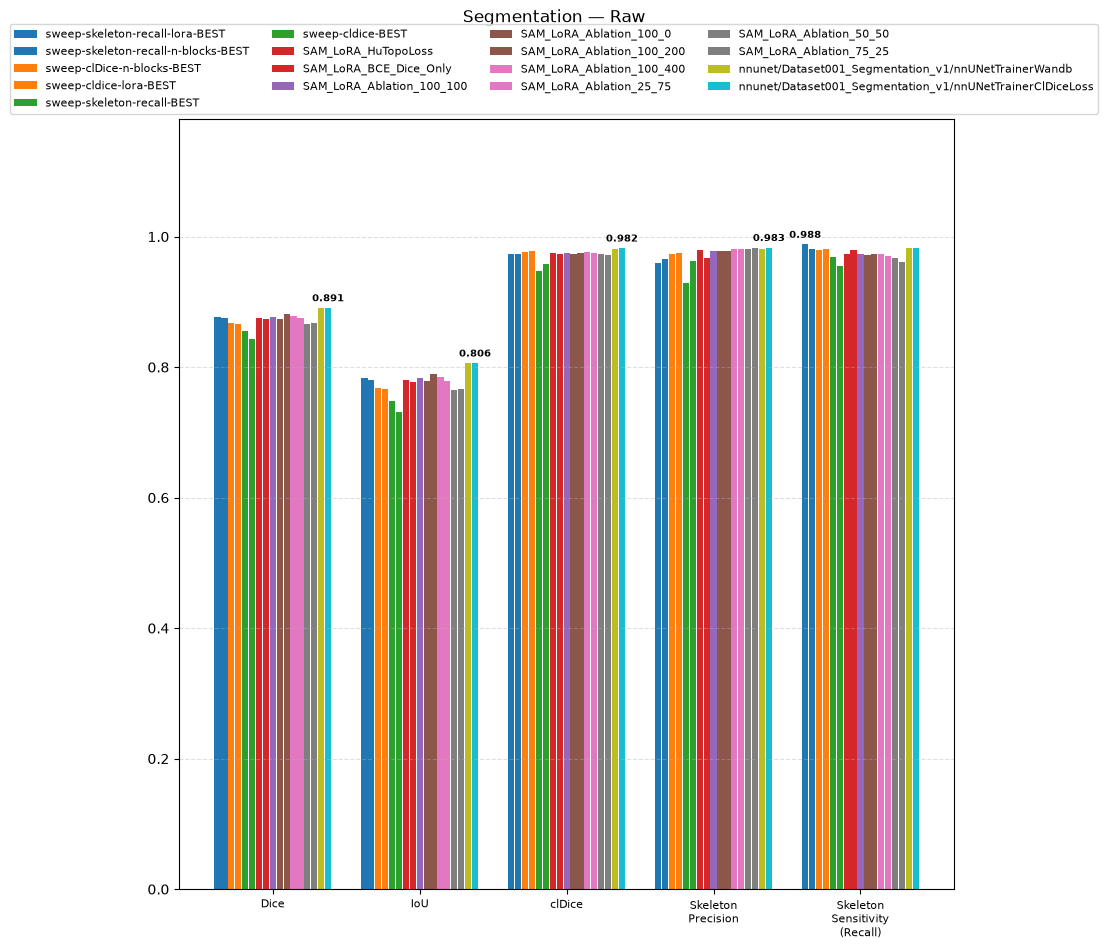

/tmp/ipykernel_265415/3947799005.py:127: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, subplot_top])


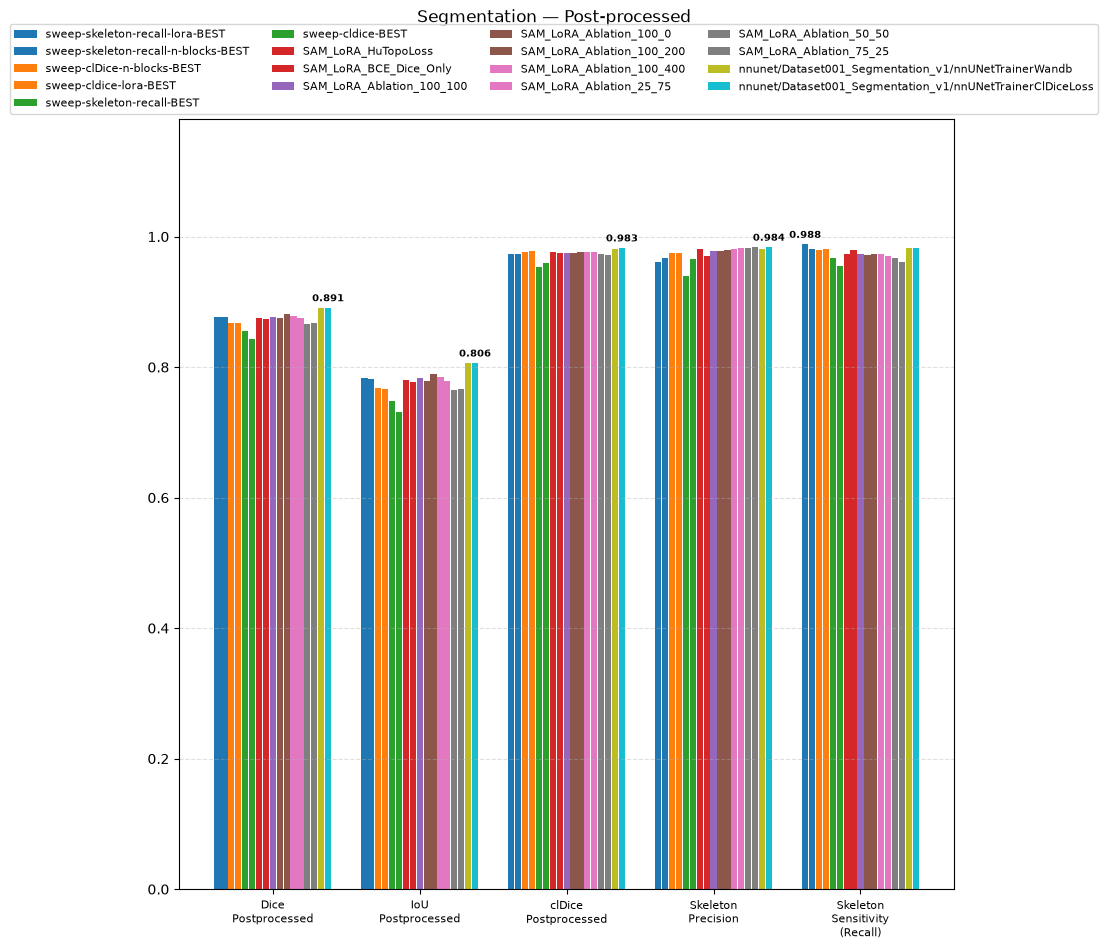

In [8]:
_SEG_RENAME = {
    "tprec": "Skeleton\nPrecision",
    "tsens": "Skeleton Sensitivity\n(Recall)",
    "tprec Postprocessed": "Skeleton\nPrecision",
    "tsens Postprocessed": "Skeleton Sensitivity\n(Recall)",
}

horizontal_bar_groups(
    df_seg,
    col_groups=[("Dice", "IoU", "clDice", "tprec", "tsens")],
    col_rename=_SEG_RENAME,
    suptitle="Segmentation — Raw",
)

horizontal_bar_groups(
    df_seg,
    col_groups=[("Dice Postprocessed", "IoU Postprocessed", "clDice Postprocessed",
                 "tprec Postprocessed", "tsens Postprocessed")],
    col_rename=_SEG_RENAME,
    suptitle="Segmentation — Post-processed",
)

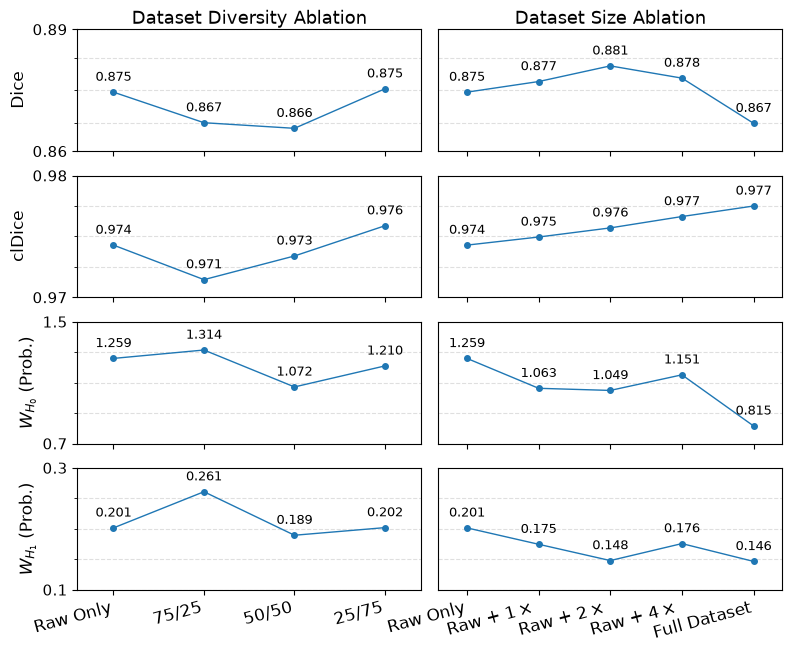

In [9]:
# ── Combined ablation grid: all four metrics × two ablations ─────────────────
_ABL_GROUP1 = [
    "SAM_LoRA_Ablation_100_0",
    "SAM_LoRA_Ablation_75_25",
    "SAM_LoRA_Ablation_50_50",
    "SAM_LoRA_Ablation_25_75",
]
_ABL_GROUP2 = [
    "SAM_LoRA_Ablation_100_0",
    "SAM_LoRA_Ablation_100_100",
    "SAM_LoRA_Ablation_100_200",
    "SAM_LoRA_Ablation_100_400",
    "sweep-cldice-lora-BEST",
]
_ABL_GROUP_LABELS = [
    "Dataset Diversity Ablation",
    "Dataset Size Ablation",
]

# (column, y-label, decimals, force_ymin, force_ymax)
_ABL_ALL_METRICS = [
    ("Dice Postprocessed",   "Dice",                    2, 0.860, None),
    ("clDice Postprocessed", "clDice",                  3, None,  0.980),
    ("Wasserstein B0 Raw",   r"$W_{H_0}$ (Prob.)",      2, 0.7,   1.5),
    ("Wasserstein B1 Raw",   r"$W_{H_1}$ (Prob.)",      2, 0.1,   0.3),
]

_FIG_DIR = Path("figures")
_FIG_DIR.mkdir(exist_ok=True)

_AUG_MULT = {"100": r"$1\times$", "200": r"$2\times$", "400": r"$4\times$"}

def _abl_label(name):
    if name == "sweep-cldice-lora-BEST":
        return "Full Dataset"
    if name.startswith("SAM_LoRA_Ablation_"):
        parts = name.removeprefix("SAM_LoRA_Ablation_").split("_")
        if len(parts) == 2:
            a, b = parts
            if b == "0":
                return "Raw Only"
            if a == "100" and b in _AUG_MULT:
                return f"Raw + {_AUG_MULT[b]}"
        return "/".join(parts)
    return name

FONT = 12
N_TICKS = 3  # number of y-ticks/gridlines per plot

n_rows = len(_ABL_ALL_METRICS)
n_cols = 2

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(8, 1.5 * n_rows + 0.6),
    sharex="col",
    sharey="row",
)

groups = [_ABL_GROUP1, _ABL_GROUP2]

for row, (metric_col, metric_label, decimals, force_ymin, force_ymax) in enumerate(_ABL_ALL_METRICS):
    # Compute y-range for this row using "nice" rounding
    all_vals = pd.concat([
        df_seg.loc[[m for m in g if m in df_seg.index], metric_col]
        for g in groups
    ]).astype(float)

    span = all_vals.max() - all_vals.min()
    raw_step = span / (N_TICKS - 1)
    magnitude = 10 ** np.floor(np.log10(raw_step))
    for nice in (1, 2, 2.5, 5, 10):
        step = nice * magnitude
        if step >= raw_step:
            break

    ymin = np.floor(all_vals.min() / step) * step
    ymax = np.ceil(all_vals.max() / step) * step
    if force_ymin is not None:
        ymin = min(ymin, force_ymin)
    if force_ymax is not None:
        ymax = max(ymax, force_ymax)

    # Force exactly N_TICKS evenly spaced ticks across the final range
    inner = np.round(np.linspace(ymin, ymax, N_TICKS + 2)[1:-1], decimals + 1)
    #yticks = np.round(np.concatenate([[ymin], inner, [ymax]]), decimals + 1)

    for col, (group, group_label) in enumerate(zip(groups, _ABL_GROUP_LABELS)):
        ax = axes[row, col]
        present = [m for m in group if m in df_seg.index]
        vals = df_seg.loc[present, metric_col].astype(float).values
        n = len(present)
        x = np.arange(n)
        labels = [_abl_label(m) for m in present]

        ax.plot(x, vals, marker="o", linewidth=1.0, markersize=4, zorder=3)

        for xi, val in zip(x, vals):
            ax.annotate(f"{val:.3f}", xy=(xi, val),
                        xytext=(0, 6), textcoords="offset points",
                        ha="center", va="bottom", fontsize=FONT - 3)

        ax.set_xticks(x)
        ax.set_xlim(-0.4, n - 0.6)
        ax.tick_params(axis="y", labelsize=FONT - 1)
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        #ax.set_ylim(ymin, ymax)
        #ax.set_yticks(yticks)
        ax.set_ylim(ymin, ymax)
        ax.set_yticks([ymin, ymax])              # major ticks at borders → labeled
        ax.set_yticks(inner, minor=True)

        ax.grid(axis="y", which="major", linestyle="--", alpha=0.4)
        ax.grid(axis="y", which="minor", linestyle="--", alpha=0.4)

        # Hide y tick labels on the right column (sharey aligns the gridlines)
        if col == 1:
            ax.tick_params(axis="y", which="both", left=False, labelleft=False)

        # Column titles only on the top row
        if row == 0:
            ax.set_title(group_label, fontsize=FONT + 1, pad=4)

        # Y-axis label only on the left column
        if col == 0:
            ax.set_ylabel(metric_label, fontsize=FONT)

        # X-tick labels only on the bottom row
        if row == n_rows - 1:
            ax.set_xticklabels(labels, rotation=15, ha="right", fontsize=FONT)
        else:
            ax.set_xticklabels([])

plt.tight_layout(pad=1.0)
plt.subplots_adjust(wspace=0.05, hspace=0.2)
fig.savefig(_FIG_DIR / "ablation_combined.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

/tmp/ipykernel_265415/3947799005.py:127: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, subplot_top])


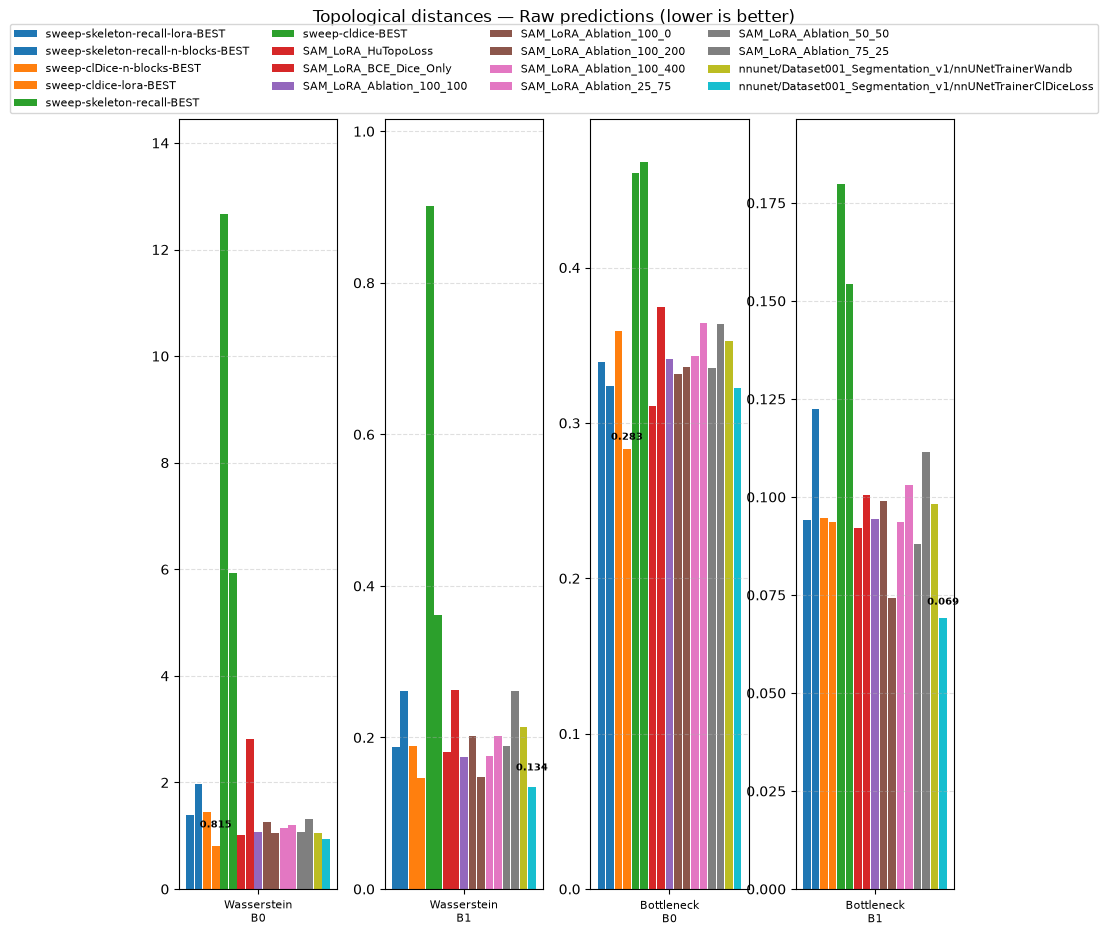

/tmp/ipykernel_265415/3947799005.py:127: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, subplot_top])


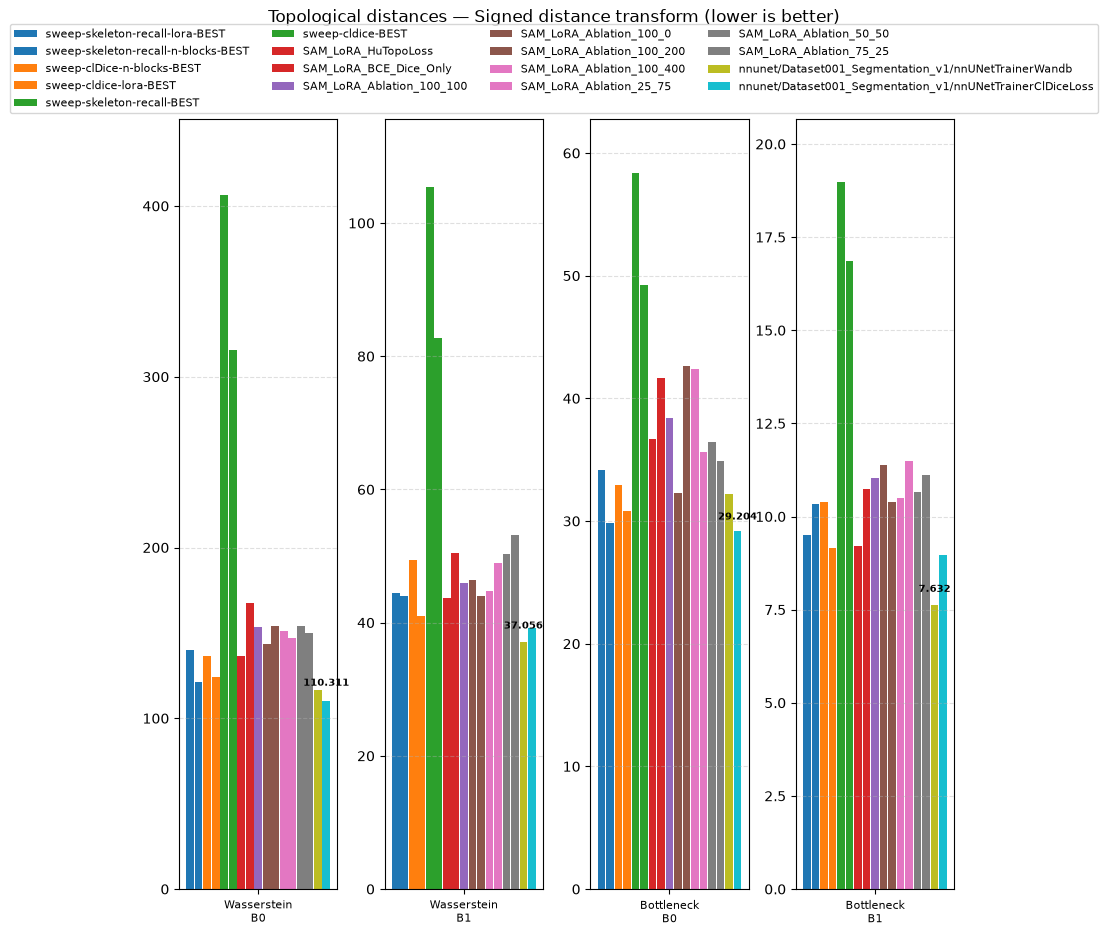

In [10]:
_TOPO_LOWER = set(SEG_TOPO_COLS)  # all distance metrics: lower is better

for _suffix, _label in [("Raw", "Raw predictions"), ("SDT", "Signed distance transform")]:
    horizontal_bar_groups(
        df_seg,
        col_groups=[
            (f"Wasserstein B0 {_suffix}",),
            (f"Wasserstein B1 {_suffix}",),
            (f"Bottleneck B0 {_suffix}",),
            (f"Bottleneck B1 {_suffix}",),
        ],
        lower_is_better=_TOPO_LOWER,
        col_rename={
            f"Wasserstein B0 {_suffix}": "Wasserstein\nB0",
            f"Wasserstein B1 {_suffix}": "Wasserstein\nB1",
            f"Bottleneck B0 {_suffix}":  "Bottleneck\nB0",
            f"Bottleneck B1 {_suffix}":  "Bottleneck\nB1",
        },
        ylim=None,
        suptitle=f"Topological distances — {_label} (lower is better)",
    )

### Persistence Diagrams

Birth–death scatter plots from the raw and SDT persistence CSVs.

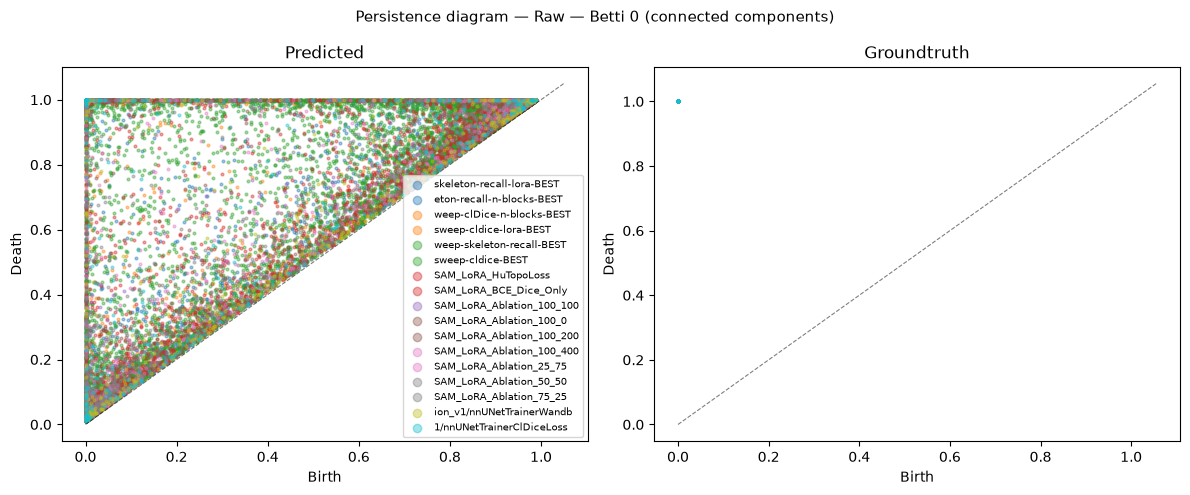

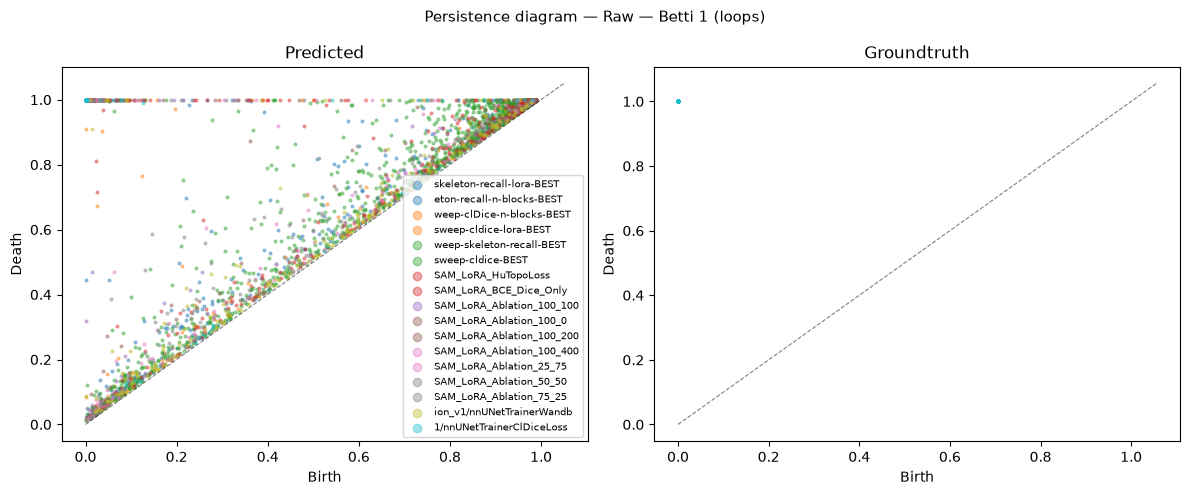

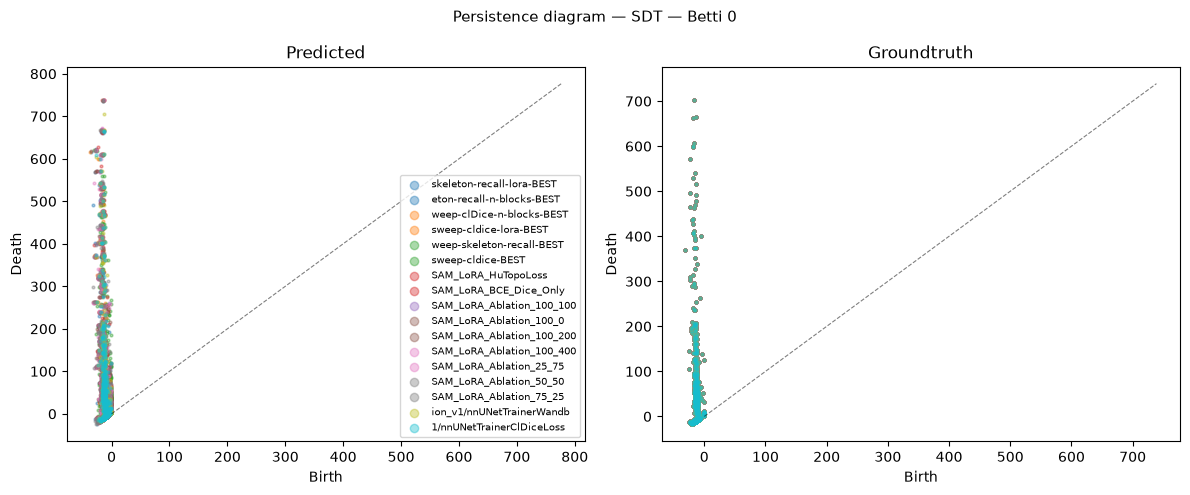

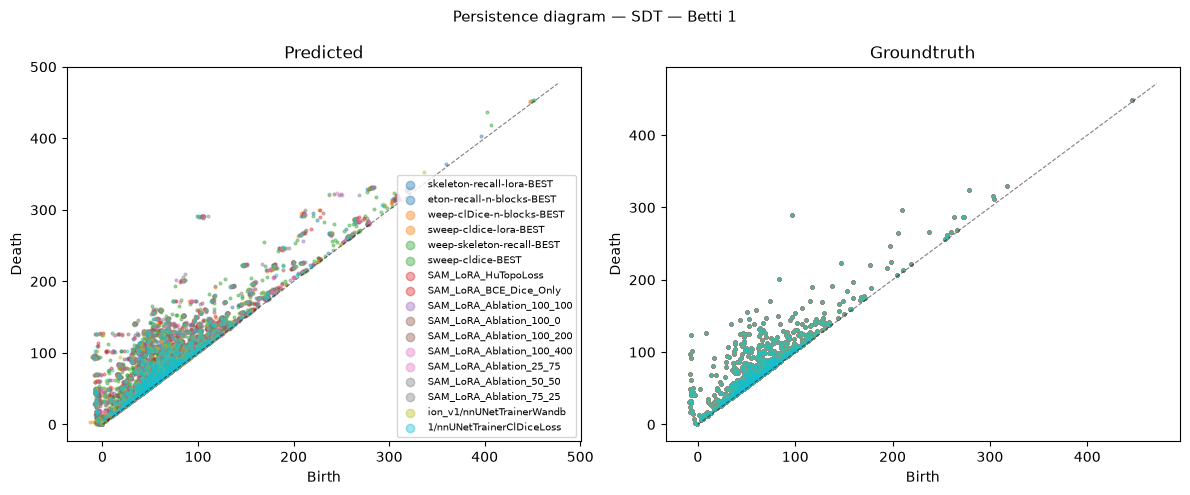

In [11]:
for filename, title in [
    ("persistence_raw_b0.csv", "Raw — Betti 0 (connected components)"),
    ("persistence_raw_b1.csv", "Raw — Betti 1 (loops)"),
    ("persistence_sdt_b0.csv", "SDT — Betti 0"),
    ("persistence_sdt_b1.csv", "SDT — Betti 1"),
]:
    _csv = SEG_EVAL_DIR / "csv" / filename
    if _csv is None:
        print(f"  {filename} not found, skipping.")
        continue

    df_pd = pd.read_csv(_csv)
    models = df_pd["model"].unique() if "model" in df_pd.columns else []
    if len(models) == 0:
        print(f"  {filename}: no model column, skipping.")
        continue

    colors = plt.cm.tab10(np.linspace(0, 0.9, len(models)))
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    for ax, ptype in zip(axes, ["predicted", "groundtruth"]):
        df_sub = df_pd[df_pd["type"] ==
                       ptype] if "type" in df_pd.columns else df_pd
        for i, model in enumerate(models):
            df_m = df_sub[df_sub["model"] ==
                          model] if "model" in df_sub.columns else df_sub
            if df_m.empty:
                continue
            b, d = df_m["birth"], df_m["death"]
            ax.scatter(b, d, s=4, alpha=0.4, color=colors[i],
                       label=str(model)[-25:])
        # Diagonal (birth = death)
        lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
        ax.plot([0, lim], [0, lim], "k--", linewidth=0.8, alpha=0.5)
        ax.set_xlabel("Birth")
        ax.set_ylabel("Death")
        ax.set_title(ptype.capitalize())
        if ptype == "predicted":
            ax.legend(markerscale=3, fontsize=7, loc="lower right")

    fig.suptitle(f"Persistence diagram — {title}", fontsize=11)
    plt.tight_layout()
    plt.show()
    plt.close()

---
## Junction Detection Evaluation

In [12]:
# ── Load junction detection metrics (one DataFrame per dataset) ─────────────
jd_results: dict[str, pd.DataFrame] = {}
for _ds, _dir in JD_EVAL_DIRS.items():
    _jd_csv = _dir / "metrics.csv"
    if not _jd_csv.is_file():
        raise FileNotFoundError(f"metrics.csv not found in {_dir}")

    _df = pd.read_csv(_jd_csv, index_col="model")
    _df.index = _df.index.map(str)
    jd_results[_ds] = _df
    print(f"Loaded junction detection metrics [{_ds}]: {len(_df)} model(s) from {_jd_csv}")

# Primary dataset, used by the confusion matrices and correlation analysis below
df_jd = jd_results[JD_PRIMARY]

Loaded junction detection metrics [real]: 17 model(s) from /mnt/c/Users/juhe9/repos/MasterThesis/ForkSight/Data/evaluation_output/junction_detection/20260428_114907/metrics.csv
Loaded junction detection metrics [synthetic]: 1 model(s) from /mnt/c/Users/juhe9/repos/MasterThesis/ForkSight/Data/evaluation_output/junction_detection_synthetic/20261019_230516/metrics.csv


In [13]:
# Ground truth junction counts (fixed test set — should be identical across all models)
for _ds, _df in jd_results.items():
    _gt_3way = _df["pp_gt_3way_total"].astype(int)
    _gt_4way = _df["pp_gt_4way_total"].astype(int)

    assert _gt_3way.nunique() == 1, f"GT 3-way total differs across models [{_ds}]"
    assert _gt_4way.nunique() == 1, f"GT 4-way total differs across models [{_ds}]"

    n_gt_3way = int(_gt_3way.iloc[0])
    n_gt_4way = int(_gt_4way.iloc[0])
    n_gt_total = n_gt_3way + n_gt_4way

    print(f"Ground truth junctions in test set [{_ds}]:")
    print(f"  3-way : {n_gt_3way}")
    print(f"  4-way : {n_gt_4way}")
    print(f"  Total : {n_gt_total}")

Ground truth junctions in test set [real]:
  3-way : 45
  4-way : 77
  Total : 122
Ground truth junctions in test set [synthetic]:
  3-way : 48
  4-way : 48
  Total : 96


In [14]:
# Derive micro-averaged combined joint metrics from the per-class counts already in the CSV.
# (Avoids re-running the slow compute script.)
def _prf(tp, fp, fn):
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    return prec, rec, f1


def _add_derived_jd_metrics(df: pd.DataFrame) -> None:
    """Add combined joint and per-type detection precision columns in place."""
    for _pfx in ("raw_", "pp_"):
        tp = df[f"{_pfx}class_tp_3way"] + df[f"{_pfx}class_tp_4way"]
        fp = df[f"{_pfx}class_fp_3way"] + df[f"{_pfx}class_fp_4way"]
        fn = df[f"{_pfx}class_fn_3way"] + df[f"{_pfx}class_fn_4way"]
        prf = [_prf(tp.iloc[i], fp.iloc[i], fn.iloc[i]) for i in range(len(df))]
        df[f"{_pfx}class_tp_combined"]        = tp.values
        df[f"{_pfx}class_fp_combined"]        = fp.values
        df[f"{_pfx}class_fn_combined"]        = fn.values
        df[f"{_pfx}class_precision_combined"] = [p for p, _, _ in prf]
        df[f"{_pfx}class_recall_combined"]    = [r for _, r, _ in prf]
        df[f"{_pfx}class_f1_combined"]        = [f for _, _, f in prf]

    # Detection precision per predicted type: fraction of predicted junctions of that type
    # that were localised at any GT junction (regardless of whether the type was correct).
    # Counterpart to detection_recall_{3,4}way, which is computed per GT type.
    for _pfx in ("raw_", "pp_"):
        for _t in ("3", "4"):
            loc_tp = df[f"{_pfx}cm_gt3_pred{_t}"] + df[f"{_pfx}cm_gt4_pred{_t}"]
            pred_total = loc_tp + df[f"{_pfx}fp_{_t}way"]
            df[f"{_pfx}detection_precision_{_t}way"] = (
                loc_tp / pred_total.where(pred_total > 0)).fillna(0.0)


for _df in jd_results.values():
    _add_derived_jd_metrics(_df)

/tmp/ipykernel_265415/2561190240.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{_pfx}class_tp_combined"]        = tp.values
/tmp/ipykernel_265415/2561190240.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{_pfx}class_fp_combined"]        = fp.values
/tmp/ipykernel_265415/2561190240.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To ge

In [15]:
# Column groups — all higher-is-better
_JD_LOCALISATION      = ["precision_loc", "recall_loc", "f1_loc"]
_JD_DETECTION_RECALL  = ["detection_recall_3way", "detection_recall_4way"]
_JD_DETECTION_PRECISION = ["detection_precision_3way", "detection_precision_4way"]
_JD_TYPE_OVERALL      = ["type_accuracy"]
_JD_CLASS_COMBINED    = ["class_precision_combined", "class_recall_combined", "class_f1_combined"]
_JD_CLASS_3WAY        = ["class_precision_3way", "class_recall_3way", "class_f1_3way"]
_JD_CLASS_4WAY        = ["class_precision_4way", "class_recall_4way", "class_f1_4way"]

_JD_DISPLAY_COLS = (
    _JD_LOCALISATION + _JD_DETECTION_RECALL + _JD_DETECTION_PRECISION + _JD_TYPE_OVERALL
    + _JD_CLASS_COMBINED + _JD_CLASS_3WAY + _JD_CLASS_4WAY
)

_DISPLAY_RENAME = {
    "precision_loc":            "Precision (loc)",
    "recall_loc":               "Recall (loc)",
    "f1_loc":                   "F1 (loc)",
    "detection_recall_3way":    "Det. Recall 3-way",
    "detection_recall_4way":    "Det. Recall 4-way",
    "detection_precision_3way": "Det. Precision 3-way",
    "detection_precision_4way": "Det. Precision 4-way",
    "type_accuracy":            "Type Accuracy",
    "class_precision_combined": "Precision (joint)",
    "class_recall_combined":    "Recall (joint)",
    "class_f1_combined":        "F1 (joint)",
    "class_precision_3way":     "Precision 3-way",
    "class_recall_3way":        "Recall 3-way",
    "class_f1_3way":            "F1 3-way",
    "class_precision_4way":     "Precision 4-way",
    "class_recall_4way":        "Recall 4-way",
    "class_f1_4way":            "F1 4-way",
}


def _jd_table(df: pd.DataFrame, prefix: str, title: str) -> None:
    cols_in_df = [f"{prefix}{c}" for c in _JD_DISPLAY_COLS
                  if f"{prefix}{c}" in df.columns]
    if not cols_in_df:
        print(f"No '{prefix}' columns found.")
        return
    display(HTML(f"<h4>{title}</h4>"))
    sub = df[cols_in_df].copy()
    sub.columns = [_DISPLAY_RENAME.get(c.removeprefix(prefix), c) for c in cols_in_df]
    display(bold_best(sub))

**Precision / Recall / F1 (loc):** class-agnostic; a prediction is a TP if it falls within the pixel threshold of *any* GT junction, regardless of type.
**Det. Recall 3-way / 4-way:** per-GT-class localisation recall — of all GT junctions of that type, what fraction were spatially matched by *any* prediction (regardless of predicted type). Also shown in the confusion matrix title.
**Type Accuracy:** among spatially-matched TPs only — fraction whose type label (3-way / 4-way) matches GT.
**Precision / Recall / F1 (joint):** micro-averaged over both classes; a prediction is a TP for class $c$ only if it is both correctly localised *and* correctly labelled — equivalent to summing the per-class TP/FP/FN counts before computing the metrics.
**Precision / Recall / F1 3-way & 4-way:** same joint criterion, broken out per class. FP and FN include both spurious/missed detections and type misclassifications (see confusion matrices below).

### Junction Detection Metrics — Raw

In [16]:
for _ds, _df in jd_results.items():
    _jd_table(_df, prefix="raw_", title=f"Raw (no postprocessing) — {_ds}")

,Precision (loc),Recall (loc),F1 (loc),Det. Recall 3-way,Det. Recall 4-way,Det. Precision 3-way,Det. Precision 4-way,Type Accuracy,Precision (joint),Recall (joint),F1 (joint),Precision 3-way,Recall 3-way,F1 3-way,Precision 4-way,Recall 4-way,F1 4-way
model,,,,,,,,,,,,,,,,,
SAM_LoRA_Ablation_100_0,0.3739,0.7049,0.4886,0.7333,0.6883,0.3200,0.4750,0.8256,0.3087,0.5820,0.4034,0.2200,0.7333,0.3385,0.4750,0.4935,0.4841
SAM_LoRA_Ablation_100_100,0.3891,0.7623,0.5152,0.7778,0.7532,0.3012,0.5890,0.8387,0.3264,0.6393,0.4321,0.2108,0.7778,0.3318,0.5890,0.5584,0.5733
SAM_LoRA_Ablation_100_200,0.4091,0.7377,0.5263,0.7778,0.7143,0.3333,0.5714,0.8333,0.3409,0.6148,0.4386,0.2333,0.7778,0.3590,0.5714,0.5195,0.5442
SAM_LoRA_Ablation_100_400,0.4224,0.8033,0.5537,0.8000,0.8052,0.3467,0.5610,0.8367,0.3534,0.6721,0.4633,0.2400,0.8000,0.3692,0.5610,0.5974,0.5786
SAM_LoRA_Ablation_25_75,0.3770,0.7541,0.5027,0.7556,0.7532,0.3148,0.5000,0.8152,0.3074,0.6148,0.4098,0.2099,0.7556,0.3285,0.5000,0.5325,0.5157
SAM_LoRA_Ablation_50_50,0.3566,0.7541,0.4842,0.8000,0.7273,0.2963,0.5217,0.7826,0.2791,0.5902,0.3789,0.1905,0.8000,0.3077,0.5217,0.4675,0.4932
SAM_LoRA_Ablation_75_25,0.3560,0.7295,0.4785,0.7333,0.7273,0.3114,0.4458,0.7865,0.2800,0.5738,0.3763,0.1976,0.7333,0.3113,0.4458,0.4805,0.4625
SAM_LoRA_BCE_Dice_Only,0.4726,0.7787,0.5882,0.8667,0.7273,0.3876,0.6250,0.8842,0.4179,0.6885,0.5201,0.3023,0.8667,0.4483,0.6250,0.5844,0.6040
SAM_LoRA_HuTopoLoss,0.4677,0.7705,0.5820,0.8444,0.7273,0.3934,0.5823,0.8936,0.4179,0.6885,0.5201,0.3115,0.8444,0.4551,0.5823,0.5974,0.5897


,Precision (loc),Recall (loc),F1 (loc),Det. Recall 3-way,Det. Recall 4-way,Det. Precision 3-way,Det. Precision 4-way,Type Accuracy,Precision (joint),Recall (joint),F1 (joint),Precision 3-way,Recall 3-way,F1 3-way,Precision 4-way,Recall 4-way,F1 4-way
model,,,,,,,,,,,,,,,,,
nnunet/Dataset021_SegmentationSynthetic/nnUNetTrainerClDiceLoss,0.4678,0.8333,0.5993,0.7500,0.9167,0.3774,0.6154,0.9500,0.4444,0.7917,0.5693,0.3396,0.7500,0.4675,0.6154,0.8333,0.7080


### Junction Detection Metrics — Post-processed

In [17]:
for _ds, _df in jd_results.items():
    _jd_table(_df, prefix="pp_", title=f"Post-processed — {_ds}")

,Precision (loc),Recall (loc),F1 (loc),Det. Recall 3-way,Det. Recall 4-way,Det. Precision 3-way,Det. Precision 4-way,Type Accuracy,Precision (joint),Recall (joint),F1 (joint),Precision 3-way,Recall 3-way,F1 3-way,Precision 4-way,Recall 4-way,F1 4-way
model,,,,,,,,,,,,,,,,,
SAM_LoRA_Ablation_100_0,0.3755,0.7049,0.4900,0.7333,0.6883,0.3221,0.4750,0.8256,0.3100,0.5820,0.4046,0.2215,0.7333,0.3402,0.4750,0.4935,0.4841
SAM_LoRA_Ablation_100_100,0.3891,0.7623,0.5152,0.7778,0.7532,0.3012,0.5890,0.8387,0.3264,0.6393,0.4321,0.2108,0.7778,0.3318,0.5890,0.5584,0.5733
SAM_LoRA_Ablation_100_200,0.4110,0.7377,0.5279,0.7778,0.7143,0.3356,0.5714,0.8333,0.3425,0.6148,0.4399,0.2349,0.7778,0.3608,0.5714,0.5195,0.5442
SAM_LoRA_Ablation_100_400,0.4242,0.8033,0.5552,0.8000,0.8052,0.3490,0.5610,0.8367,0.3550,0.6721,0.4646,0.2416,0.8000,0.3711,0.5610,0.5974,0.5786
SAM_LoRA_Ablation_25_75,0.3786,0.7541,0.5041,0.7556,0.7532,0.3148,0.5062,0.8152,0.3086,0.6148,0.4110,0.2099,0.7556,0.3285,0.5062,0.5325,0.5190
SAM_LoRA_Ablation_50_50,0.3605,0.7623,0.4895,0.8000,0.7403,0.2979,0.5286,0.7849,0.2829,0.5984,0.3842,0.1915,0.8000,0.3090,0.5286,0.4805,0.5034
SAM_LoRA_Ablation_75_25,0.3560,0.7295,0.4785,0.7333,0.7273,0.3114,0.4458,0.7865,0.2800,0.5738,0.3763,0.1976,0.7333,0.3113,0.4458,0.4805,0.4625
SAM_LoRA_BCE_Dice_Only,0.4726,0.7787,0.5882,0.8667,0.7273,0.3876,0.6250,0.8842,0.4179,0.6885,0.5201,0.3023,0.8667,0.4483,0.6250,0.5844,0.6040
SAM_LoRA_HuTopoLoss,0.4700,0.7705,0.5839,0.8444,0.7273,0.3967,0.5823,0.8936,0.4200,0.6885,0.5217,0.3140,0.8444,0.4578,0.5823,0.5974,0.5897


,Precision (loc),Recall (loc),F1 (loc),Det. Recall 3-way,Det. Recall 4-way,Det. Precision 3-way,Det. Precision 4-way,Type Accuracy,Precision (joint),Recall (joint),F1 (joint),Precision 3-way,Recall 3-way,F1 3-way,Precision 4-way,Recall 4-way,F1 4-way
model,,,,,,,,,,,,,,,,,
nnunet/Dataset021_SegmentationSynthetic/nnUNetTrainerClDiceLoss,0.4678,0.8333,0.5993,0.7500,0.9167,0.3774,0.6154,0.9500,0.4444,0.7917,0.5693,0.3396,0.7500,0.4675,0.6154,0.8333,0.7080


### Junction Detection Bar Charts

/tmp/ipykernel_265415/3947799005.py:127: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, subplot_top])


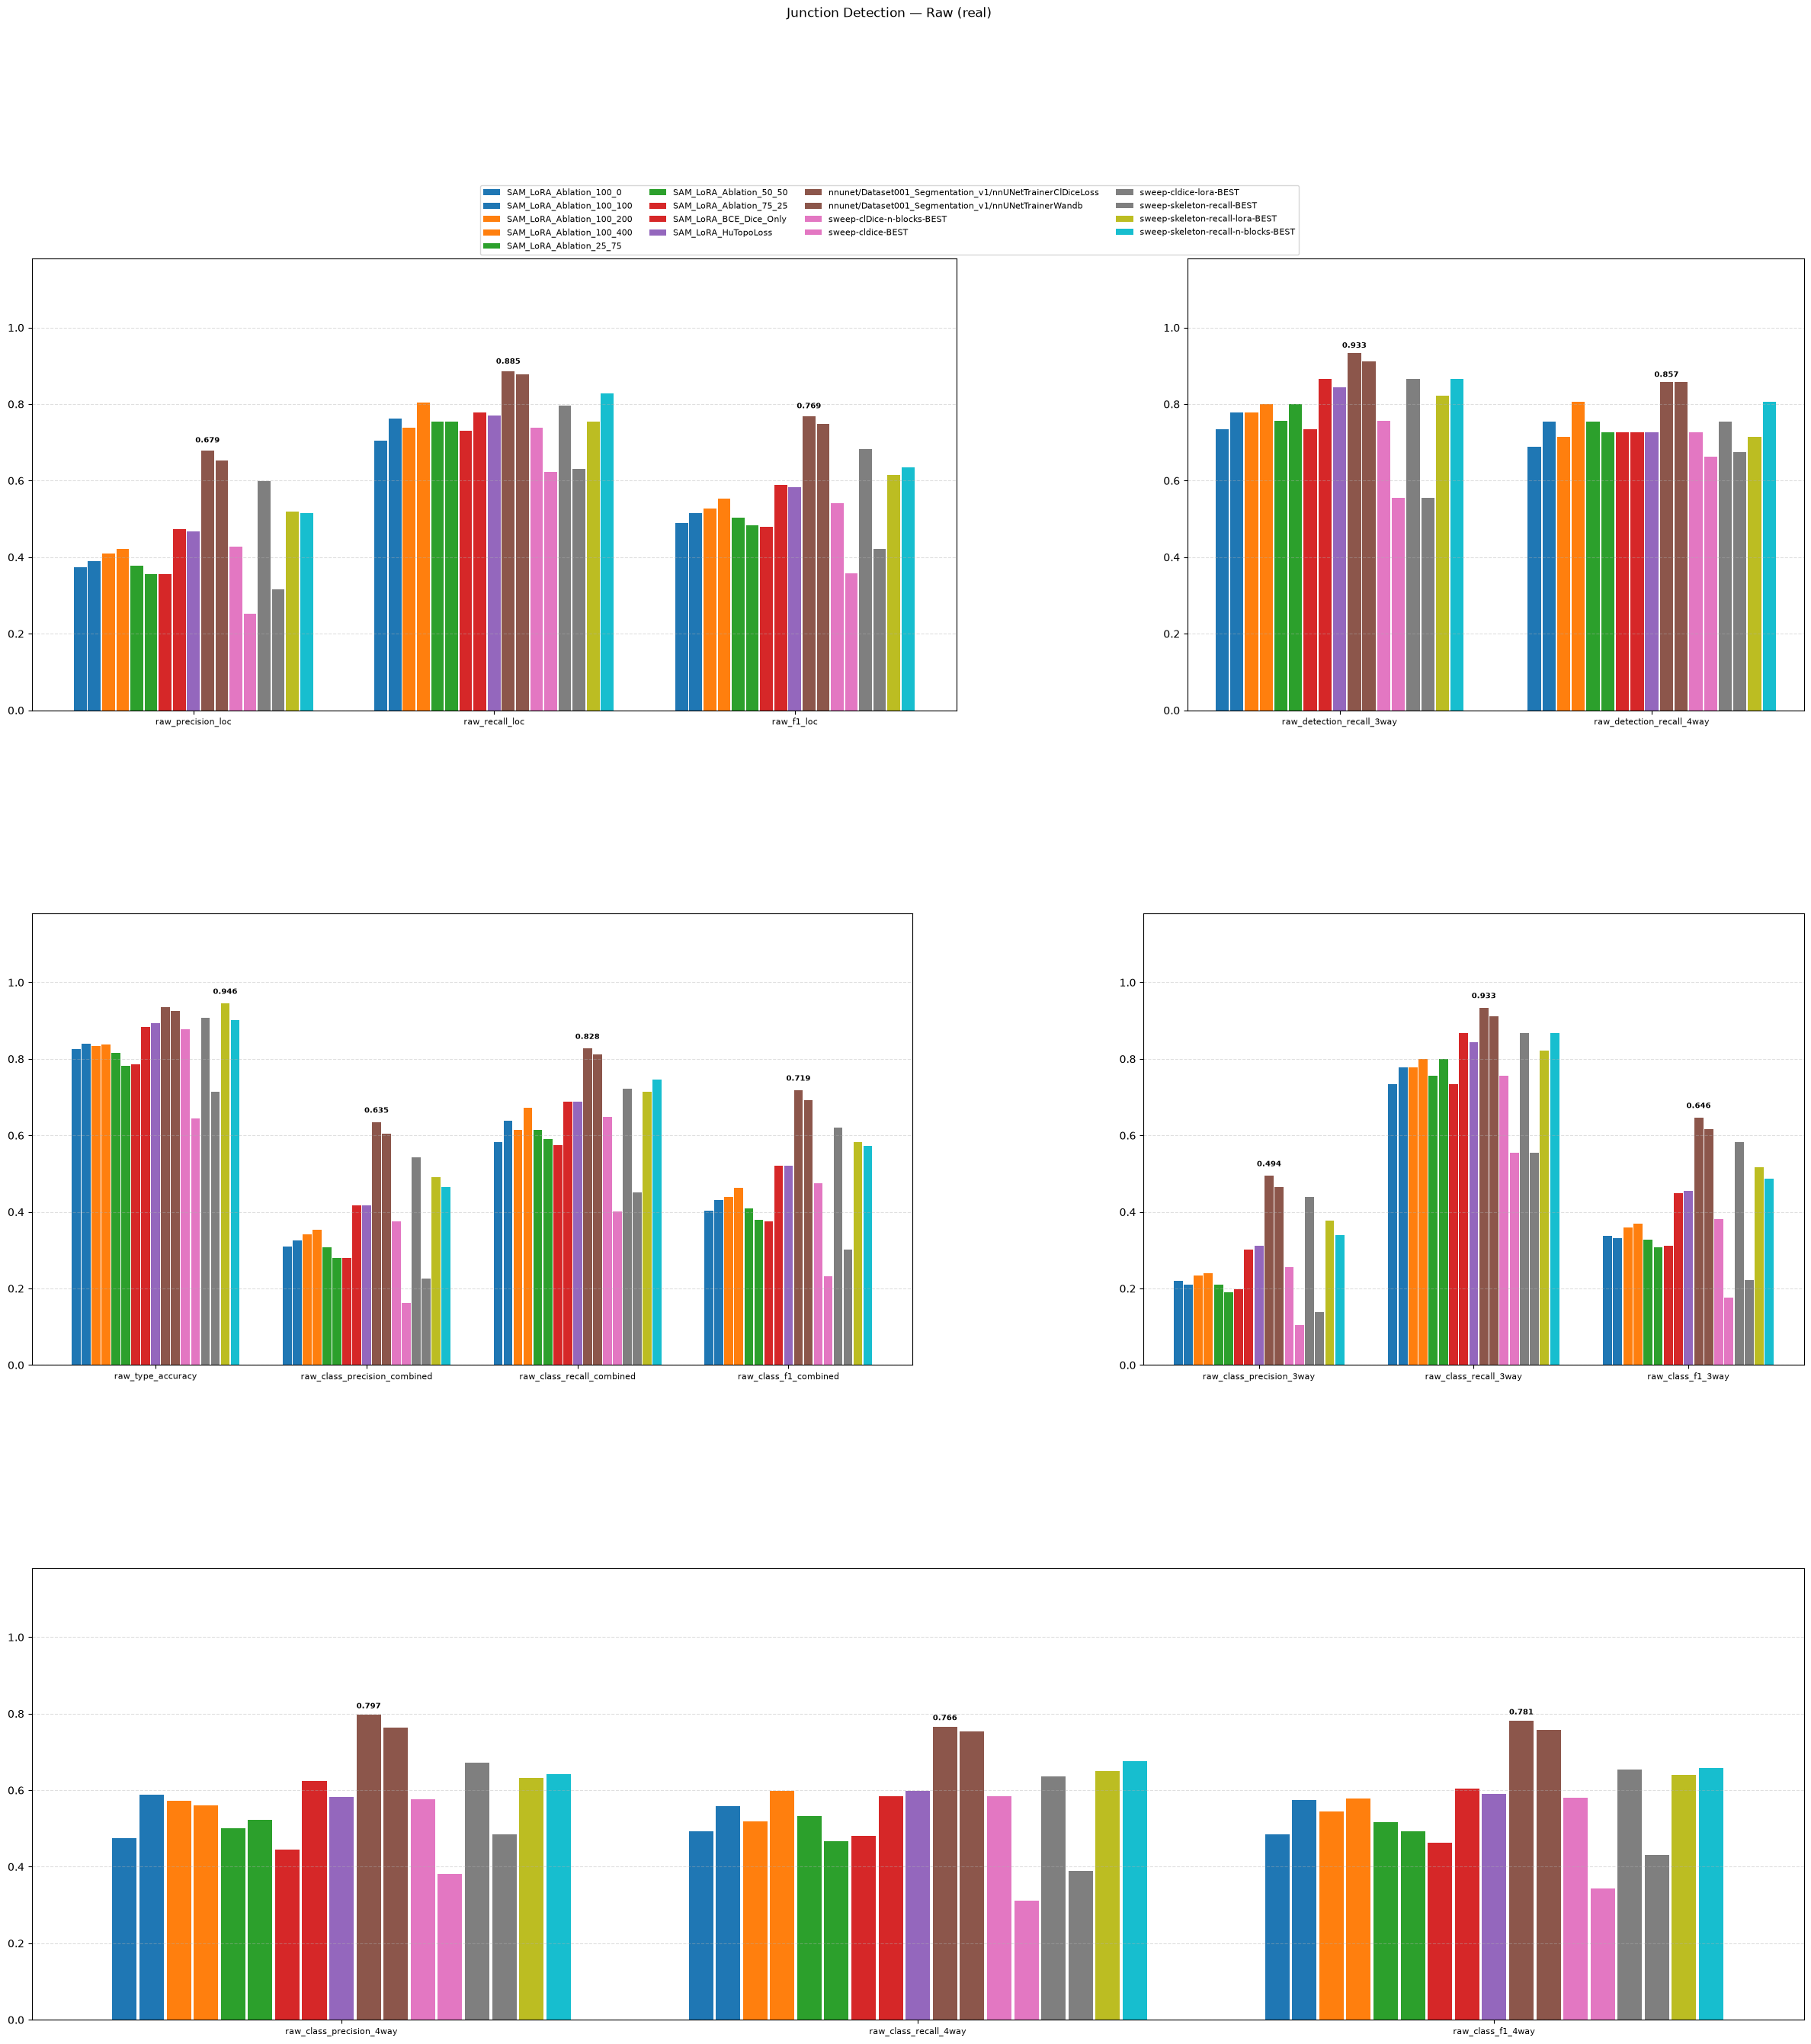

/tmp/ipykernel_265415/3947799005.py:127: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, subplot_top])


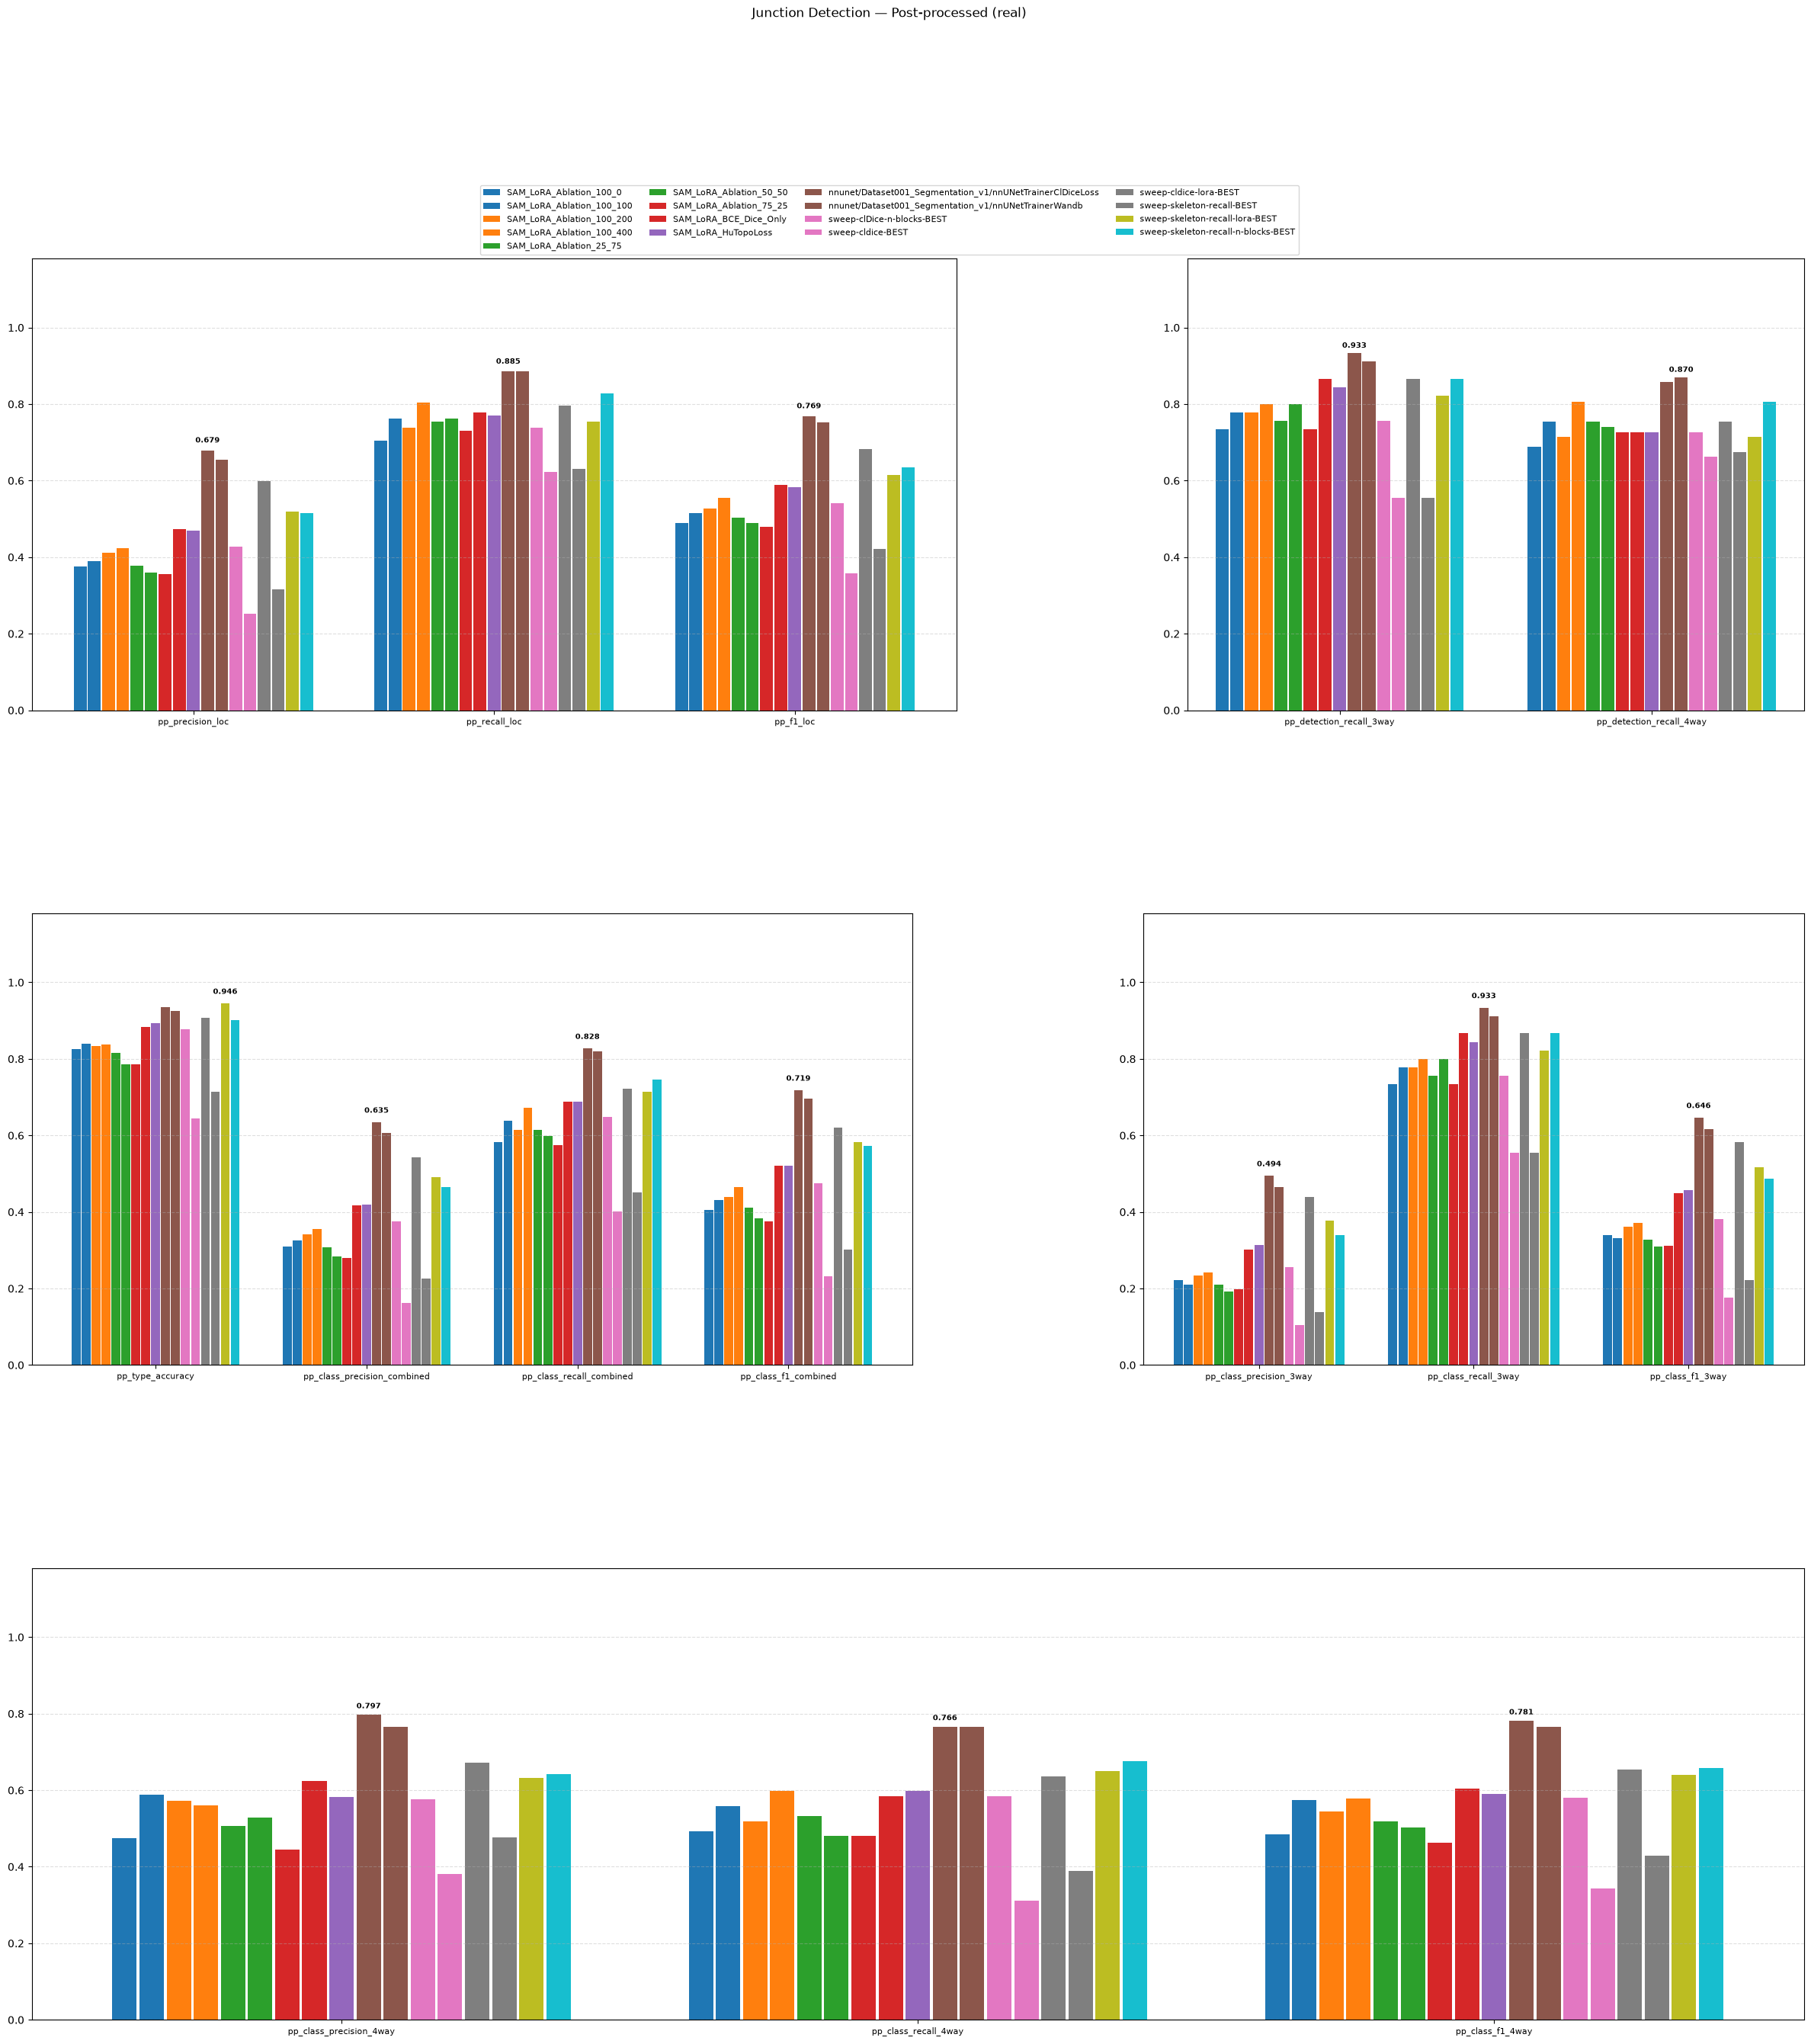

/tmp/ipykernel_265415/3947799005.py:127: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, subplot_top])


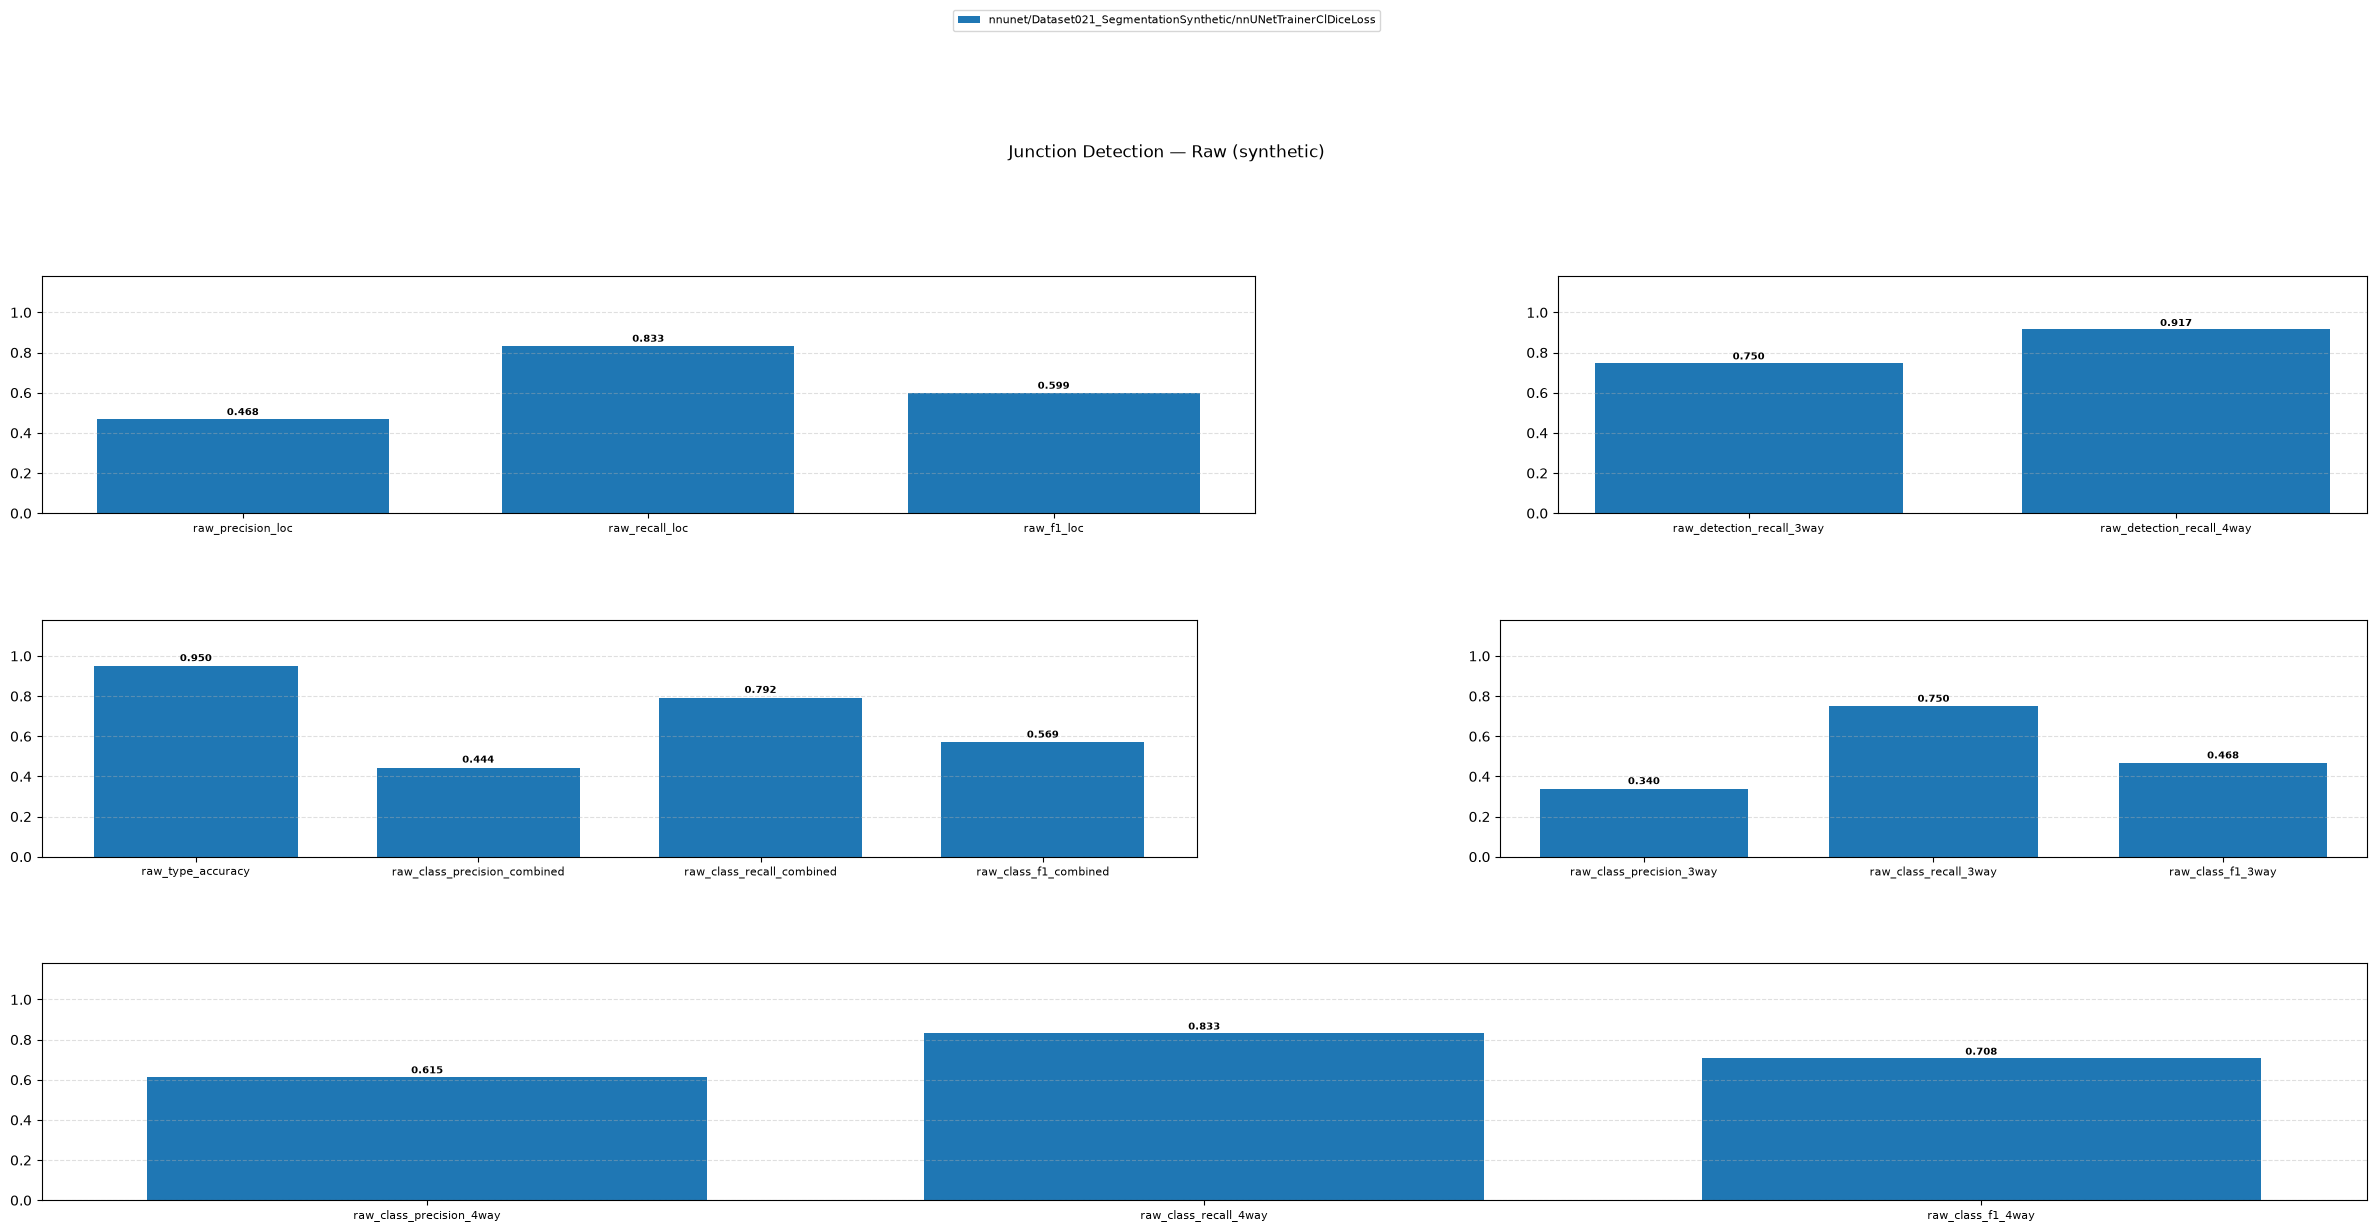

/tmp/ipykernel_265415/3947799005.py:127: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, subplot_top])


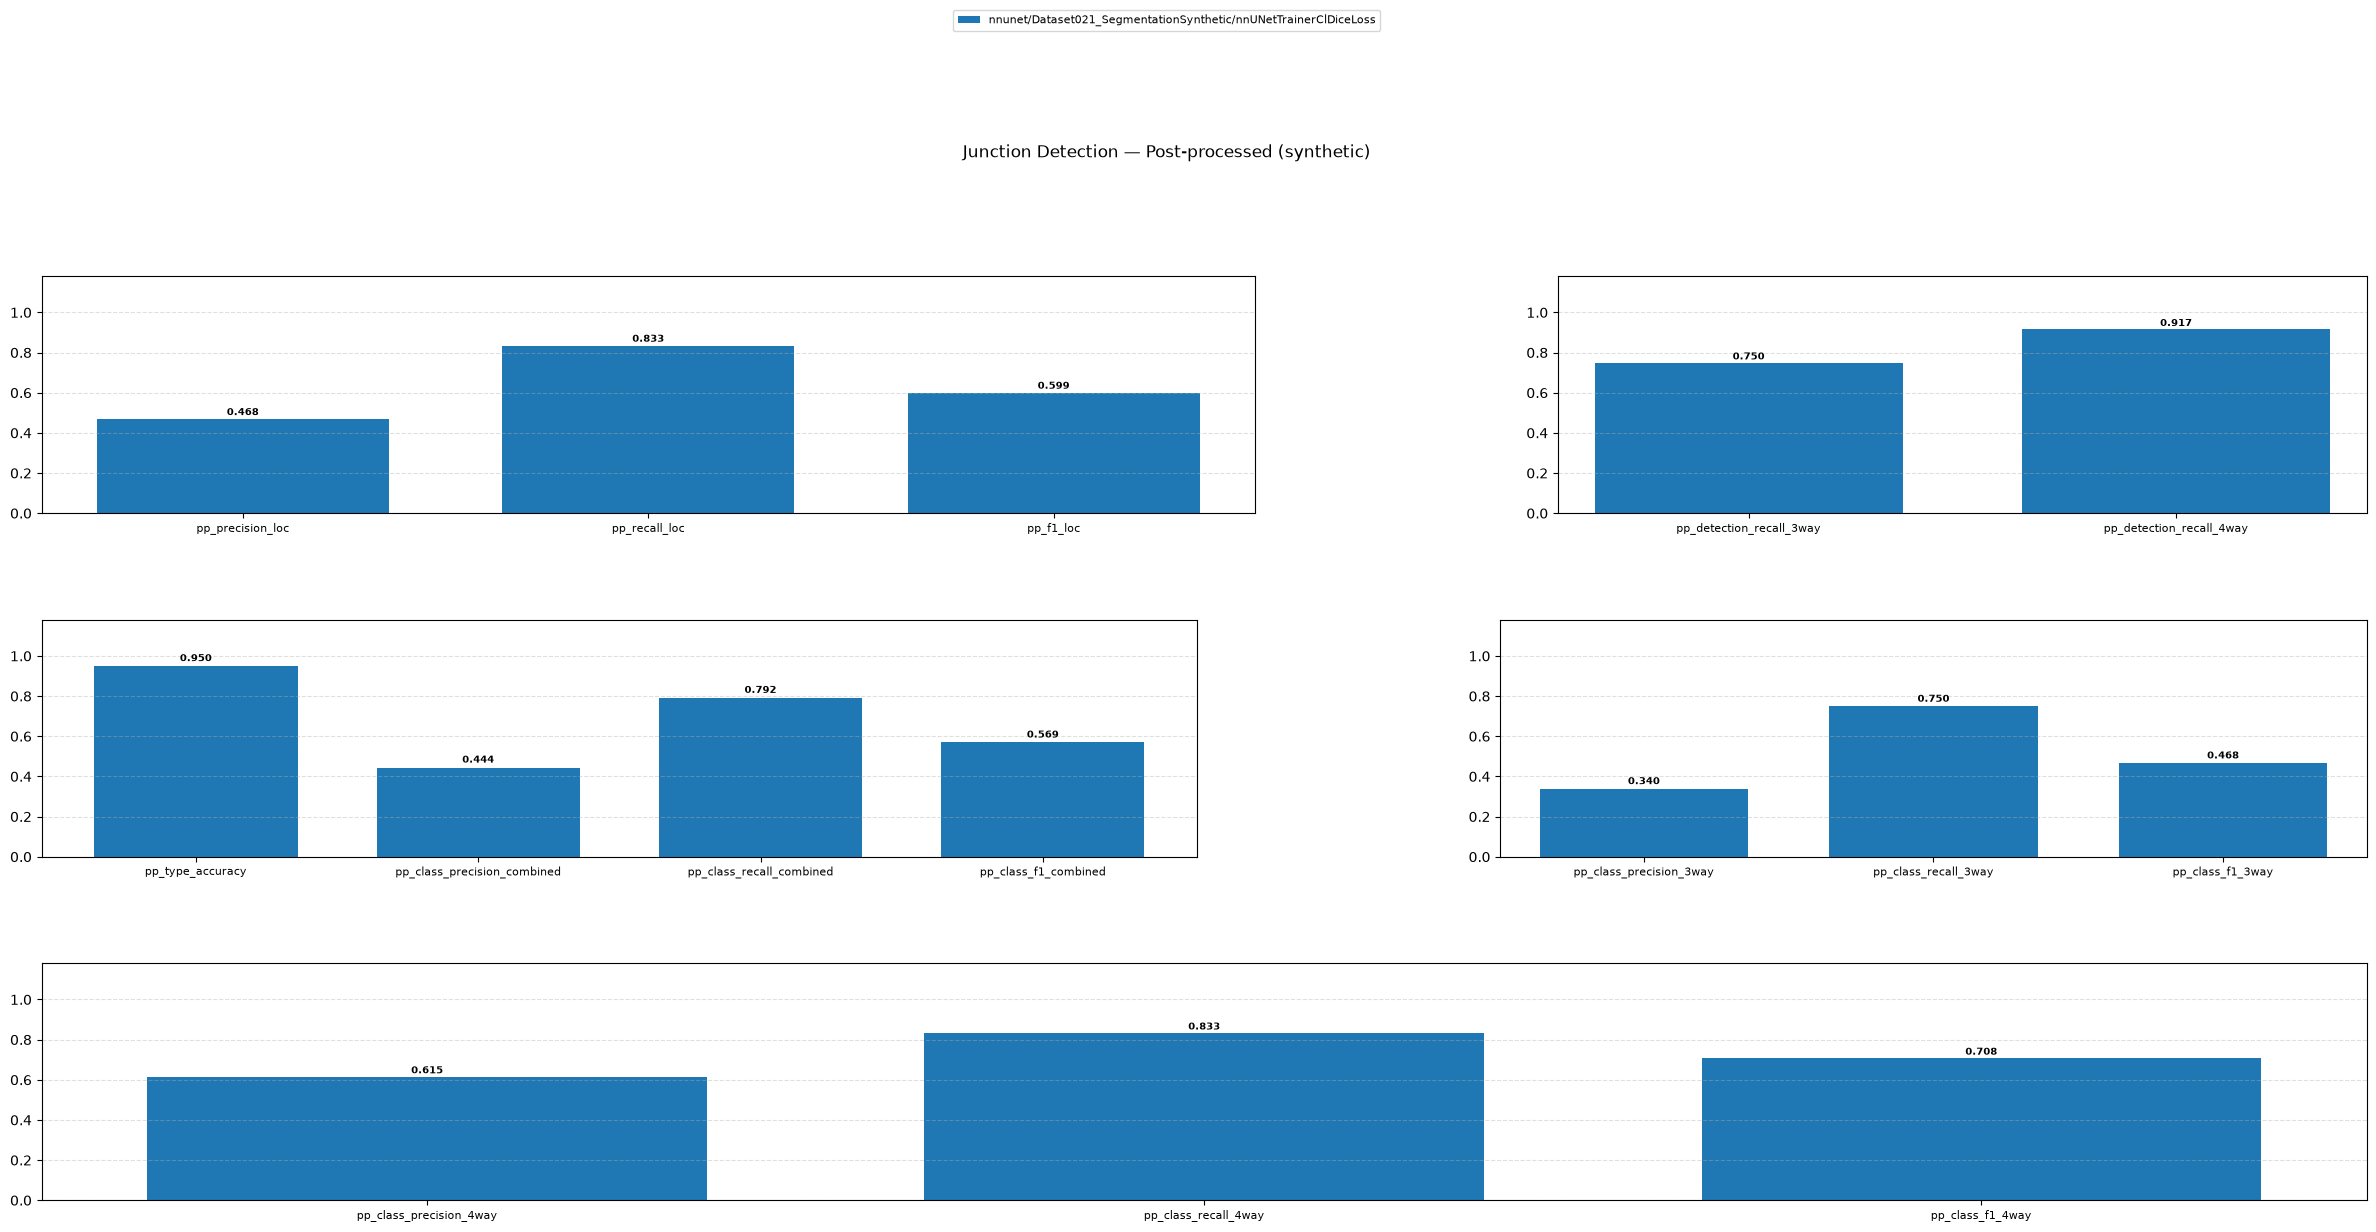

In [18]:
for _ds, _df in jd_results.items():
    for _prefix, _label in [("raw_", "Raw"), ("pp_", "Post-processed")]:
        horizontal_bar_groups(
            _df,
            col_groups=[
                tuple(f"{_prefix}{c}" for c in _JD_LOCALISATION),
                tuple(f"{_prefix}{c}" for c in _JD_DETECTION_RECALL),
                tuple(f"{_prefix}{c}" for c in _JD_TYPE_OVERALL + _JD_CLASS_COMBINED),
                tuple(f"{_prefix}{c}" for c in _JD_CLASS_3WAY),
                tuple(f"{_prefix}{c}" for c in _JD_CLASS_4WAY),
            ],
            cols_per_row=2,
            suptitle=f"Junction Detection — {_label} ({_ds})",
        )

### Confusion Matrices

Displayed from the PNG files saved by `compute_metrics_junction_detection.py` (post-processed results).

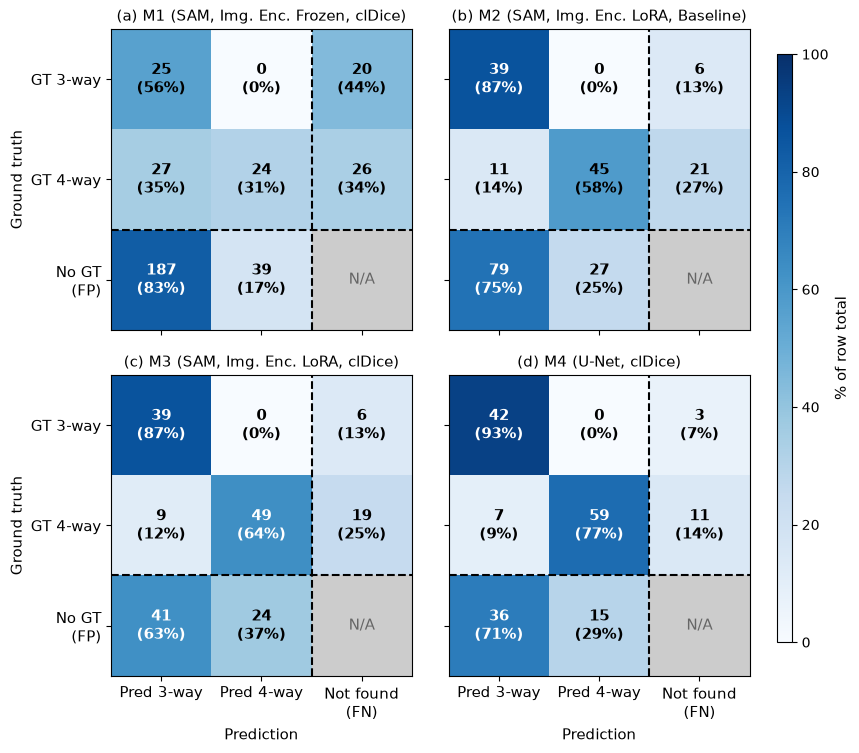

In [19]:
import string

_CM_FONT = 11

_CM_MODELS = {
    "sweep-cldice-BEST":                                              "M1 (SAM, Img. Enc. Frozen, clDice)",
    "SAM_LoRA_BCE_Dice_Only":                                         "M2 (SAM, Img. Enc. LoRA, Baseline)",
    "sweep-cldice-lora-BEST":                                         "M3 (SAM, Img. Enc. LoRA, clDice)",
    "nnunet/Dataset001_Segmentation_v1/nnUNetTrainerClDiceLoss":      "M4 (U-Net, clDice)",
}

_CM_COL_LABELS = ["Pred 3-way", "Pred 4-way", "Not found\n(FN)"]
_CM_ROW_LABELS = ["GT 3-way", "GT 4-way", "No GT\n(FP)"]


def _plot_cm_from_row(ax, row, title, prefix="pp_",
                      show_x_labels=True, show_y_labels=True):
    cm = np.array([
        [row[f"{prefix}cm_gt3_pred3"], row[f"{prefix}cm_gt3_pred4"], row[f"{prefix}fn_3way"]],
        [row[f"{prefix}cm_gt4_pred3"], row[f"{prefix}cm_gt4_pred4"], row[f"{prefix}fn_4way"]],
        [row[f"{prefix}fp_3way"],      row[f"{prefix}fp_4way"],      float("nan")],
    ], dtype=float)

    row_totals = np.array([
        row[f"{prefix}gt_3way_total"],
        row[f"{prefix}gt_4way_total"],
        row[f"{prefix}fp_3way"] + row[f"{prefix}fp_4way"],
    ], dtype=float)

    # Color by row-normalized percentage -> shared, meaningful 0-100% scale
    with np.errstate(divide="ignore", invalid="ignore"):
        cm_pct = np.where(row_totals[:, None] > 0,
                          100.0 * cm / row_totals[:, None],
                          np.nan)

    masked = np.ma.masked_invalid(cm_pct)
    im = ax.imshow(masked, cmap="Blues", vmin=0, vmax=100, aspect="equal")

    # Greyed-out N/A cell
    ax.add_patch(plt.Rectangle((1.5, 1.5), 1, 1, color="#cccccc", zorder=2))
    ax.text(2, 2, "N/A", ha="center", va="center",
            fontsize=_CM_FONT, color="#666666", zorder=3)

    ax.set_xticks([0, 1, 2])
    ax.set_yticks([0, 1, 2])
    ax.set_xticklabels(_CM_COL_LABELS if show_x_labels else [""] * 3,
                       fontsize=_CM_FONT)
    ax.set_yticklabels(_CM_ROW_LABELS if show_y_labels else [""] * 3,
                       fontsize=_CM_FONT)
    if show_x_labels:
        ax.set_xlabel("Prediction", fontsize=_CM_FONT)
    if show_y_labels:
        ax.set_ylabel("Ground truth", fontsize=_CM_FONT)

    for r in range(3):
        for c in range(3):
            if r == 2 and c == 2:
                continue
            val = cm[r, c]
            if np.isnan(val):
                continue
            pct = cm_pct[r, c]
            pct_str = f"\n({pct:.0f}%)" if not np.isnan(pct) else ""
            text_color = "white" if (not np.isnan(pct) and pct > 60) else "black"
            ax.text(c, r, f"{int(val)}{pct_str}",
                    ha="center", va="center",
                    fontsize=_CM_FONT, color=text_color,
                    fontweight="bold", zorder=4)

    ax.axhline(1.5, color="black", linewidth=1.5, linestyle="--")
    ax.axvline(1.5, color="black", linewidth=1.5, linestyle="--")
    ax.set_title(title, fontsize=_CM_FONT)
    return im


_cm_rows = [(title, df_jd.loc[key]) for key, title in _CM_MODELS.items()
            if key in df_jd.index]

_cols = 2
_rows = (len(_cm_rows) + _cols - 1) // _cols
fig, axes = plt.subplots(_rows, _cols,
                         figsize=(4.2 * _cols, 4.2 * _rows),
                         squeeze=False)

im = None
for i, (title, row) in enumerate(_cm_rows):
    r, c = i // _cols, i % _cols
    ax = axes[r][c]
    letter = string.ascii_lowercase[i]
    im = _plot_cm_from_row(
        ax, row, f"({letter}) {title}", prefix="pp_",
        show_x_labels=(r == _rows - 1),
        show_y_labels=(c == 0),
    )

for ax in axes.flat[len(_cm_rows):]:
    ax.set_visible(False)

#plt.suptitle("Junction Detection — Confusion Matrices (post-processed)",
#             fontsize=_CM_FONT + 2, y=1.01)

plt.subplots_adjust(wspace=0.05, hspace=0.15, right=0.91)

# Single shared colorbar on the right
cbar_ax = fig.add_axes([0.93, 0.15, 0.018, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("% of row total", fontsize=_CM_FONT)
cbar.ax.tick_params(labelsize=_CM_FONT - 1)

fig.savefig(_FIG_DIR / "results_exp3_confusion_matrices.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

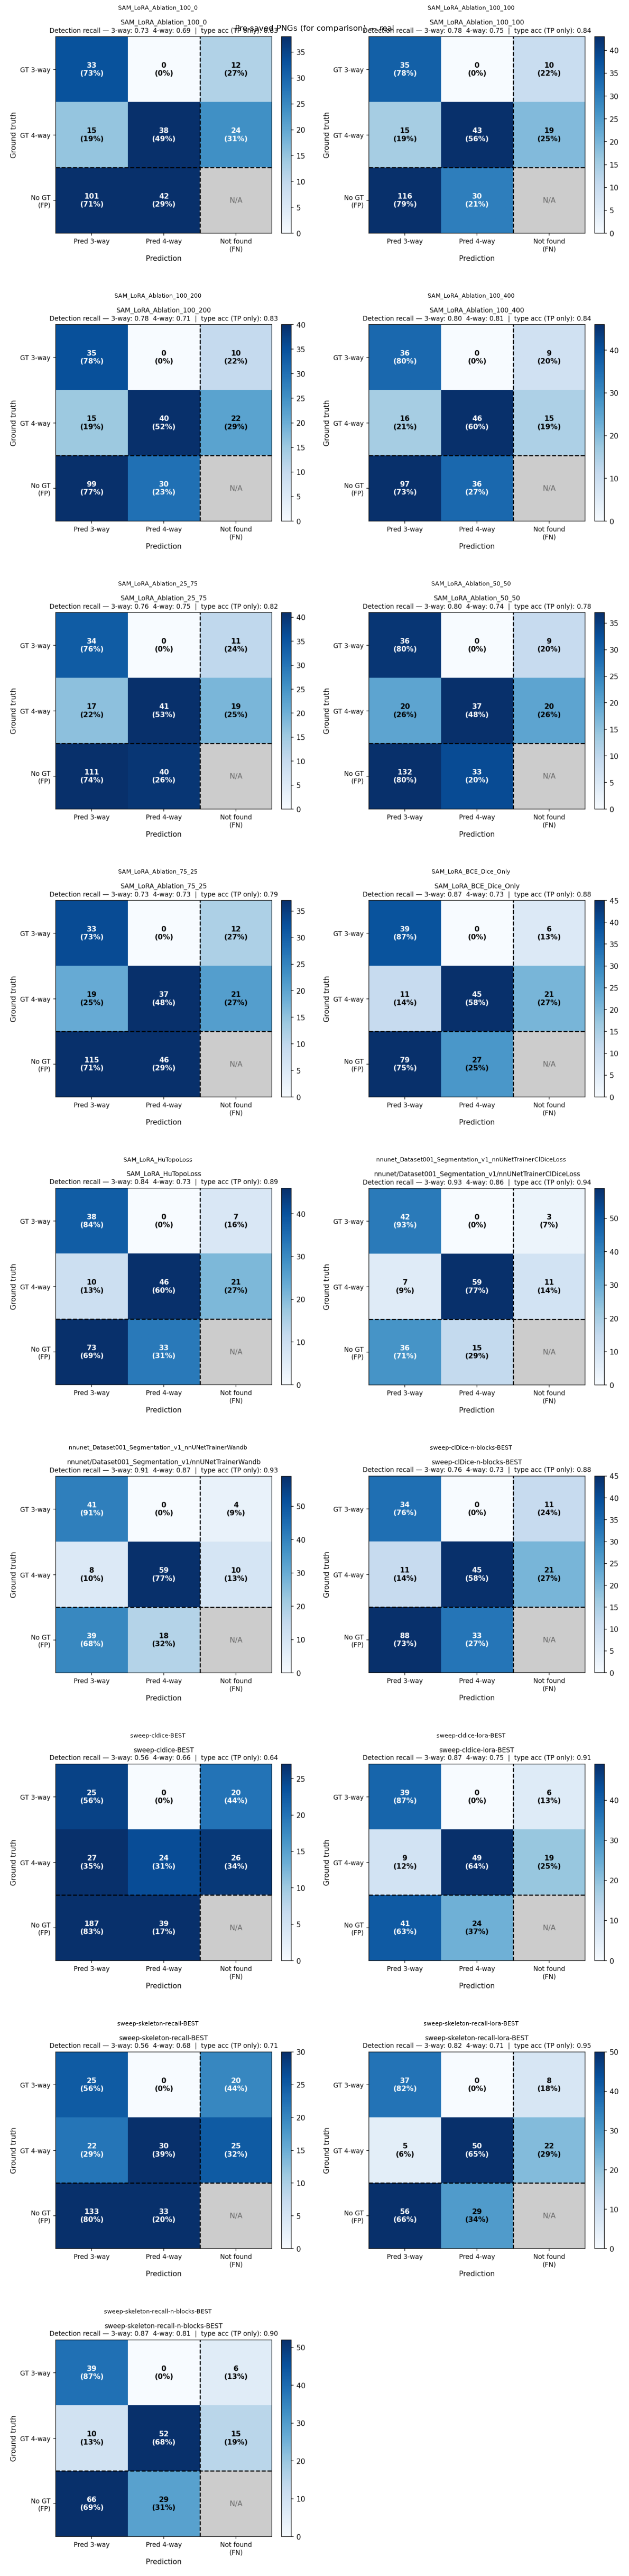

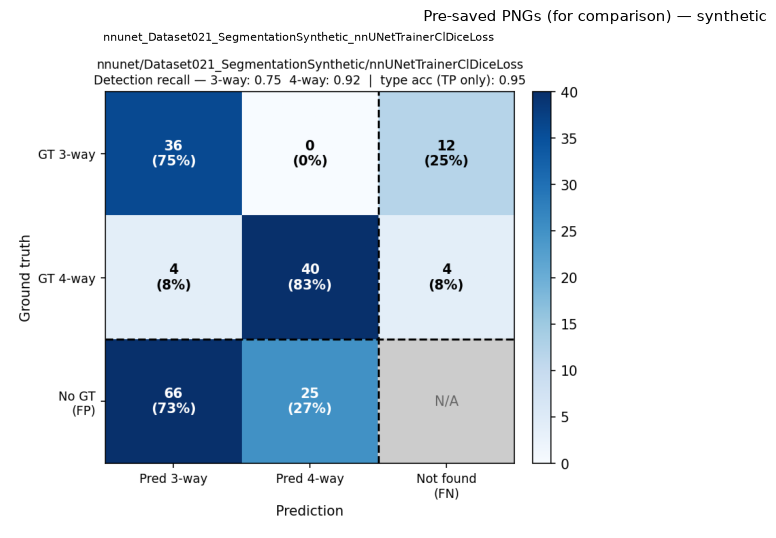

In [20]:
# Display the pre-saved PNG confusion matrices for comparison
from PIL import Image as _PILImage

for _ds, _dir in JD_EVAL_DIRS.items():
    _cm_dir = _dir / "confusion_matrices"
    _cm_pngs = sorted(_cm_dir.glob("cm_*.png")) if _cm_dir.is_dir() else []

    if not _cm_pngs:
        print(f"No confusion-matrix PNGs found [{_ds}].")
        continue

    n = len(_cm_pngs)
    _cols = 2
    _rows = (n + _cols - 1) // _cols
    fig, axes = plt.subplots(_rows, _cols, figsize=(6 * _cols, 5.5 * _rows))
    axes = np.array(axes).flatten()
    for ax, png in zip(axes, _cm_pngs):
        ax.imshow(np.array(_PILImage.open(png)))
        ax.axis("off")
        ax.set_title(png.stem.removeprefix("cm_"), fontsize=8)
    for ax in axes[n:]:
        ax.set_visible(False)
    plt.suptitle(f"Pre-saved PNGs (for comparison) — {_ds}", fontsize=11)
    plt.tight_layout()
    plt.show()
    plt.close()

### Raw vs Post-processed: Key Metrics Side-by-side

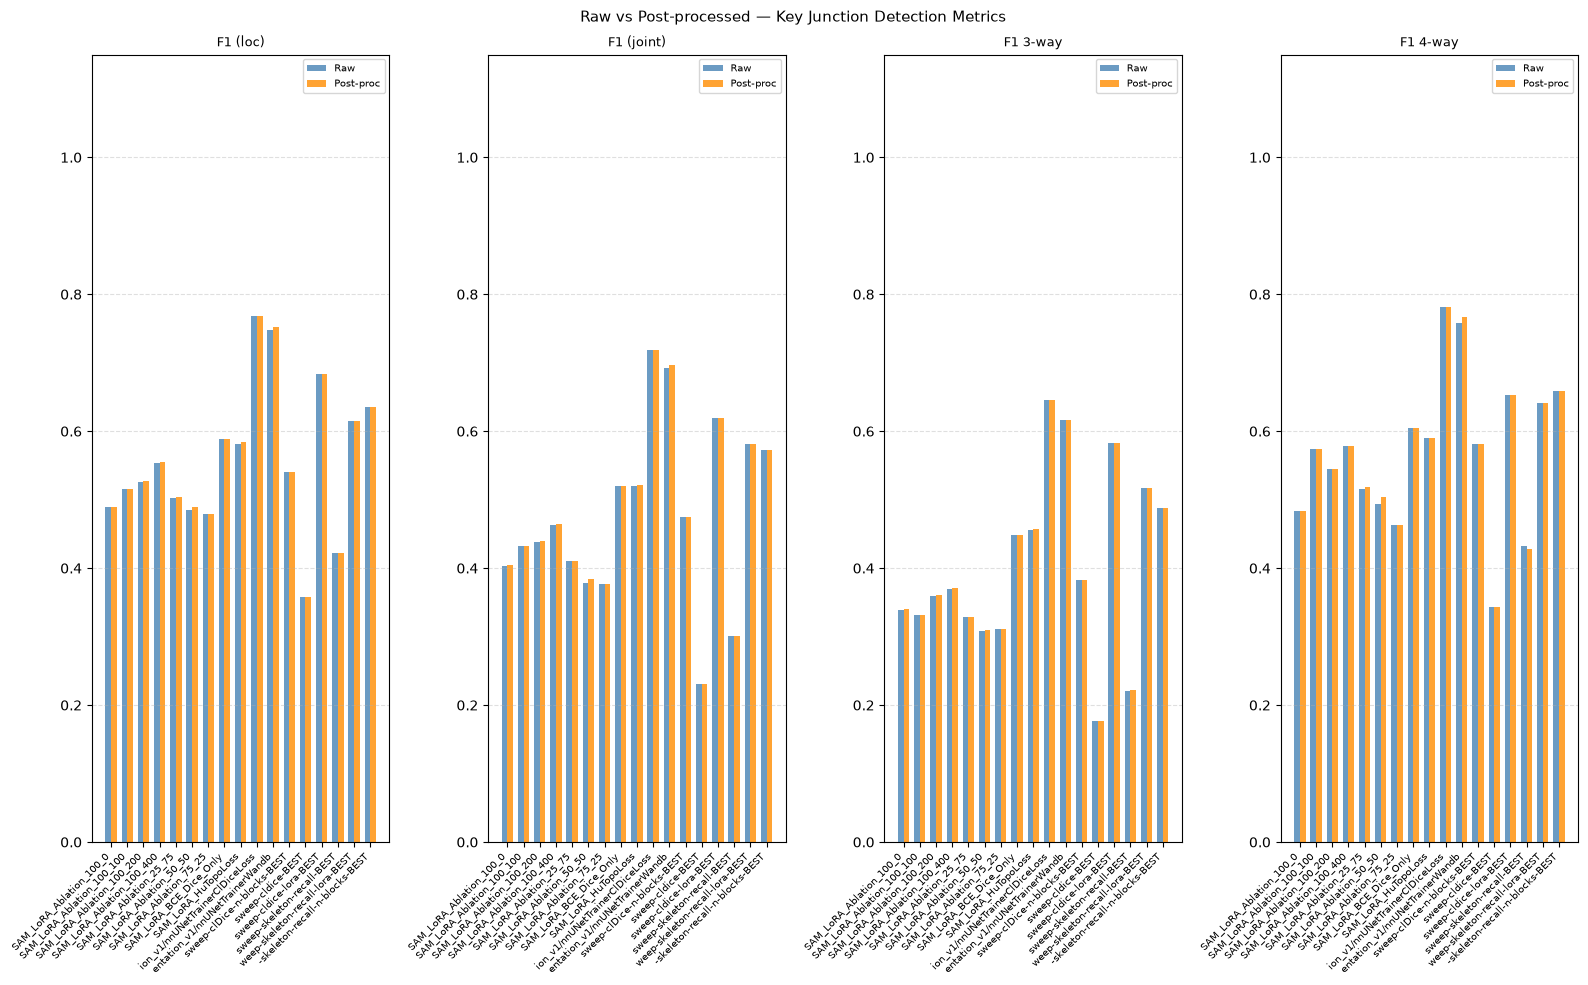

In [21]:
_KEY_METRICS = ["f1_loc", "class_f1_combined", "class_f1_3way", "class_f1_4way"]
_short_labels = [str(n)[-30:] for n in df_jd.index]
colors = plt.cm.tab10(np.linspace(0, 0.9, len(df_jd)))

_present = [m for m in _KEY_METRICS
            if f"raw_{m}" in df_jd.columns and f"pp_{m}" in df_jd.columns]

if _present:
    fig, axes = plt.subplots(1, len(_present), figsize=(4 * len(_present), max(4, len(df_jd) * 0.5 + 1.5)),
                             squeeze=False)
    axes = axes[0]
    x = np.arange(len(df_jd))
    width = 0.35

    for ax, metric in zip(axes, _present):
        raw_vals = df_jd[f"raw_{metric}"].astype(float).values
        pp_vals  = df_jd[f"pp_{metric}"].astype(float).values
        ax.bar(x - width / 2, raw_vals, width, label="Raw", color="steelblue", alpha=0.8)
        ax.bar(x + width / 2, pp_vals,  width, label="Post-proc", color="darkorange", alpha=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels(_short_labels, rotation=45, ha="right", fontsize=7)
        ax.set_ylim(0, 1.15)
        ax.set_title(_DISPLAY_RENAME.get(metric, metric), fontsize=9)
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        ax.legend(fontsize=7)

    fig.suptitle("Raw vs Post-processed — Key Junction Detection Metrics", fontsize=11)
    plt.tight_layout()
    plt.show()
    plt.close()
else:
    print("Key metric columns not found in dataframe.")


---
## Synthetic Data — Junction Detection vs. Fiber Density

$F_1$ per fiber range on the synthetic dataset(s) in `SYNTH_JD_DATASETS`, aggregated over all ground-truth image types (negative, replication fork, reversed fork). The fiber range is parsed from the image name (e.g. `reversed_fork_f13-18_0002`); TP / FP / FN are summed over all images of a range before computing $F_1$.
The shaded band of the baselines from `SYNTH_BASELINE_CSV` is ±1 std across their training seeds; our models are single runs, so they have no band.


,DINOv2 + MLP,Faster R-CNN,U-Net (Seg.) + Graph
Fibers per tile,,,
1–3,0.725 ± 0.021,0.986 ± 0.025,0.870
3–8,0.834 ± 0.035,0.955 ± 0.045,0.720
8–13,0.616 ± 0.063,1.000 ± 0.000,0.500
13–18,0.566 ± 0.030,0.910 ± 0.058,0.611
18–23,0.800 ± 0.018,0.961 ± 0.038,0.686
23–28,0.699 ± 0.051,0.935 ± 0.021,0.462
28–33,0.643 ± 0.020,0.927 ± 0.025,0.588
33–38,0.435 ± 0.000,0.905 ± 0.031,0.512


,F1_mean,tp,fp,fn,n_images
Fibers per tile,,,,,
1–3,0.8696,10,1,2,18
3–8,0.7200,9,4,3,18
8–13,0.5000,8,12,4,18
13–18,0.6111,11,13,1,18
18–23,0.6857,12,11,0,18
23–28,0.4615,9,18,3,18
28–33,0.5882,10,12,2,18
33–38,0.5116,11,20,1,18


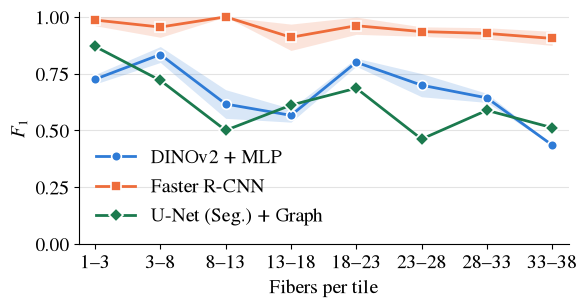

In [29]:

import re

SYNTH_SOURCE = "pp"         # "pp" (post-processed) or "raw" predictions
SYNTH_F1_KIND = "loc"       # "loc": class-agnostic localisation, "joint": location + junction type

# Model key (as in metrics.csv) -> legend label; unlisted models use their key
SYNTH_MODEL_LABELS = {
    "nnunet/Dataset021_SegmentationSynthetic/nnUNetTrainerClDiceLoss": "U-Net (Seg.) + Graph",
}
# Baseline name (column prefix of "<name>_F1_mean" in SYNTH_BASELINE_CSV) -> legend label
SYNTH_BASELINE_LABELS = {
    "dinov2_mlp": "DINOv2 + MLP",
    "faster_rcnn": "Faster R-CNN",
}

# e.g. reversed_fork_f13-18_0002 -> type, fibers_min, fibers_max
_SYNTH_STEM_PATTERN = r"^(?P<image_type>.+)_f(?P<fibers_min>\d+)-(?P<fibers_max>\d+)_\d+$"


def _synth_per_image_counts(eval_dir: Path, model: str) -> pd.DataFrame:
    """Per-image TP / FP / GT junction counts plus the image's fiber range."""
    safe_name = model.replace("/", "_")
    preds = pd.read_csv(eval_dir / f"predictions_{safe_name}.csv")
    preds = preds[preds["source"] == SYNTH_SOURCE]
    is_tp = preds["is_tp"].astype(bool)
    if SYNTH_F1_KIND == "joint":
        is_tp &= preds["pred_type"] == preds["matched_gt_type"]
    pred_counts = (preds.assign(tp=is_tp.astype(int), fp=(~is_tp).astype(int))
                   .groupby("image")[["tp", "fp"]].sum())

    # image_level lists every image (also those without predictions); each
    # synthetic positive image holds exactly one GT junction, checked below
    images = pd.read_csv(eval_dir / f"image_level_{safe_name}.csv", index_col="image")
    df = (images[["gt_positive"]].rename(columns={"gt_positive": "gt"})
          .join(pred_counts).fillna(0).astype(int))

    ranges = df.index.to_series().str.extract(_SYNTH_STEM_PATTERN)
    if ranges.isna().any().any():
        bad = ranges.index[ranges.isna().any(axis=1)].tolist()
        raise ValueError(f"Image names without fiber range: {bad[:5]}")
    df["image_type"] = ranges["image_type"]
    df["fibers_min"] = ranges["fibers_min"].astype(int)
    df["fibers_max"] = ranges["fibers_max"].astype(int)

    per_sample = pd.read_csv(eval_dir / f"per_sample_{safe_name}.csv", index_col="sample")
    gt_expected = per_sample["tp_loc"] + per_sample["fn_loc"]
    gt_found = df.groupby(df["image_type"] + "_f" + df["fibers_min"].astype(str)
                          + "-" + df["fibers_max"].astype(str))["gt"].sum()
    if not gt_found.sort_index().equals(gt_expected.sort_index()):
        raise ValueError(f"Per-image GT counts don't match {eval_dir.name}/per_sample "
                         f"(more than one GT junction per image?)")
    assert (df["tp"] <= df["gt"]).all()
    return df


def _f1(tp, fp, fn):
    denom = 2 * tp + fp + fn
    return np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0.0)


def _synth_f1_by_range(per_image: pd.DataFrame) -> pd.DataFrame:
    """F1 per fiber range from the TP / FP / FN counts pooled over the range's images."""
    rows = []
    for (fmin, fmax), g in per_image.groupby(["fibers_min", "fibers_max"]):
        tp, fp, fn = g["tp"].sum(), g["fp"].sum(), (g["gt"] - g["tp"]).sum()
        rows.append({
            "fibers_min": fmin, "fibers_max": fmax,
            "F1_mean": float(_f1(tp, fp, fn)),
            "F1_std": np.nan,  # single run, no spread
            "tp": tp, "fp": fp, "fn": fn, "n_images": len(g),
        })
    return pd.DataFrame(rows).sort_values("fibers_min").reset_index(drop=True)


# ── Curves: baselines first (fixed colours), then our models ─────────────────
synth_curves: dict[str, pd.DataFrame] = {}

df_synth_baseline = pd.read_csv(SYNTH_BASELINE_CSV)
for _col in df_synth_baseline.columns:
    _m = re.fullmatch(r"(.+)_F1_mean", _col)
    if _m and f"{_m[1]}_F1_std" in df_synth_baseline.columns:
        synth_curves[SYNTH_BASELINE_LABELS.get(_m[1], _m[1])] = (
            df_synth_baseline[["fibers_min", "fibers_max", _col, f"{_m[1]}_F1_std"]]
            .set_axis(["fibers_min", "fibers_max", "F1_mean", "F1_std"], axis=1))

synth_counts: dict[str, pd.DataFrame] = {}
for _ds in SYNTH_JD_DATASETS:
    for _model in jd_results[_ds].index:
        _label = SYNTH_MODEL_LABELS.get(_model, _model)
        if len(SYNTH_JD_DATASETS) > 1:
            _label = f"{_label} ({_ds})"
        _curve = _synth_f1_by_range(_synth_per_image_counts(JD_EVAL_DIRS[_ds], _model))
        synth_counts[_label] = _curve
        synth_curves[_label] = _curve[["fibers_min", "fibers_max", "F1_mean", "F1_std"]]

_synth_ranges = sorted({(int(a), int(b)) for c in synth_curves.values()
                        for a, b in zip(c["fibers_min"], c["fibers_max"])})
_range_labels = [f"{a}–{b}" for a, b in _synth_ranges]

# ── Table: F1 mean ± std per fiber range ─────────────────────────────────────
df_synth_f1 = pd.DataFrame({
    label: ["–" if pd.isna(r.F1_mean) else f"{r.F1_mean:.3f}" if pd.isna(r.F1_std)
            else f"{r.F1_mean:.3f} ± {r.F1_std:.3f}"
            for r in c.set_index(["fibers_min", "fibers_max"]).reindex(_synth_ranges).itertuples()]
    for label, c in synth_curves.items()
}, index=pd.Index(_range_labels, name="Fibers per tile"))
display(df_synth_f1)
for _label, _counts in synth_counts.items():
    display(HTML(f"<h4>{_label} — counts ({SYNTH_SOURCE}, {SYNTH_F1_KIND})</h4>"))
    display(_counts.set_index(pd.Index(_range_labels, name="Fibers per tile"))
            .drop(columns=["fibers_min", "fibers_max", "F1_std"]))

# ── Line plot ────────────────────────────────────────────────────────────────
_SYNTH_COLORS = ["#2E7BD6", "#EE6C3A", "#1B7A4E", "#7B4FB8", "#C8407A"]
_SYNTH_MARKERS = ["o", "s", "D", "^", "v"]

_FIG_DIR = Path("figures")
_FIG_DIR.mkdir(exist_ok=True)

with plt.rc_context({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "STIX Two Text", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 14,
}):
    fig, ax = plt.subplots(figsize=(6.0, 3.3))
    x = np.arange(len(_synth_ranges))
    for i, (label, curve) in enumerate(synth_curves.items()):
        c = curve.set_index(["fibers_min", "fibers_max"]).reindex(_synth_ranges)
        mean = c["F1_mean"].to_numpy(float)
        std = c["F1_std"].to_numpy(float)
        color = _SYNTH_COLORS[i % len(_SYNTH_COLORS)]
        if not np.isnan(std).all():
            ax.fill_between(x, np.clip(mean - std, 0, 1), np.clip(mean + std, 0, 1),
                            color=color, alpha=0.18, linewidth=0, zorder=2)
        ax.plot(x, mean, color=color, marker=_SYNTH_MARKERS[i % len(_SYNTH_MARKERS)],
                linewidth=2, markersize=7, markeredgecolor="white", markeredgewidth=1.2,
                label=label, zorder=3)

    ax.set_xticks(x, _range_labels)
    ax.set_xlim(-0.25, len(x) - 0.75)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("Fibers per tile")
    ax.set_ylabel(r"$F_1$")
    ax.yaxis.grid(True, color="#e3e3e3", linewidth=0.8)
    ax.set_axisbelow(True)
    for _side in ("top", "right"):
        ax.spines[_side].set_visible(False)
    ax.legend(loc="lower left", frameon=False)

    plt.tight_layout()
    fig.savefig(_FIG_DIR / "synthetic_density_f1.pdf", bbox_inches="tight")
    fig.savefig(_FIG_DIR / "synthetic_density_f1.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


---
## Segmentation ↔ Junction Detection Correlation Analysis

Spearman correlation coefficients between segmentation metrics (x) and post-processed junction detection metrics (y), plus scatter plots with OLS trend lines. Each data point is one model (n=17).

In [23]:
from scipy import stats as _scipy_stats
import matplotlib
import matplotlib.cm as _mcm
import matplotlib.colors as _mcolors

# ── Metric definitions ────────────────────────────────────────────────────────
SEG_CORR_COLS = {
    "Dice":                "Dice",
    "clDice":              "clDice",
    "tprec":               r"$T_{\text{prec}}$",
    "tsens":               r"$T_{\text{sens}}$",
    "Wasserstein B0 Raw":  r"$W_{H_0}$ (Prob.)",
    "Bottleneck B0 Raw":   r"$d_{B,H_0}$ (Prob.)",
    "Wasserstein B1 Raw":  r"$W_{H_1}$ (Prob.)",
    "Bottleneck B1 Raw":   r"$d_{B,H_1}$ (Prob.)",
    "Wasserstein B0 SDT":  r"$W_{H_0}$ (SDT)",
    "Bottleneck B0 SDT":   r"$d_{B,H_0}$ (SDT)",
    "Wasserstein B1 SDT":  r"$W_{H_1}$ (SDT)",
    "Bottleneck B1 SDT":   r"$d_{B,H_1}$ (SDT)",
}
SEG_LOWER_BETTER = {
    "Wasserstein B0 Raw", "Bottleneck B0 Raw",
    "Wasserstein B1 Raw", "Bottleneck B1 Raw",
    "Wasserstein B0 SDT", "Bottleneck B0 SDT",
    "Wasserstein B1 SDT", "Bottleneck B1 SDT",
}

JD_LOC_COLS = {
    "pp_precision_loc":            "Precision (loc)",
    "pp_recall_loc":               "Recall (loc)",
}
JD_DET_RECALL_COLS = {
    "pp_detection_recall_3way":    "Det. Recall 3-way",
    "pp_detection_recall_4way":    "Det. Recall 4-way",
}
JD_JOINT_COMBINED_COLS = {
    "pp_class_precision_combined": "Precision (joint)",
    "pp_class_recall_combined":    "Recall (joint)",
}
JD_JOINT_3WAY_COLS = {
    "pp_class_precision_3way":     "Precision 3-way",
    "pp_class_recall_3way":        "Recall 3-way",
}
JD_JOINT_4WAY_COLS = {
    "pp_class_precision_4way":     "Precision 4-way",
    "pp_class_recall_4way":        "Recall 4-way",
}
ALL_JD_CORR_COLS = {
    **JD_LOC_COLS,
    **JD_DET_RECALL_COLS,
    **JD_JOINT_COMBINED_COLS,
    **JD_JOINT_3WAY_COLS,
    **JD_JOINT_4WAY_COLS,
}

# ── Models to exclude from correlation computation ───────────────────────────
# (df_merged and the scatter plots still include all models)
_CORR_IGNORE_MODELS = [
    #"sweep-cldice-BEST",
    #"sweep-skeleton-recall-BEST",
]

# ── Merge: select only needed columns to avoid column-name conflicts ─────────
_seg_keep = [c for c in SEG_CORR_COLS if c in df_seg.columns]
_jd_keep  = [c for c in ALL_JD_CORR_COLS if c in df_jd.columns]
df_merged = df_seg[_seg_keep].join(df_jd[_jd_keep], how="inner")
print(f"Merged dataset: {len(df_merged)} models, "
      f"{len(_seg_keep)} seg cols, {len(_jd_keep)} JD cols")

# Filtered view used only for correlation computation
_df_corr_input = df_merged.drop(
    index=[m for m in _CORR_IGNORE_MODELS if m in df_merged.index]
)
if _CORR_IGNORE_MODELS:
    print(f"Correlation computed on {len(_df_corr_input)} models "
          f"(ignoring: {', '.join(_CORR_IGNORE_MODELS)})")

# ── Spearman correlation computation ─────────────────────────────────────────
_corr_rows = {}
for seg_col, seg_label in SEG_CORR_COLS.items():
    if seg_col not in _df_corr_input.columns:
        continue
    _corr_rows[seg_label] = {}
    for jd_col, jd_label in ALL_JD_CORR_COLS.items():
        if jd_col not in _df_corr_input.columns:
            _corr_rows[seg_label][jd_label] = np.nan
            continue
        valid = _df_corr_input[[seg_col, jd_col]].dropna()
        if len(valid) >= 3:
            r, _ = _scipy_stats.spearmanr(valid[seg_col].astype(float),
                                          valid[jd_col].astype(float))
        else:
            r = np.nan
        _corr_rows[seg_label][jd_label] = r

df_corr = pd.DataFrame(_corr_rows).T   # rows = seg metric, cols = JD metric

# ── Notebook display: continuous heatmap, no threshold ───────────────────────
df_corr_str = pd.DataFrame(
    {jd: {seg: ("–" if pd.isna(df_corr.loc[seg, jd])
                else f"{df_corr.loc[seg, jd]:+.3f}")
          for seg in df_corr.index}
     for jd in df_corr.columns}
)

# Plain-text labels for notebook (Styler doesn't render LaTeX math)
_NOTEBOOK_LABELS = {
    r"$T_{\text{prec}}$":    "T_prec",
    r"$T_{\text{sens}}$":    "T_sens",
    r"$W_{H_0}$ (Prob.)":    "W_H0 (Prob.)",
    r"$d_{B,H_0}$ (Prob.)":  "d_B,H0 (Prob.)",
    r"$W_{H_1}$ (Prob.)":    "W_H1 (Prob.)",
    r"$d_{B,H_1}$ (Prob.)":  "d_B,H1 (Prob.)",
    r"$W_{H_0}$ (SDT)":      "W_H0 (SDT)",
    r"$d_{B,H_0}$ (SDT)":    "d_B,H0 (SDT)",
    r"$W_{H_1}$ (SDT)":      "W_H1 (SDT)",
    r"$d_{B,H_1}$ (SDT)":    "d_B,H1 (SDT)",
}
df_corr_str_display = df_corr_str.rename(index=_NOTEBOOK_LABELS)

_cmap = matplotlib.colormaps["RdBu"]

def _cell_bg(val_str):
    try:
        v = float(val_str)
    except (ValueError, TypeError):
        return "background-color: white"
    rgba = _cmap((v + 1) / 2)   # map [-1, 1] -> [0, 1]
    hex_color = _mcolors.to_hex(rgba)
    luminance = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
    text_color = "black" if luminance > 0.5 else "white"
    return f"background-color: {hex_color}; color: {text_color}"

display(
    df_corr_str_display.style
    .map(_cell_bg)
    .set_table_styles([{
        "selector": "th, td",
        "props": "font-family: inherit; font-size: inherit; "
                 "text-align: center; white-space: nowrap; padding: 4px 8px;"
    }])
)

# ── LaTeX table generation for thesis ────────────────────────────────────────
_LATEX_COL_GROUPS = [
    ("Class-Agnostic Detection",
     ["Precision (loc)", "Recall (loc)",
      "Det. Recall 3-way", "Det. Recall 4-way"]),
    ("Joint Combined",
     ["Precision (joint)", "Recall (joint)"]),
    ("Joint 3-way",
     ["Precision 3-way", "Recall 3-way"]),
    ("Joint 4-way",
     ["Precision 4-way", "Recall 4-way"]),
]

_LATEX_COL_HEADERS = {
    "Precision (loc)":   r"$P_{\text{det}}$",
    "Recall (loc)":      r"$R_{\text{det}}$",
    "Det. Recall 3-way": r"$R_{\text{det}}^{\text{3-way}}$",
    "Det. Recall 4-way": r"$R_{\text{det}}^{\text{4-way}}$",
    "Precision (joint)": r"$P_{\text{joint}}$",
    "Recall (joint)":    r"$R_{\text{joint}}$",
    "Precision 3-way":   r"$P_{\text{joint}}^{\text{3-way}}$",
    "Recall 3-way":      r"$R_{\text{joint}}^{\text{3-way}}$",
    "Precision 4-way":   r"$P_{\text{joint}}^{\text{4-way}}$",
    "Recall 4-way":      r"$R_{\text{joint}}^{\text{4-way}}$",
}

def _latex_cell(r):
    if pd.isna(r):
        return "--"
    intensity = int(round((abs(r) ** 1.8) * 75))
    if intensity == 0:
        return f"${r:+.3f}$"
    color = "blue" if r > 0 else "red"
    if intensity >= 50:
        return f"\\cellcolor{{{color}!{intensity}}}\\textcolor{{white}}{{${r:+.3f}$}}"
    return f"\\cellcolor{{{color}!{intensity}}}${r:+.3f}$"

def _build_latex_table(df_corr, n_models):
    ordered_cols = [c for _, cols in _LATEX_COL_GROUPS for c in cols]
    col_spec = "l " + " ".join(
        " ".join(["c"] * len(cols)) for _, cols in _LATEX_COL_GROUPS
    )
    group_header = " & " + " & ".join(
        f"\\multicolumn{{{len(cols)}}}{{c}}{{{name}}}"
        for name, cols in _LATEX_COL_GROUPS
    ) + r" \\"

    cmidrules = []
    start = 2
    for _, cols in _LATEX_COL_GROUPS:
        end = start + len(cols) - 1
        cmidrules.append(f"\\cmidrule(lr){{{start}-{end}}}")
        start = end + 1
    cmidrule_line = " ".join(cmidrules)

    sub_header = " & " + " & ".join(
        _LATEX_COL_HEADERS[c] for c in ordered_cols
    ) + r" \\"

    body_lines = []
    for seg_key in df_corr.index:
        cells = [seg_key] + [_latex_cell(df_corr.loc[seg_key, c])
                             for c in ordered_cols]
        body_lines.append(" & ".join(cells) + r" \\")

    return (
        r"\begin{table}[h]" + "\n"
        r"\centering" + "\n"
        r"\caption{Spearman rank correlation coefficients $r_s$ between "
        r"segmentation metrics and junction detection/classification metrics, "
        f"computed across $n={n_models}$ models from Experiments 1 and 2. "
        r"Cell color encodes correlation strength and direction: blue for "
        r"positive, red for negative, with intensity proportional to $|r_s|$.}"
        + "\n"
        r"\label{tab:spearman_correlations}" + "\n"
        r"\renewcommand{\arraystretch}{1.3}" + "\n"
        r"\setlength{\tabcolsep}{3pt}" + "\n"
        f"\\begin{{tabular}}{{{col_spec}}}" + "\n"
        r"\toprule" + "\n"
        + group_header + "\n"
        + cmidrule_line + "\n"
        + sub_header + "\n"
        r"\midrule" + "\n"
        + "\n".join(body_lines) + "\n"
        r"\bottomrule" + "\n"
        r"\end{tabular}" + "\n"
        r"\end{table}"
    )

print("\n" + "=" * 70)
print("LaTeX table (paste into thesis):")
print("=" * 70 + "\n")
print(_build_latex_table(df_corr, len(_df_corr_input)))


Merged dataset: 17 models, 12 seg cols, 10 JD cols


,Precision (loc),Recall (loc),Det. Recall 3-way,Det. Recall 4-way,Precision (joint),Recall (joint),Precision 3-way,Recall 3-way,Precision 4-way,Recall 4-way
Dice,+0.627,+0.611,+0.572,+0.574,+0.632,+0.642,+0.625,+0.572,+0.596,+0.693
clDice,+0.630,+0.645,+0.557,+0.710,+0.632,+0.616,+0.620,+0.557,+0.561,+0.630
T_prec,+0.083,+0.361,+0.239,+0.559,+0.083,+0.123,+0.083,+0.239,+0.042,+0.122
T_sens,+0.936,+0.655,+0.778,+0.469,+0.931,+0.901,+0.922,+0.778,+0.922,+0.899
W_H0 (Prob.),-0.475,-0.528,-0.526,-0.525,-0.502,-0.463,-0.483,-0.526,-0.471,-0.442
"d_B,H0 (Prob.)",-0.537,-0.499,-0.568,-0.358,-0.591,-0.545,-0.583,-0.568,-0.525,-0.526
W_H1 (Prob.),-0.475,-0.392,-0.407,-0.365,-0.500,-0.438,-0.475,-0.407,-0.458,-0.441
"d_B,H1 (Prob.)",-0.468,-0.441,-0.514,-0.318,-0.493,-0.433,-0.458,-0.514,-0.453,-0.397
W_H0 (SDT),-0.782,-0.629,-0.648,-0.619,-0.809,-0.788,-0.828,-0.648,-0.689,-0.830
"d_B,H0 (SDT)",-0.654,-0.518,-0.559,-0.554,-0.669,-0.655,-0.691,-0.559,-0.593,-0.670



LaTeX table (paste into thesis):

\begin{table}[h]
\centering
\caption{Spearman rank correlation coefficients $r_s$ between segmentation metrics and junction detection/classification metrics, computed across $n=17$ models from Experiments 1 and 2. Cell color encodes correlation strength and direction: blue for positive, red for negative, with intensity proportional to $|r_s|$.}
\label{tab:spearman_correlations}
\renewcommand{\arraystretch}{1.3}
\setlength{\tabcolsep}{3pt}
\begin{tabular}{l c c c c c c c c c c}
\toprule
 & \multicolumn{4}{c}{Class-Agnostic Detection} & \multicolumn{2}{c}{Joint Combined} & \multicolumn{2}{c}{Joint 3-way} & \multicolumn{2}{c}{Joint 4-way} \\
\cmidrule(lr){2-5} \cmidrule(lr){6-7} \cmidrule(lr){8-9} \cmidrule(lr){10-11}
 & $P_{\text{det}}$ & $R_{\text{det}}$ & $R_{\text{det}}^{\text{3-way}}$ & $R_{\text{det}}^{\text{4-way}}$ & $P_{\text{joint}}$ & $R_{\text{joint}}$ & $P_{\text{joint}}^{\text{3-way}}$ & $R_{\text{joint}}^{\text{3-way}}$ & $P_{\text{joint}}

In [24]:
# Spearman correlations: segmentation metrics vs. detection P / R / F1
# Reuses SEG_CORR_COLS, _CORR_IGNORE_MODELS, _NOTEBOOK_LABELS, _cell_bg and
# _latex_cell from the correlation cell above.

# ── Metric definitions ────────────────────────────────────────────────────────
# pp_f1_loc comes from the CSV; pp_class_f1_combined is derived in the
# combined-metrics cell further up.
JD_F1_CORR_COLS = {
    "pp_precision_loc":            "Precision (loc)",
    "pp_recall_loc":               "Recall (loc)",
    "pp_f1_loc":                   "F1 (loc)",
    "pp_class_precision_combined": "Precision (joint)",
    "pp_class_recall_combined":    "Recall (joint)",
    "pp_class_f1_combined":        "F1 (joint)",
}

# ── Merge ─────────────────────────────────────────────────────────────────────
_seg_keep_f1 = [c for c in SEG_CORR_COLS if c in df_seg.columns]
_jd_keep_f1  = [c for c in JD_F1_CORR_COLS if c in df_jd.columns]
df_merged_f1 = df_seg[_seg_keep_f1].join(df_jd[_jd_keep_f1], how="inner")
print(f"Merged dataset: {len(df_merged_f1)} models, "
      f"{len(_seg_keep_f1)} seg cols, {len(_jd_keep_f1)} JD cols")

_df_corr_input_f1 = df_merged_f1.drop(
    index=[m for m in _CORR_IGNORE_MODELS if m in df_merged_f1.index]
)
if _CORR_IGNORE_MODELS:
    print(f"Correlation computed on {len(_df_corr_input_f1)} models "
          f"(ignoring: {', '.join(_CORR_IGNORE_MODELS)})")

# ── Spearman correlation computation ─────────────────────────────────────────
_corr_rows_f1 = {}
for seg_col, seg_label in SEG_CORR_COLS.items():
    if seg_col not in _df_corr_input_f1.columns:
        continue
    _corr_rows_f1[seg_label] = {}
    for jd_col, jd_label in JD_F1_CORR_COLS.items():
        if jd_col not in _df_corr_input_f1.columns:
            _corr_rows_f1[seg_label][jd_label] = np.nan
            continue
        valid = _df_corr_input_f1[[seg_col, jd_col]].dropna()
        if len(valid) >= 3:
            r, _ = _scipy_stats.spearmanr(valid[seg_col].astype(float),
                                          valid[jd_col].astype(float))
        else:
            r = np.nan
        _corr_rows_f1[seg_label][jd_label] = r

df_corr_f1 = pd.DataFrame(_corr_rows_f1).T   # rows = seg metric, cols = JD metric

# ── Notebook display: continuous heatmap, no threshold ───────────────────────
df_corr_f1_str = pd.DataFrame(
    {jd: {seg: ("–" if pd.isna(df_corr_f1.loc[seg, jd])
                else f"{df_corr_f1.loc[seg, jd]:+.3f}")
          for seg in df_corr_f1.index}
     for jd in df_corr_f1.columns}
)

display(
    df_corr_f1_str.rename(index=_NOTEBOOK_LABELS).style
    .map(_cell_bg)
    .set_table_styles([{
        "selector": "th, td",
        "props": "font-family: inherit; font-size: inherit; "
                 "text-align: center; white-space: nowrap; padding: 4px 8px;"
    }])
)

# ── LaTeX table generation for thesis ────────────────────────────────────────
_LATEX_F1_COL_GROUPS = [
    ("Class-Agnostic Detection",
     ["Precision (loc)", "Recall (loc)", "F1 (loc)"]),
    ("Joint Combined",
     ["Precision (joint)", "Recall (joint)", "F1 (joint)"]),
]

_LATEX_F1_COL_HEADERS = {
    "Precision (loc)":   r"$P_{\text{det}}$",
    "Recall (loc)":      r"$R_{\text{det}}$",
    "F1 (loc)":          r"$F_{1,\text{det}}$",
    "Precision (joint)": r"$P_{\text{joint}}$",
    "Recall (joint)":    r"$R_{\text{joint}}$",
    "F1 (joint)":        r"$F_{1,\text{joint}}$",
}

def _build_latex_table_f1(df_corr, n_models):
    ordered_cols = [c for _, cols in _LATEX_F1_COL_GROUPS for c in cols]
    col_spec = "l " + " ".join(
        " ".join(["c"] * len(cols)) for _, cols in _LATEX_F1_COL_GROUPS
    )
    group_header = " & " + " & ".join(
        f"\\multicolumn{{{len(cols)}}}{{c}}{{{name}}}"
        for name, cols in _LATEX_F1_COL_GROUPS
    ) + r" \\"

    cmidrules = []
    start = 2
    for _, cols in _LATEX_F1_COL_GROUPS:
        end = start + len(cols) - 1
        cmidrules.append(f"\\cmidrule(lr){{{start}-{end}}}")
        start = end + 1
    cmidrule_line = " ".join(cmidrules)

    sub_header = " & " + " & ".join(
        _LATEX_F1_COL_HEADERS[c] for c in ordered_cols
    ) + r" \\"

    body_lines = []
    for seg_key in df_corr.index:
        cells = [seg_key] + [_latex_cell(df_corr.loc[seg_key, c])
                             for c in ordered_cols]
        body_lines.append(" & ".join(cells) + r" \\")

    return (
        r"\begin{table}[h]" + "\n"
        r"\centering" + "\n"
        r"\caption{Spearman rank correlation coefficients $r_s$ between "
        r"segmentation metrics and junction detection precision, recall and "
        r"$F_1$ (class-agnostic and joint), "
        f"computed across $n={n_models}$ models from Experiments 1 and 2. "
        r"Cell color encodes correlation strength and direction: blue for "
        r"positive, red for negative, with intensity proportional to $|r_s|$.}"
        + "\n"
        r"\label{tab:spearman_correlations_f1}" + "\n"
        r"\renewcommand{\arraystretch}{1.3}" + "\n"
        r"\setlength{\tabcolsep}{3pt}" + "\n"
        f"\\begin{{tabular}}{{{col_spec}}}" + "\n"
        r"\toprule" + "\n"
        + group_header + "\n"
        + cmidrule_line + "\n"
        + sub_header + "\n"
        r"\midrule" + "\n"
        + "\n".join(body_lines) + "\n"
        r"\bottomrule" + "\n"
        r"\end{tabular}" + "\n"
        r"\end{table}"
    )

print("\n" + "=" * 70)
print("LaTeX table (paste into thesis):")
print("=" * 70 + "\n")
print(_build_latex_table_f1(df_corr_f1, len(_df_corr_input_f1)))

Merged dataset: 17 models, 12 seg cols, 6 JD cols


,Precision (loc),Recall (loc),F1 (loc),Precision (joint),Recall (joint),F1 (joint)
Dice,+0.627,+0.611,+0.645,+0.632,+0.642,+0.635
clDice,+0.630,+0.645,+0.637,+0.632,+0.616,+0.642
T_prec,+0.083,+0.361,+0.103,+0.083,+0.123,+0.098
T_sens,+0.936,+0.655,+0.917,+0.931,+0.901,+0.929
W_H0 (Prob.),-0.475,-0.528,-0.483,-0.502,-0.463,-0.505
"d_B,H0 (Prob.)",-0.537,-0.499,-0.551,-0.591,-0.545,-0.569
W_H1 (Prob.),-0.475,-0.392,-0.466,-0.500,-0.438,-0.498
"d_B,H1 (Prob.)",-0.468,-0.441,-0.456,-0.493,-0.433,-0.488
W_H0 (SDT),-0.782,-0.629,-0.779,-0.809,-0.788,-0.806
"d_B,H0 (SDT)",-0.654,-0.518,-0.647,-0.669,-0.655,-0.659



LaTeX table (paste into thesis):

\begin{table}[h]
\centering
\caption{Spearman rank correlation coefficients $r_s$ between segmentation metrics and junction detection precision, recall and $F_1$ (class-agnostic and joint), computed across $n=17$ models from Experiments 1 and 2. Cell color encodes correlation strength and direction: blue for positive, red for negative, with intensity proportional to $|r_s|$.}
\label{tab:spearman_correlations_f1}
\renewcommand{\arraystretch}{1.3}
\setlength{\tabcolsep}{3pt}
\begin{tabular}{l c c c c c c}
\toprule
 & \multicolumn{3}{c}{Class-Agnostic Detection} & \multicolumn{3}{c}{Joint Combined} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7}
 & $P_{\text{det}}$ & $R_{\text{det}}$ & $F_{1,\text{det}}$ & $P_{\text{joint}}$ & $R_{\text{joint}}$ & $F_{1,\text{joint}}$ \\
\midrule
Dice & \cellcolor{blue!32}$+0.627$ & \cellcolor{blue!31}$+0.611$ & \cellcolor{blue!34}$+0.645$ & \cellcolor{blue!33}$+0.632$ & \cellcolor{blue!34}$+0.642$ & \cellcolor{blue!33}$+0.635$

In [25]:
df_merged.columns

Index(['Dice', 'clDice', 'tprec', 'tsens', 'Wasserstein B0 Raw',
       'Bottleneck B0 Raw', 'Wasserstein B1 Raw', 'Bottleneck B1 Raw',
       'Wasserstein B0 SDT', 'Bottleneck B0 SDT', 'Wasserstein B1 SDT',
       'Bottleneck B1 SDT', 'pp_precision_loc', 'pp_recall_loc',
       'pp_detection_recall_3way', 'pp_detection_recall_4way',
       'pp_class_precision_combined', 'pp_class_recall_combined',
       'pp_class_precision_3way', 'pp_class_recall_3way',
       'pp_class_precision_4way', 'pp_class_recall_4way'],
      dtype='str')

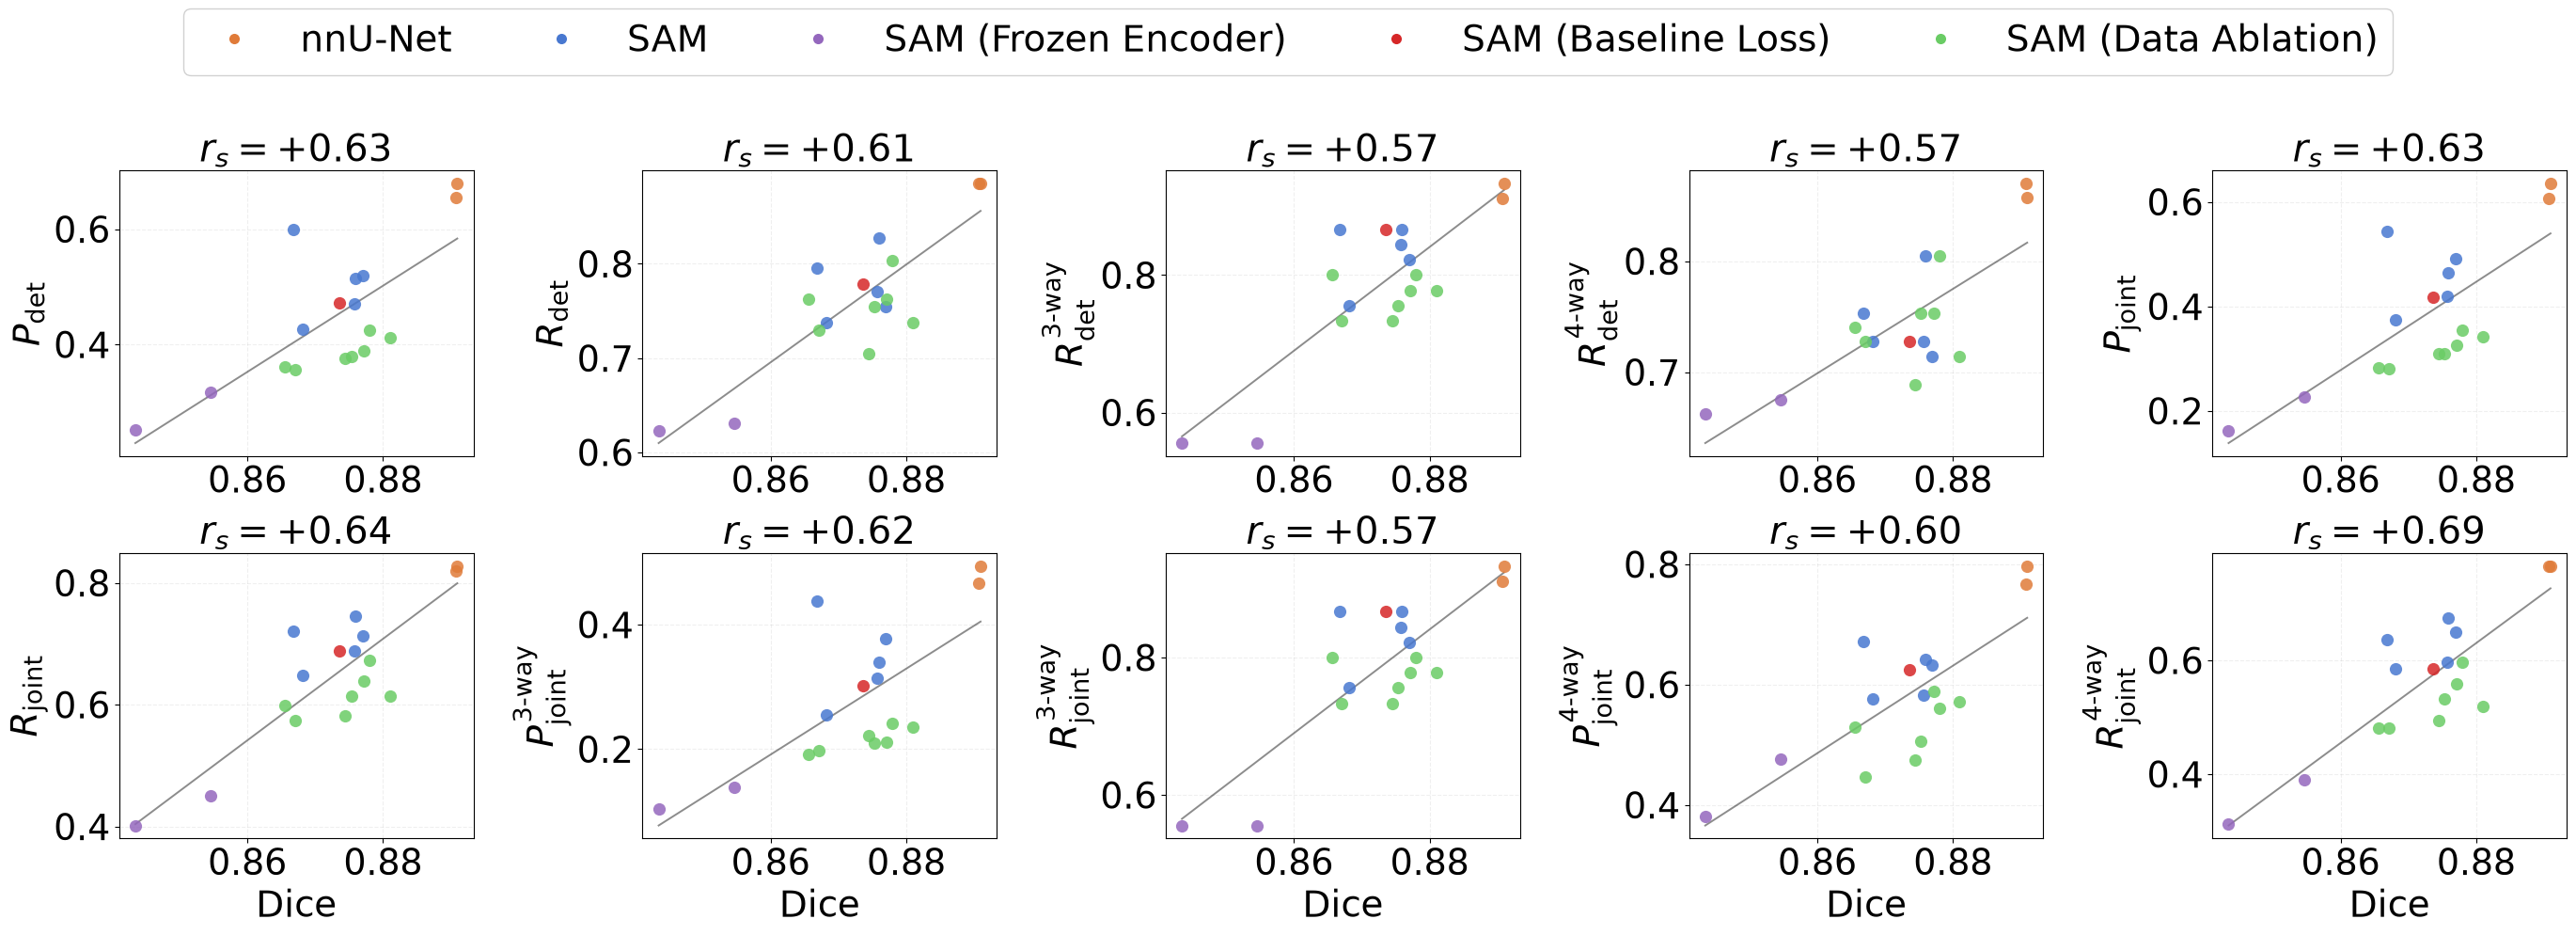

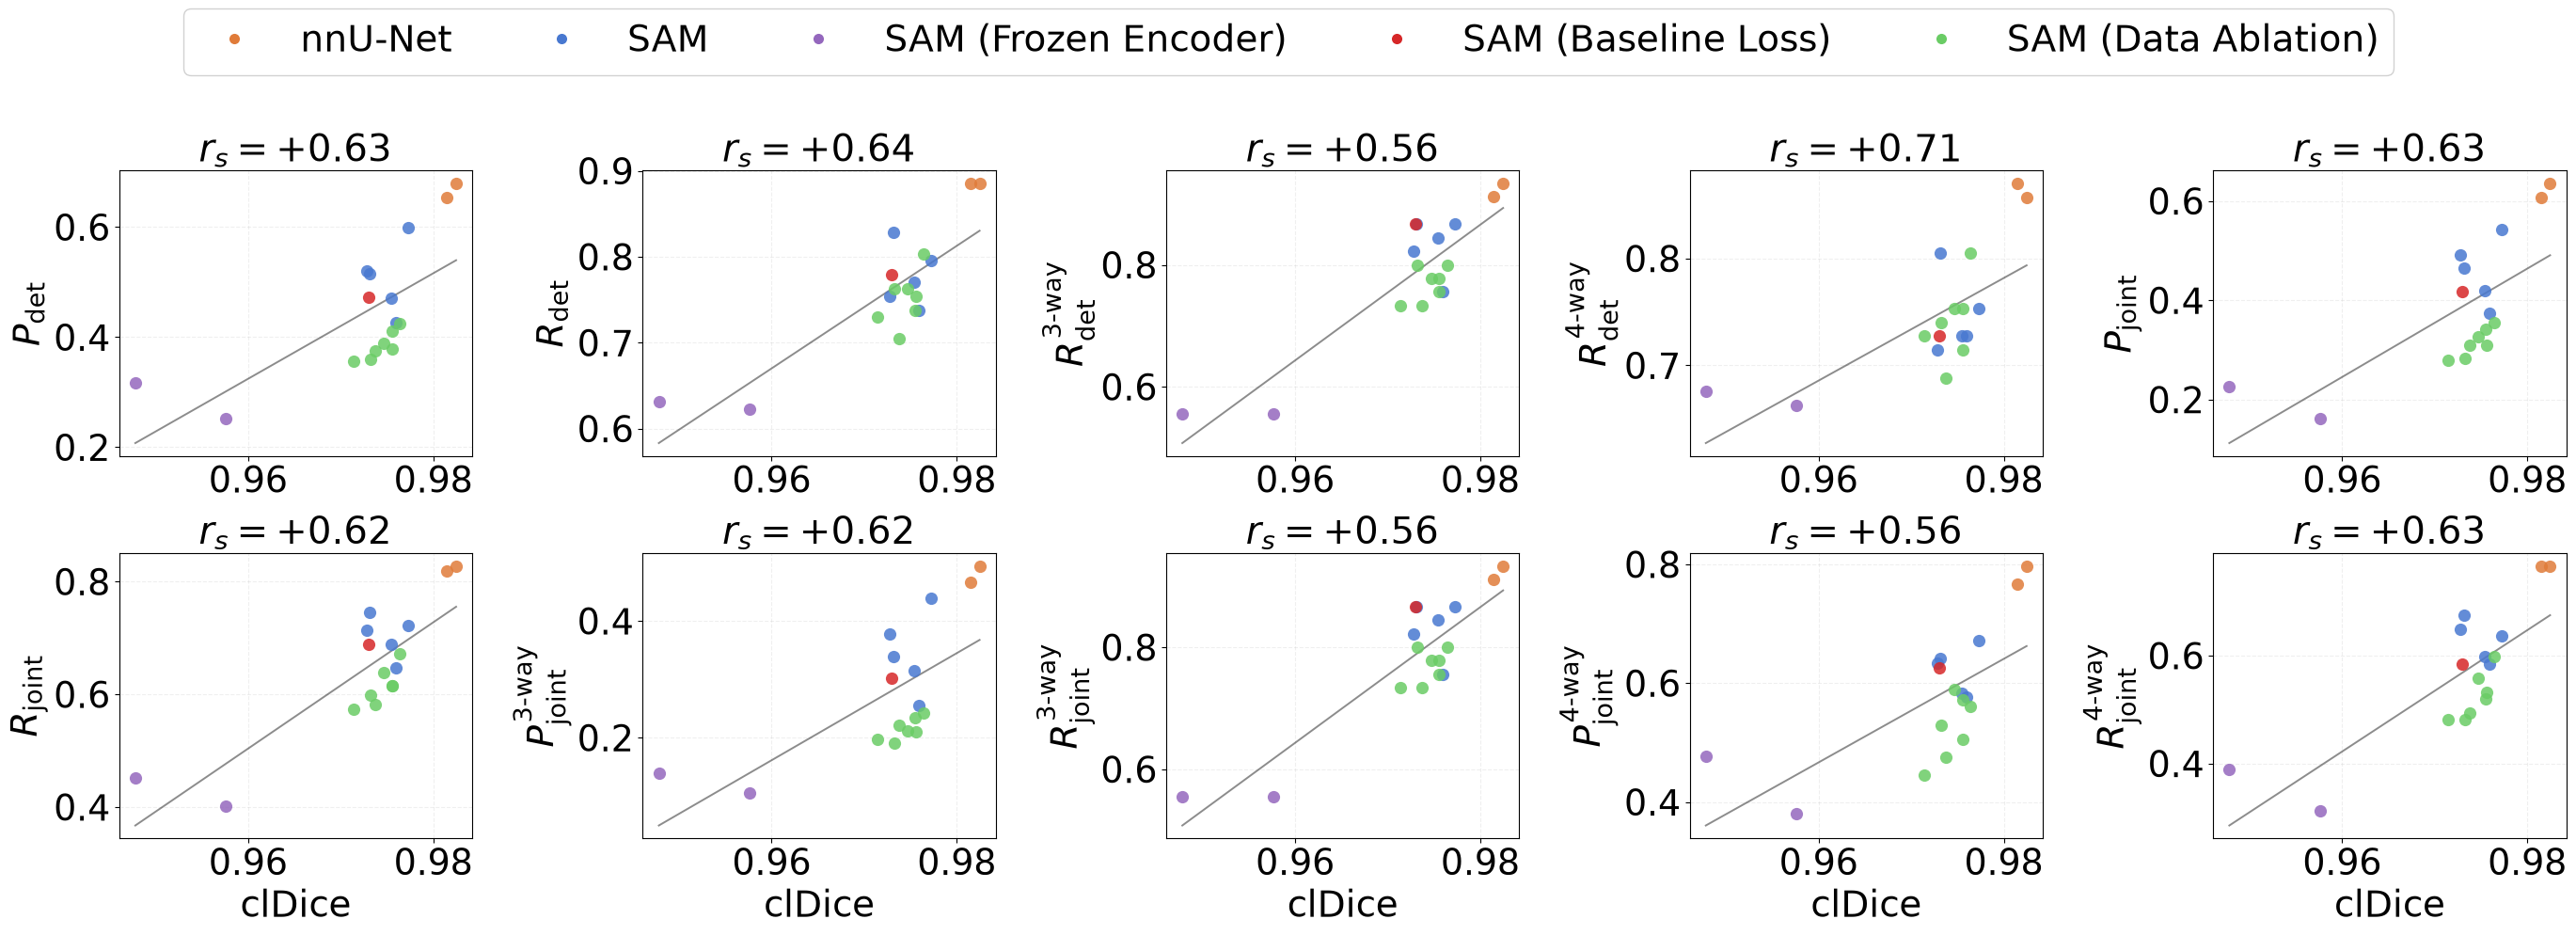

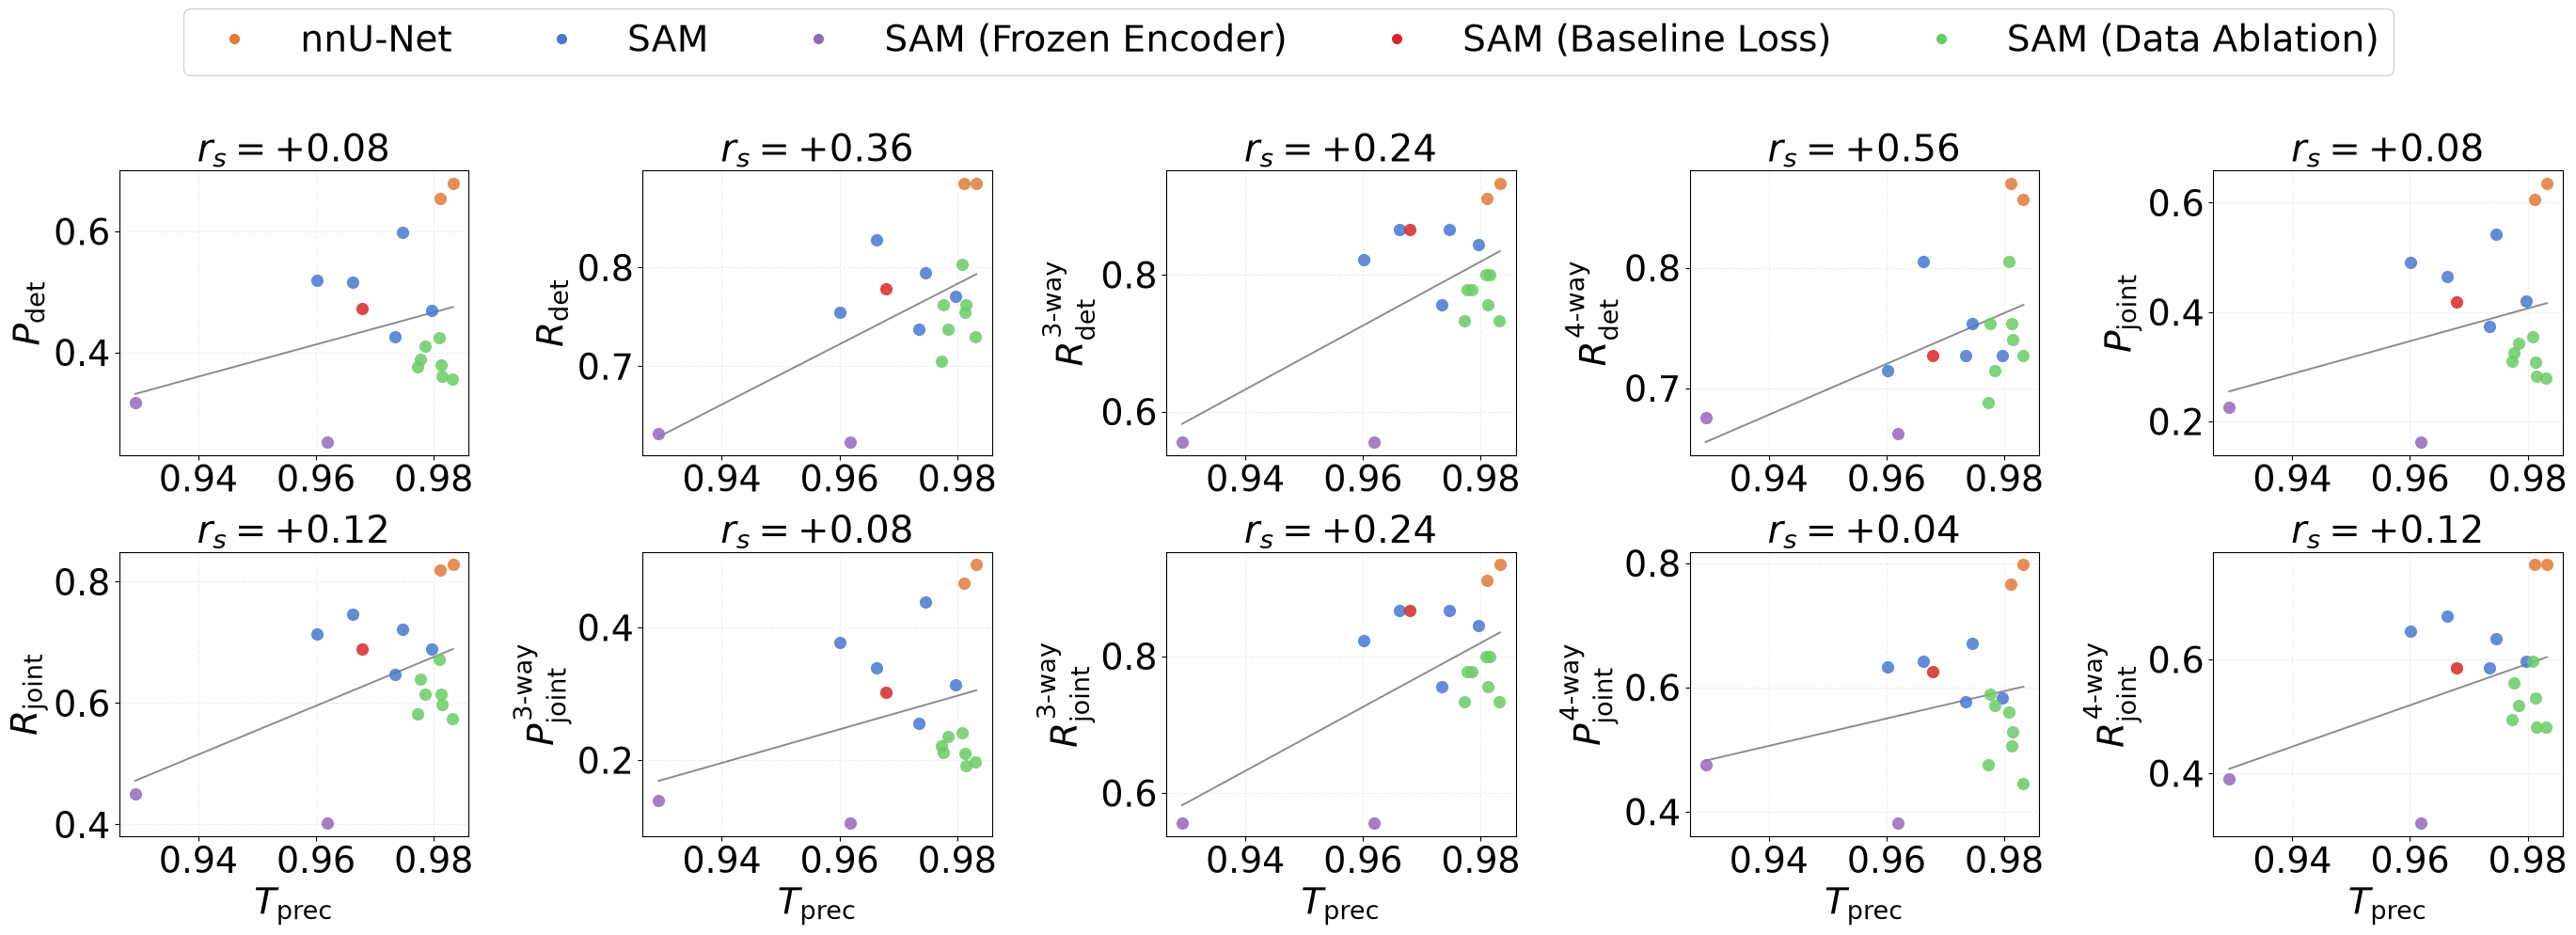

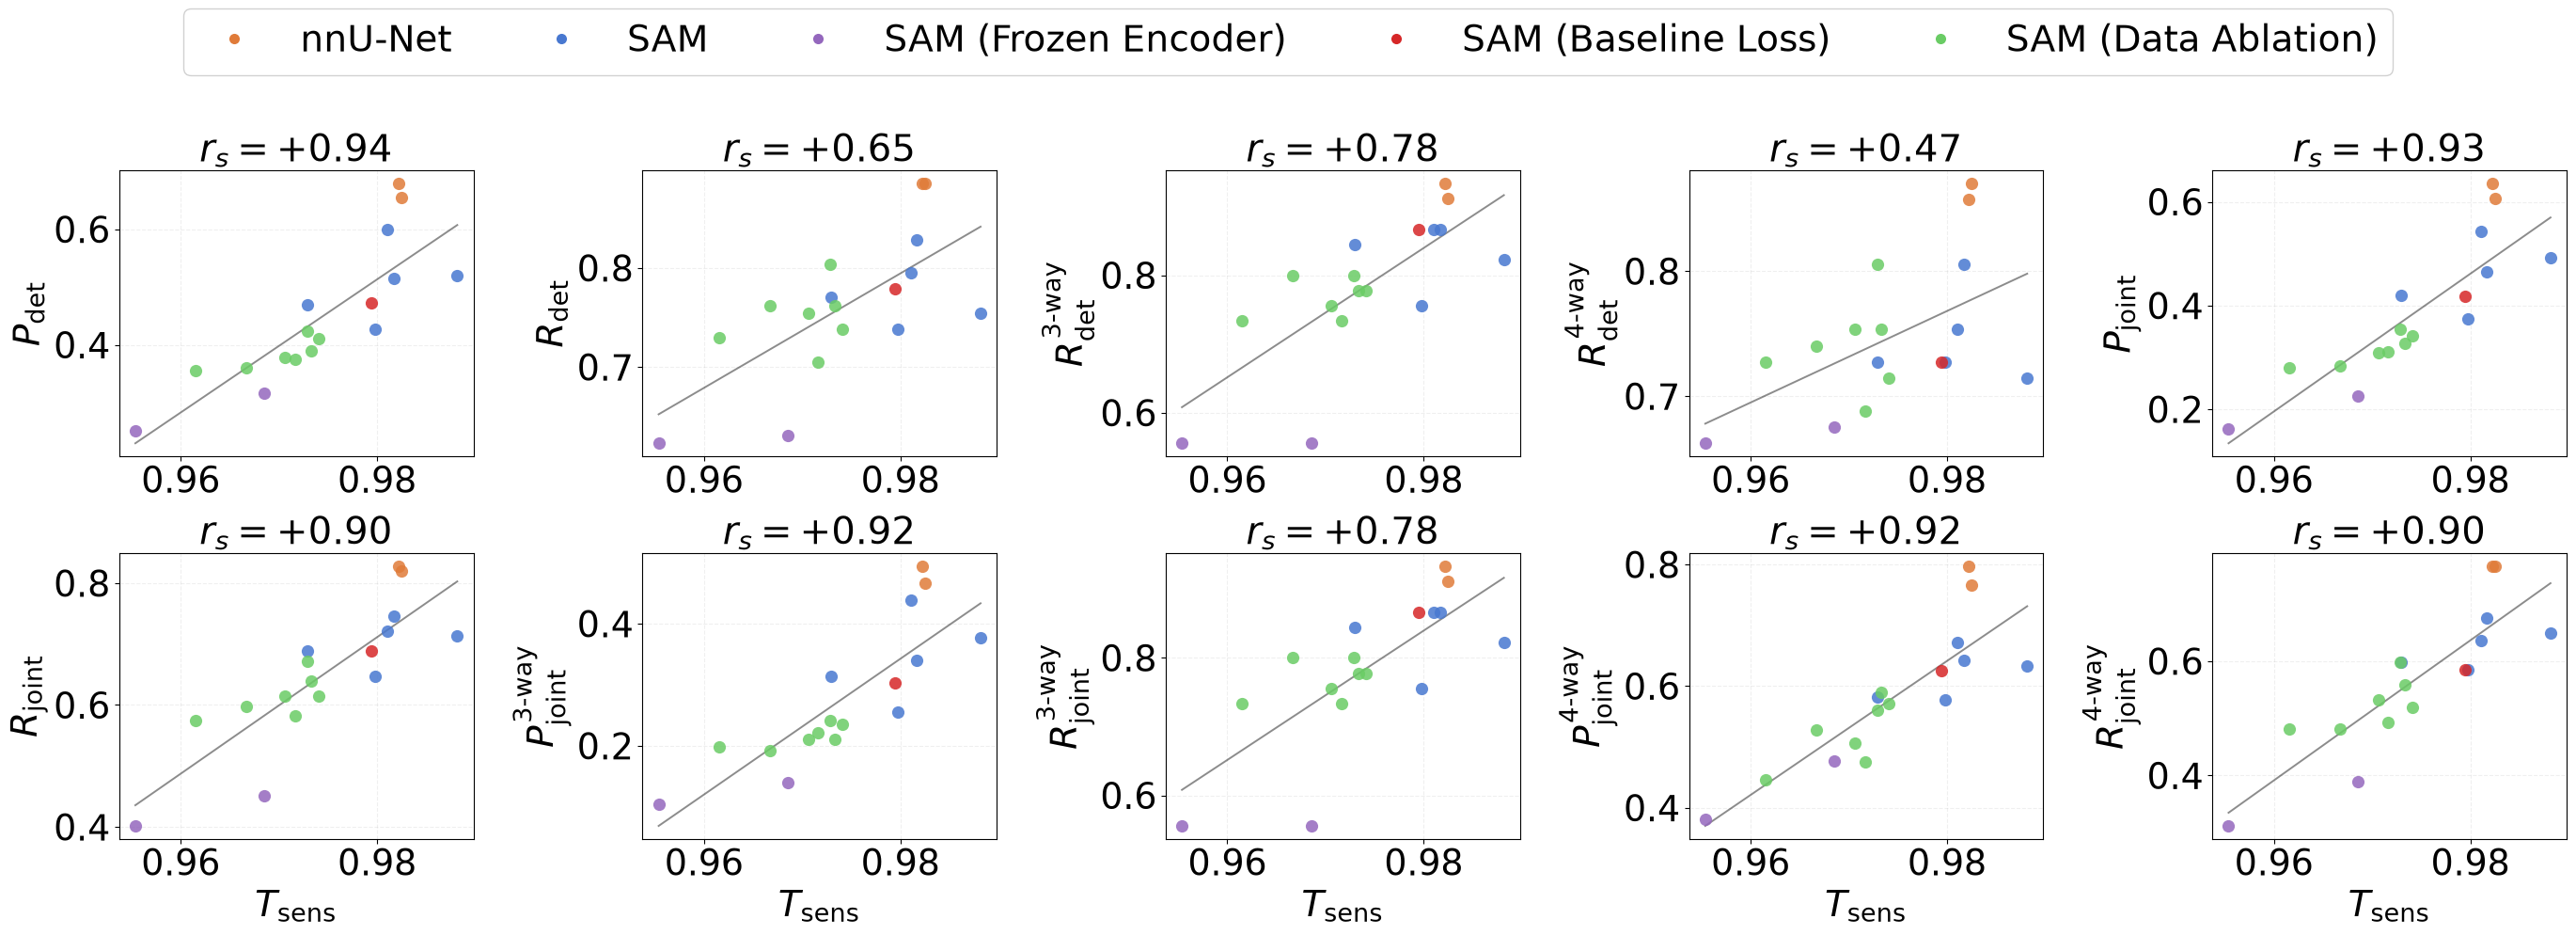

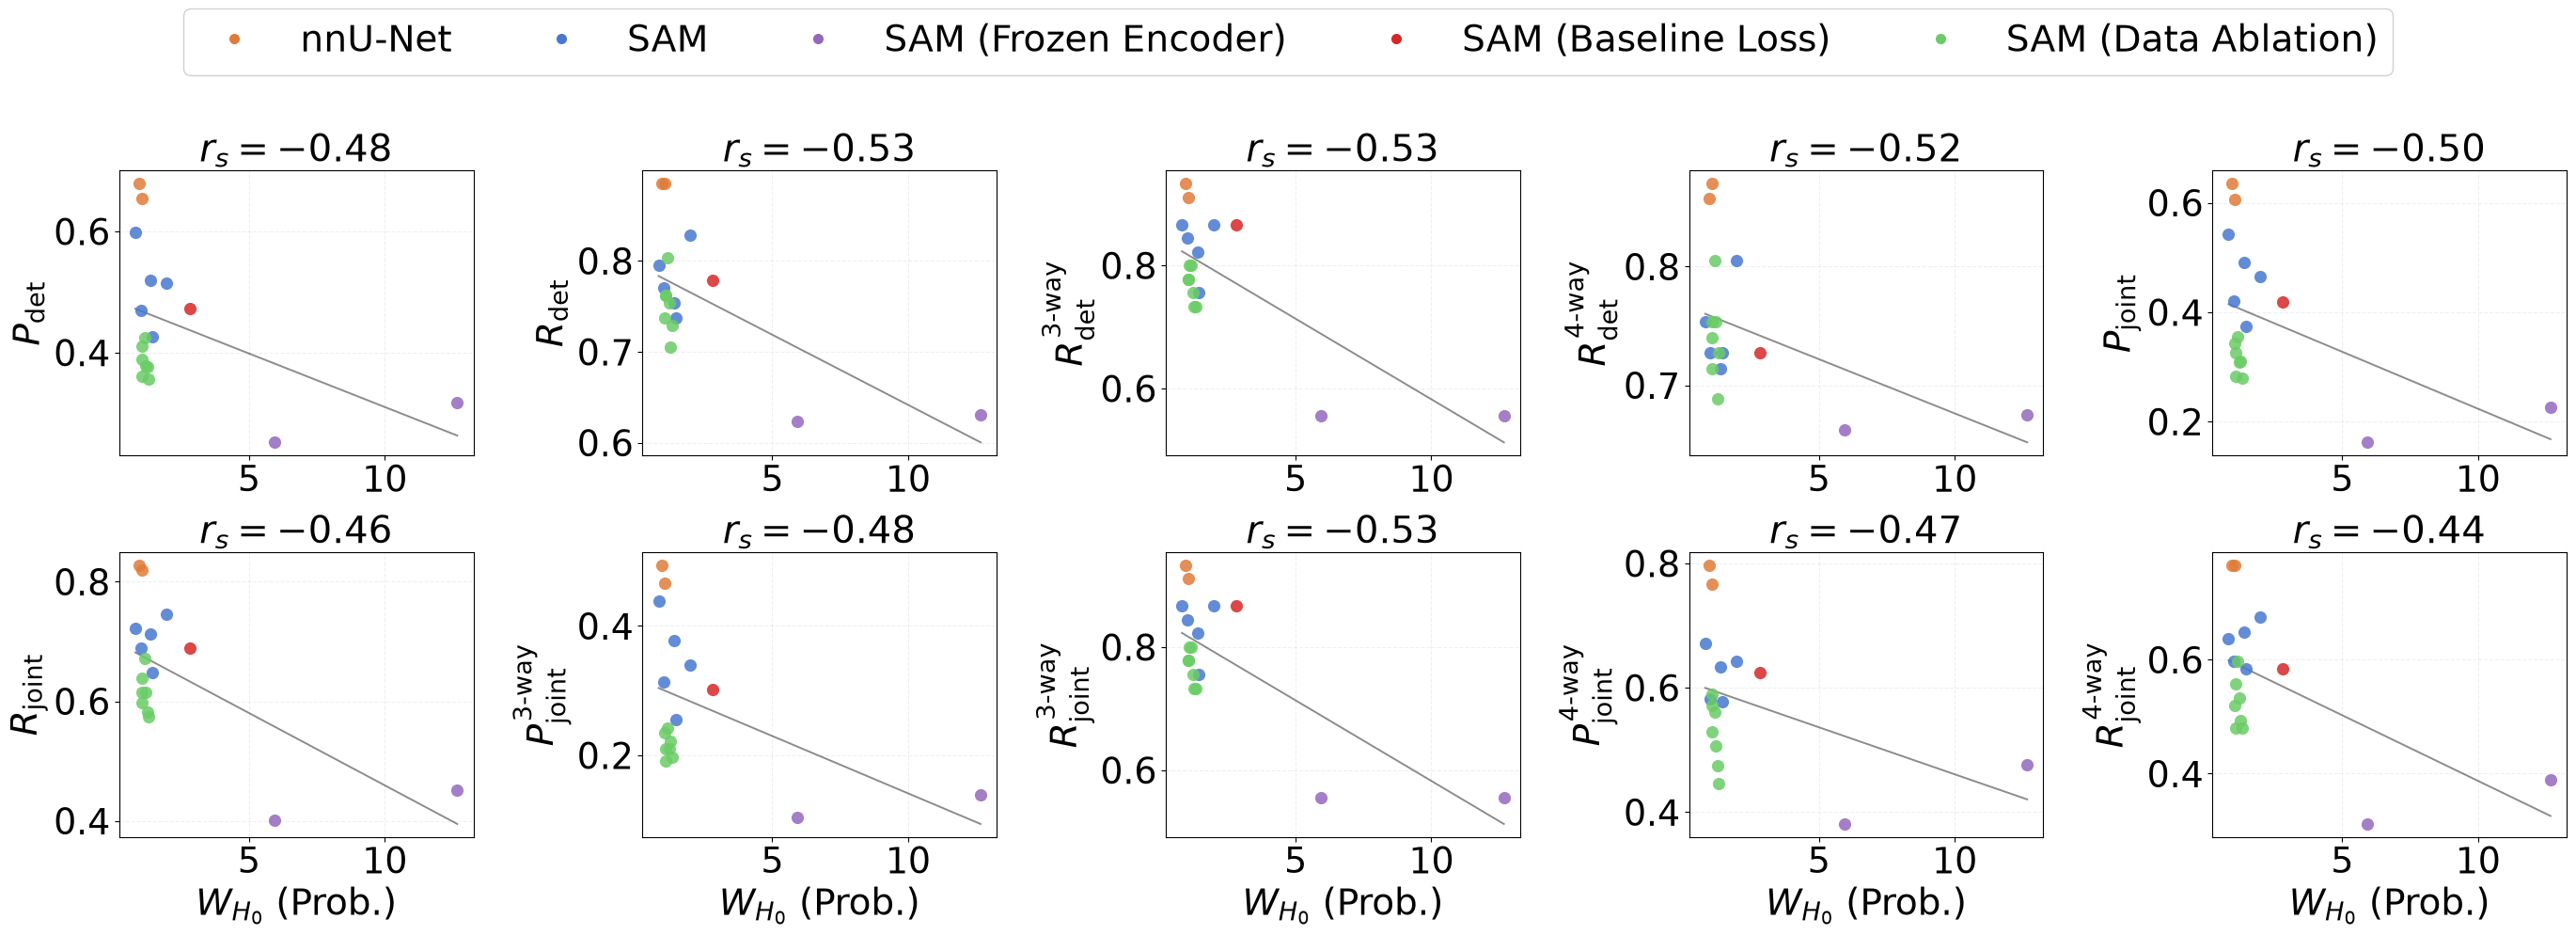

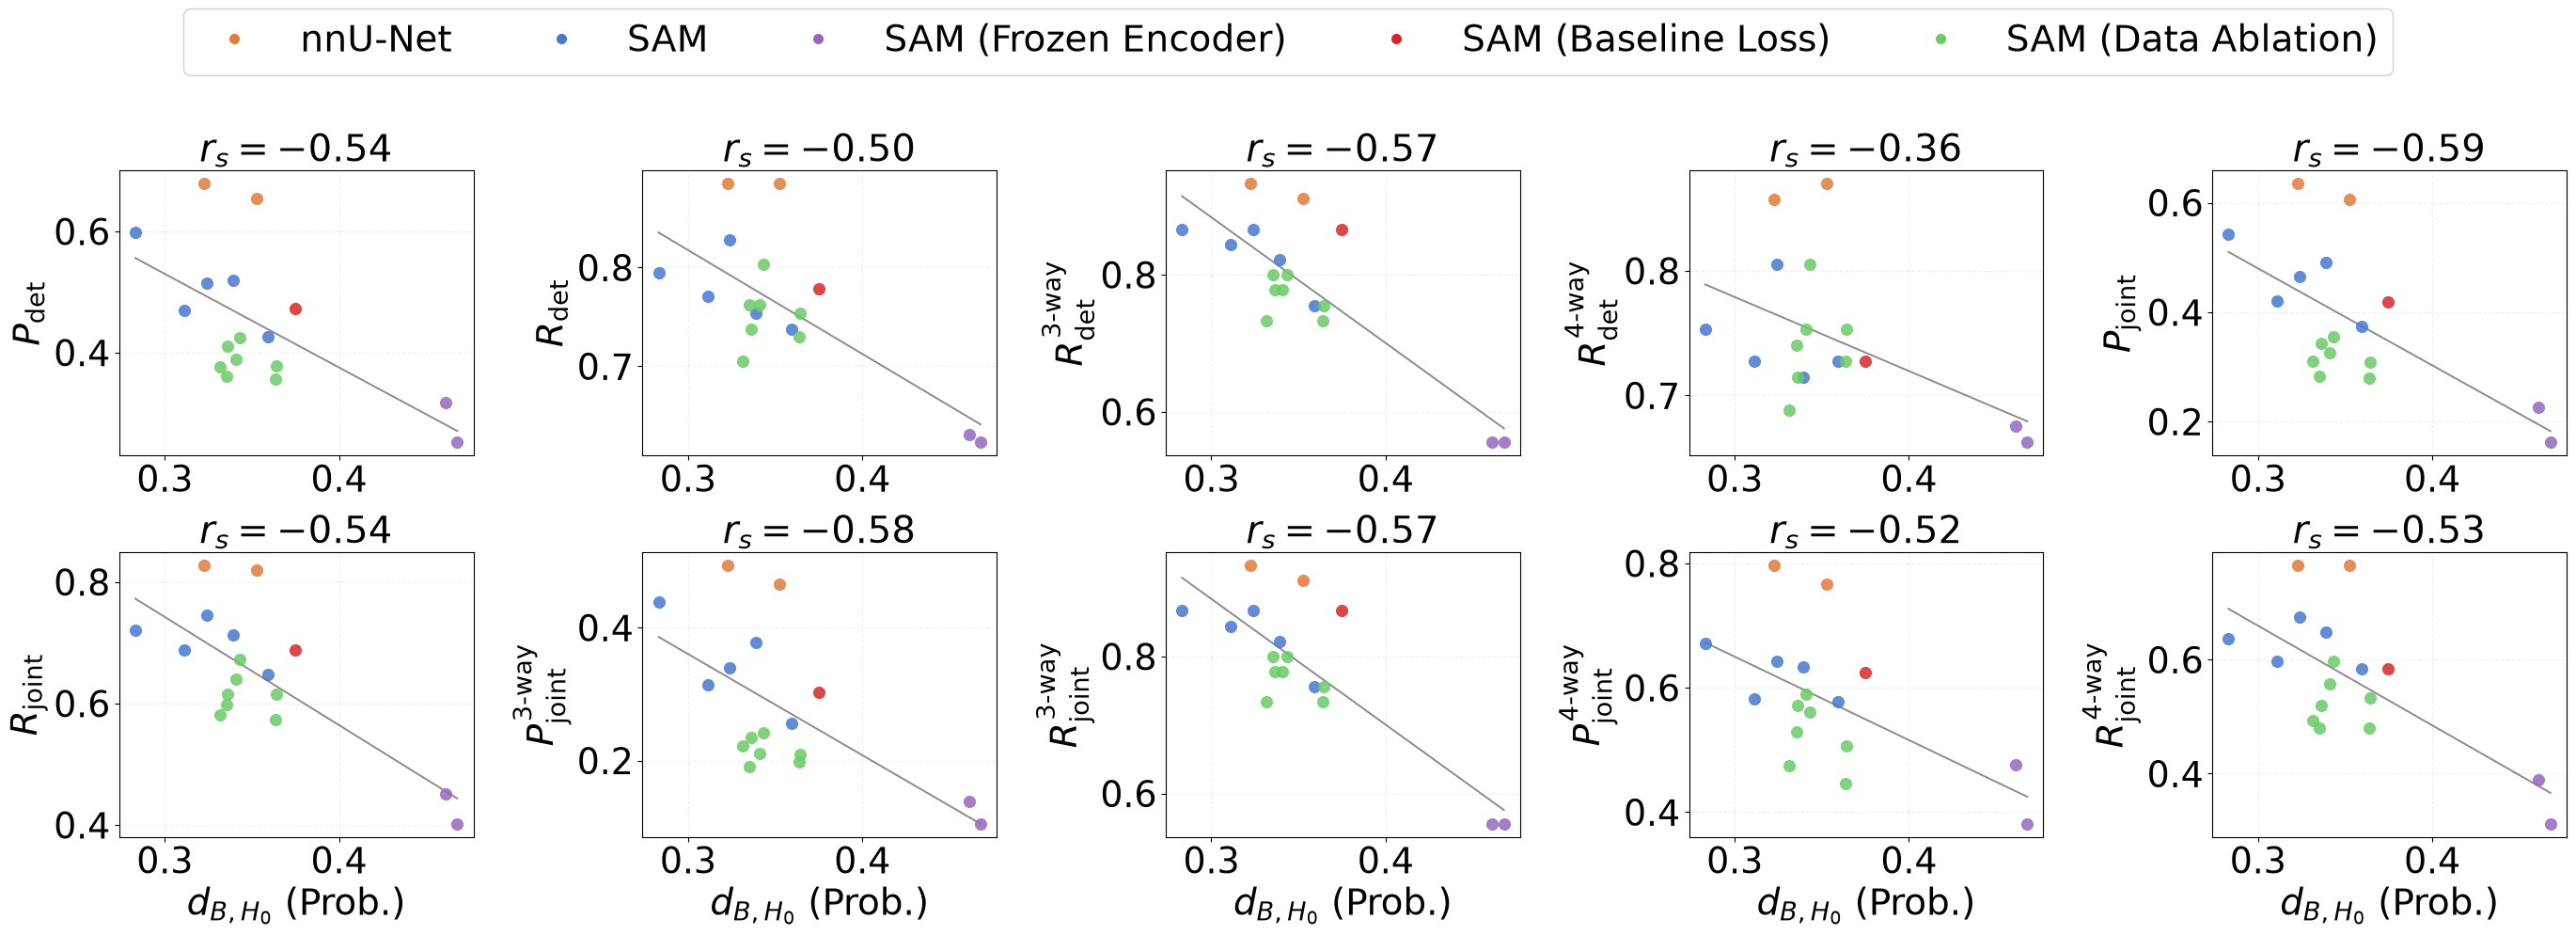

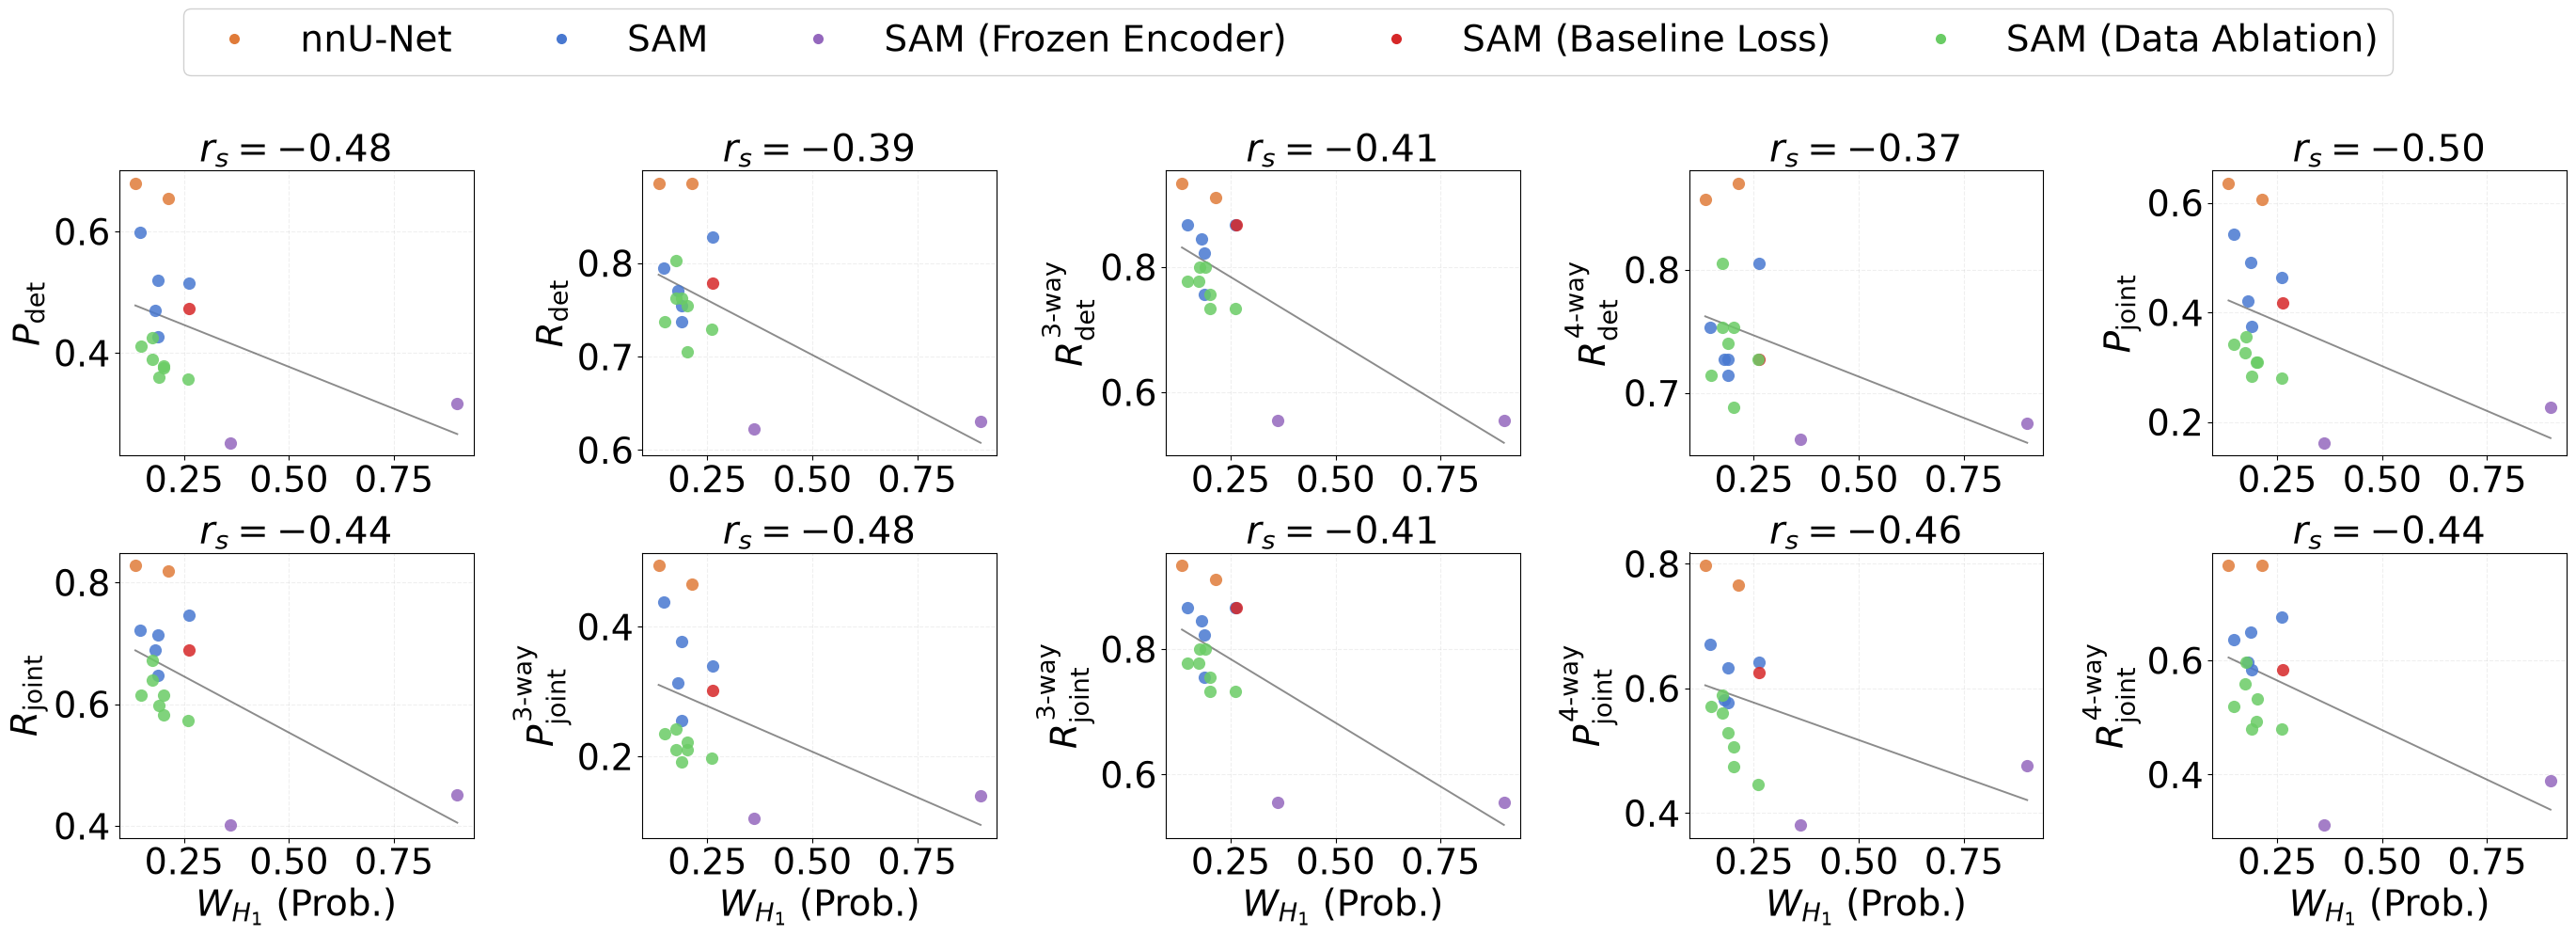

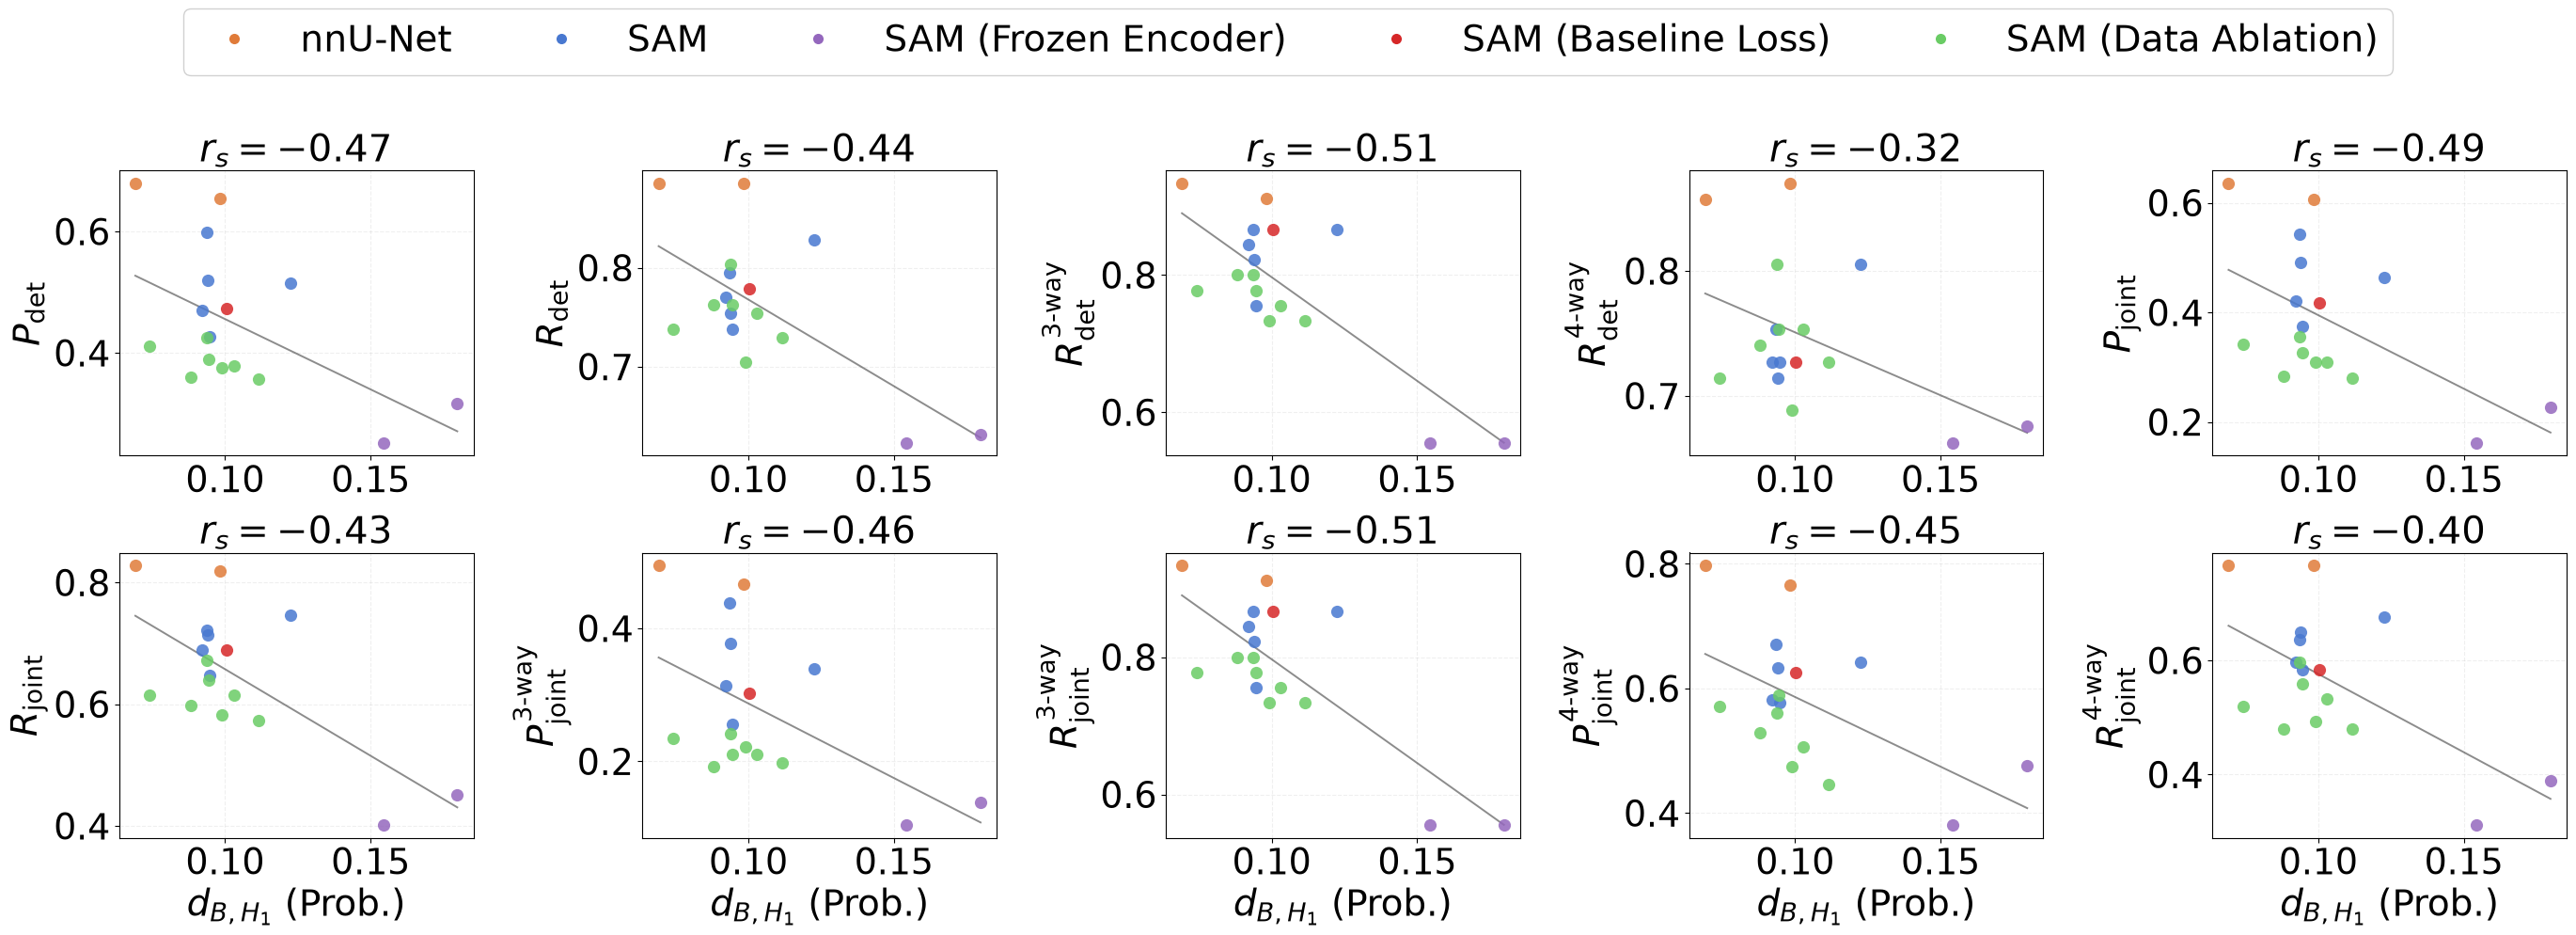

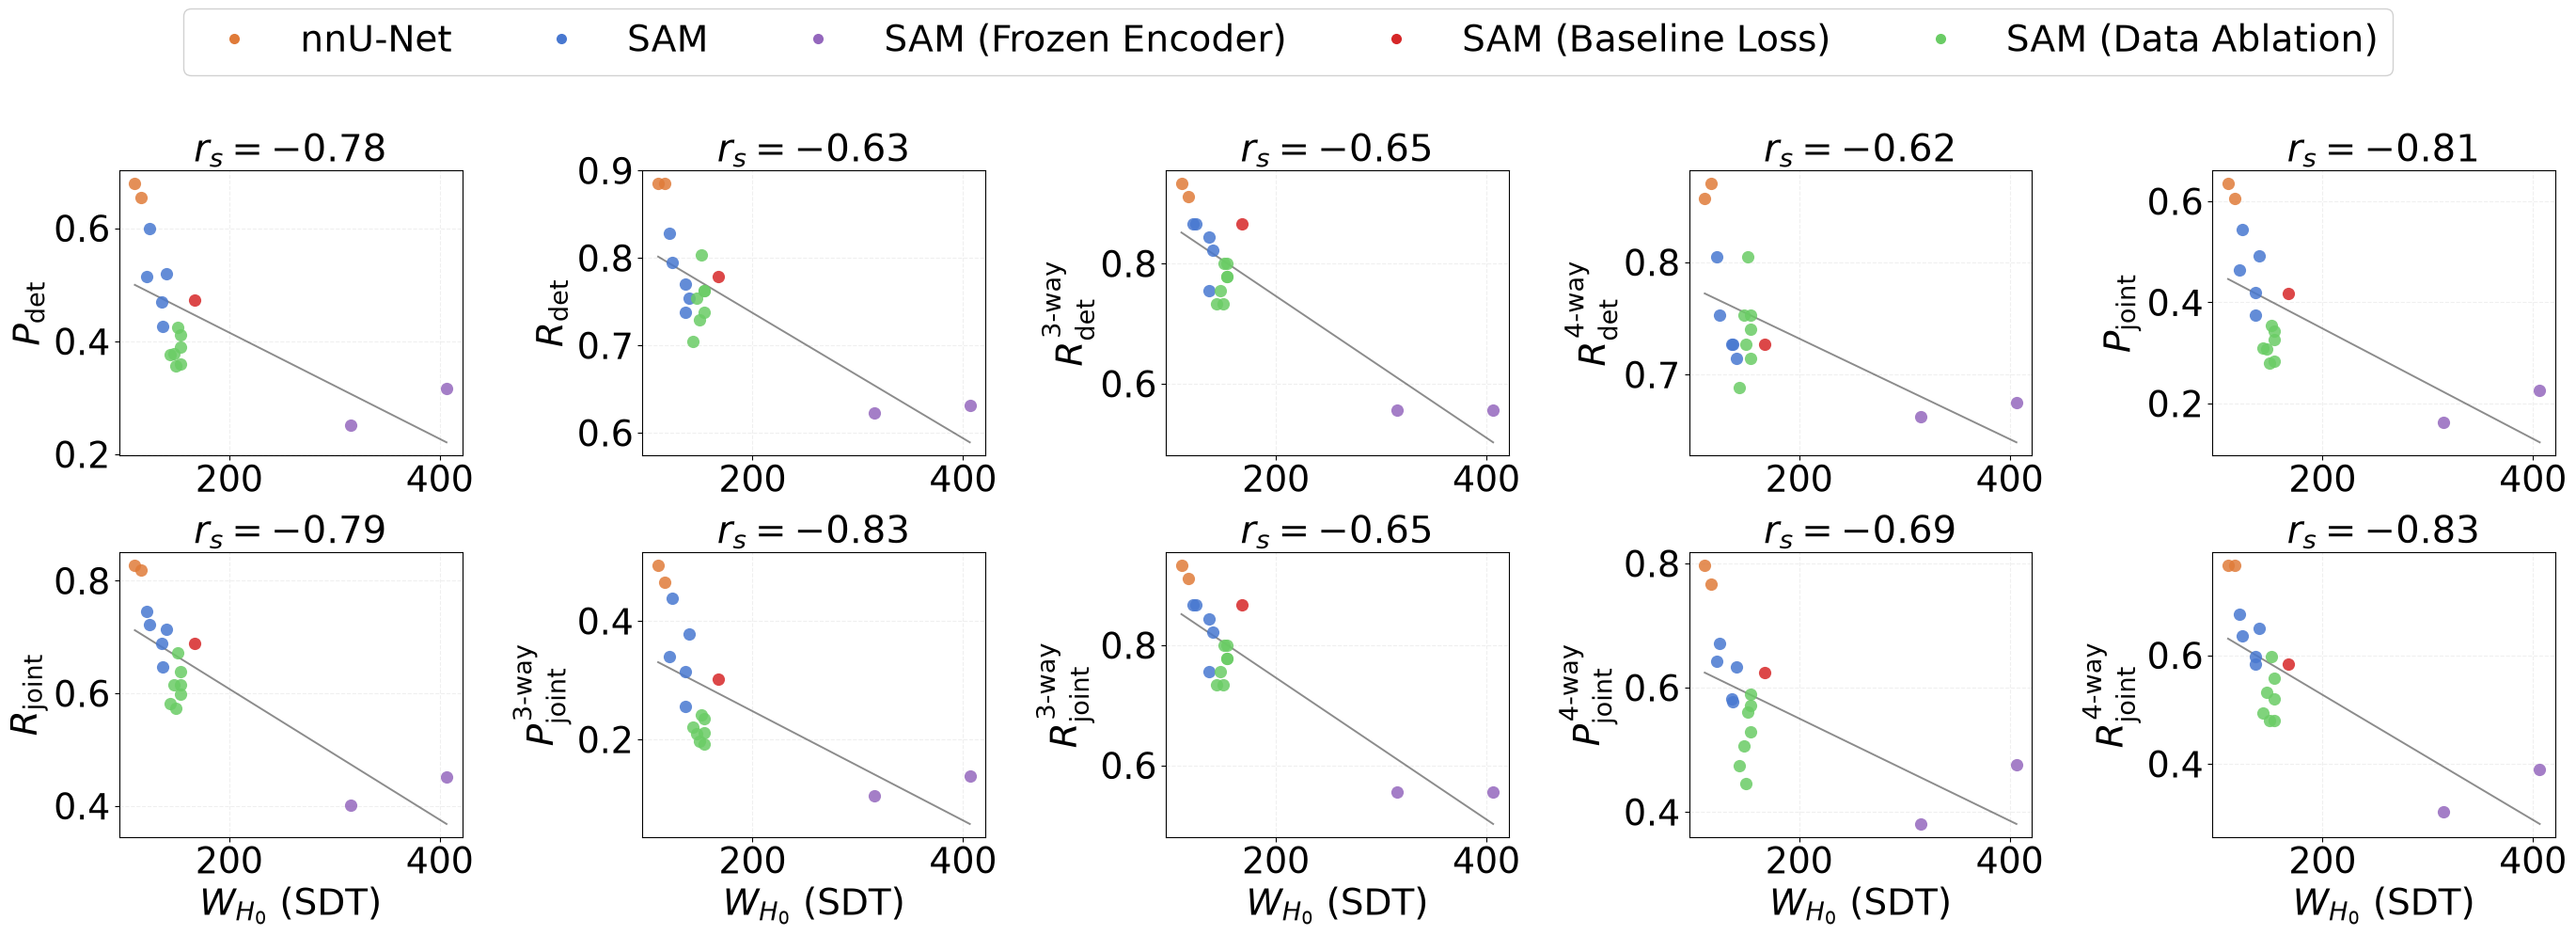

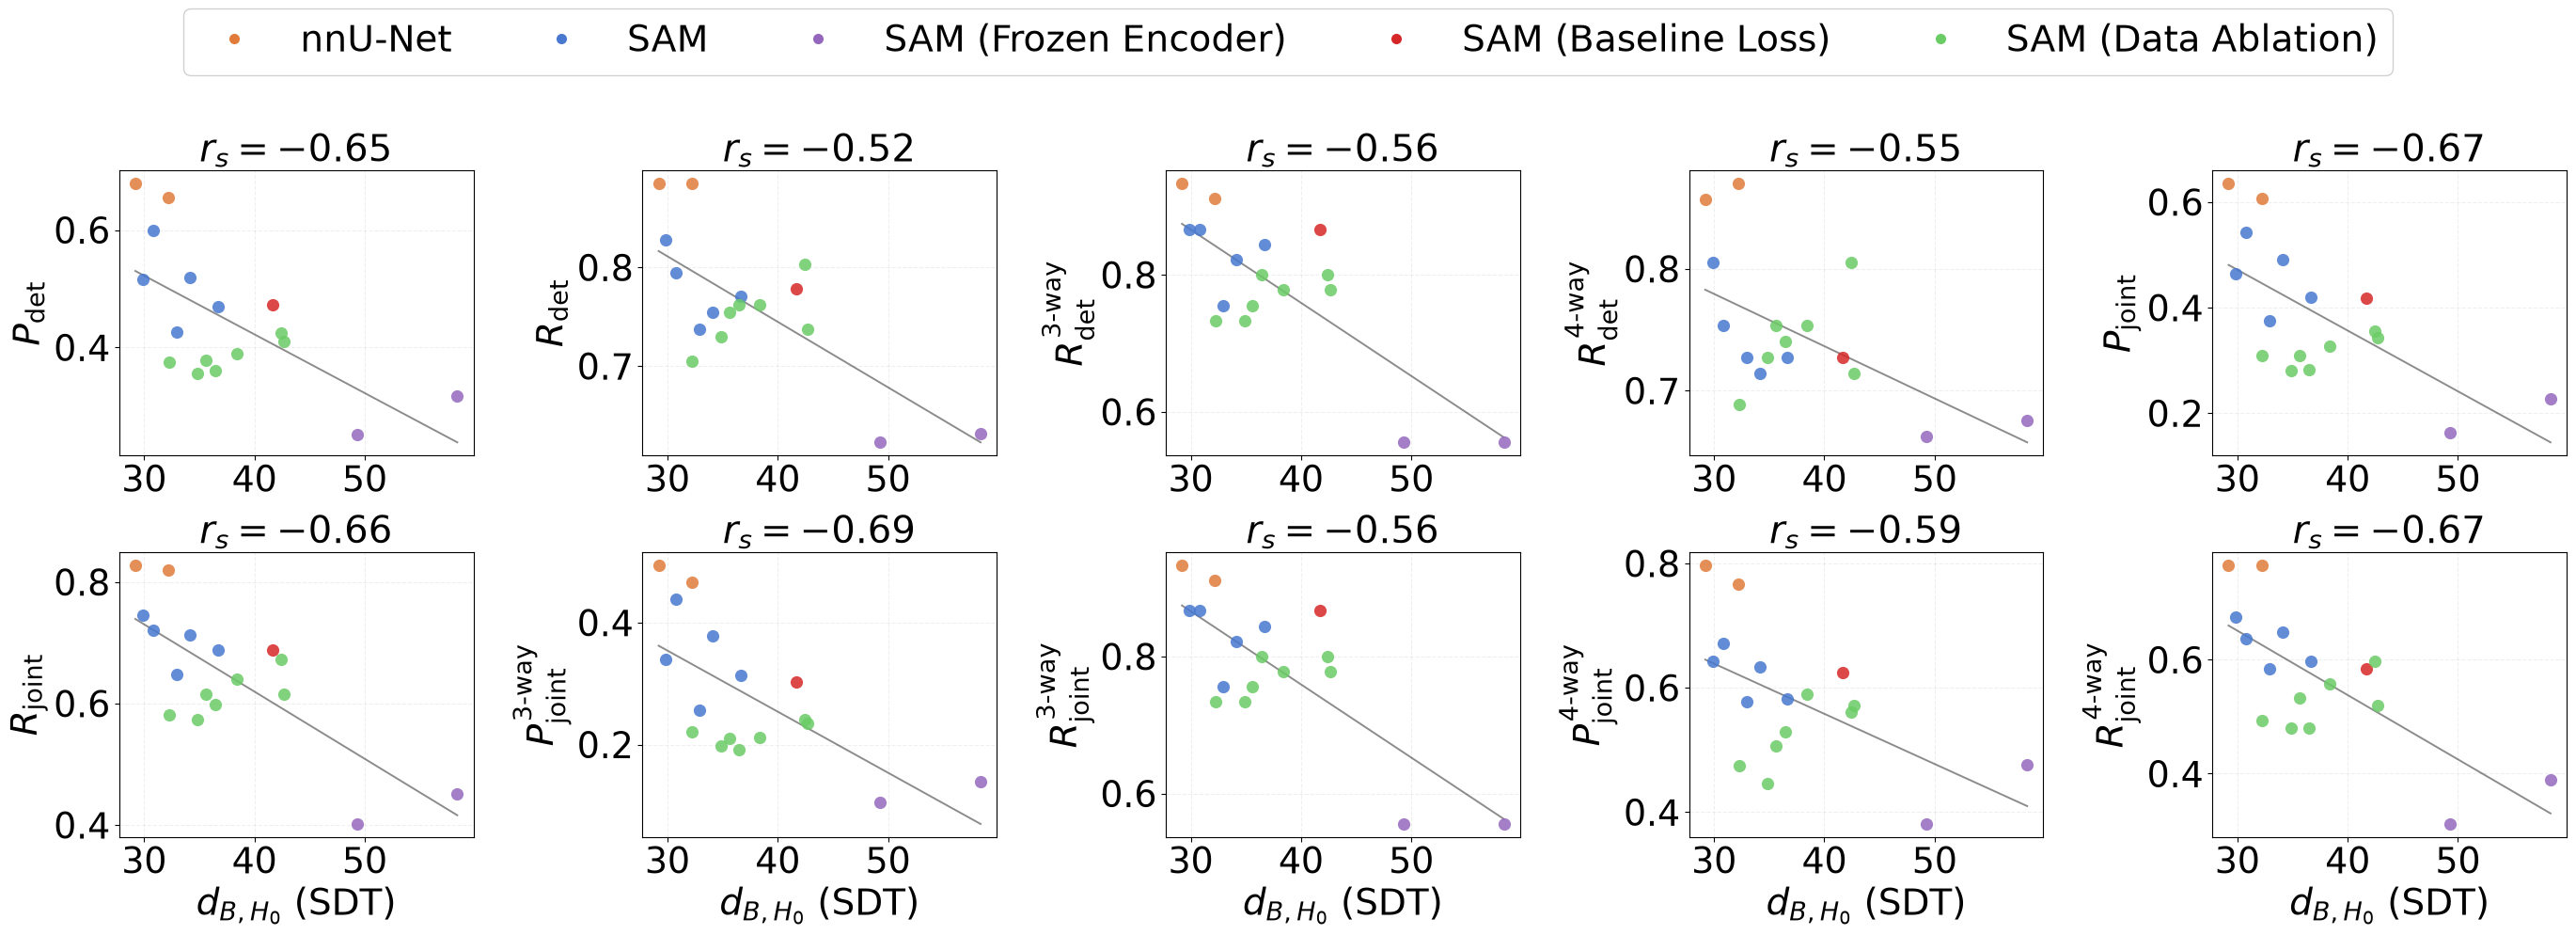

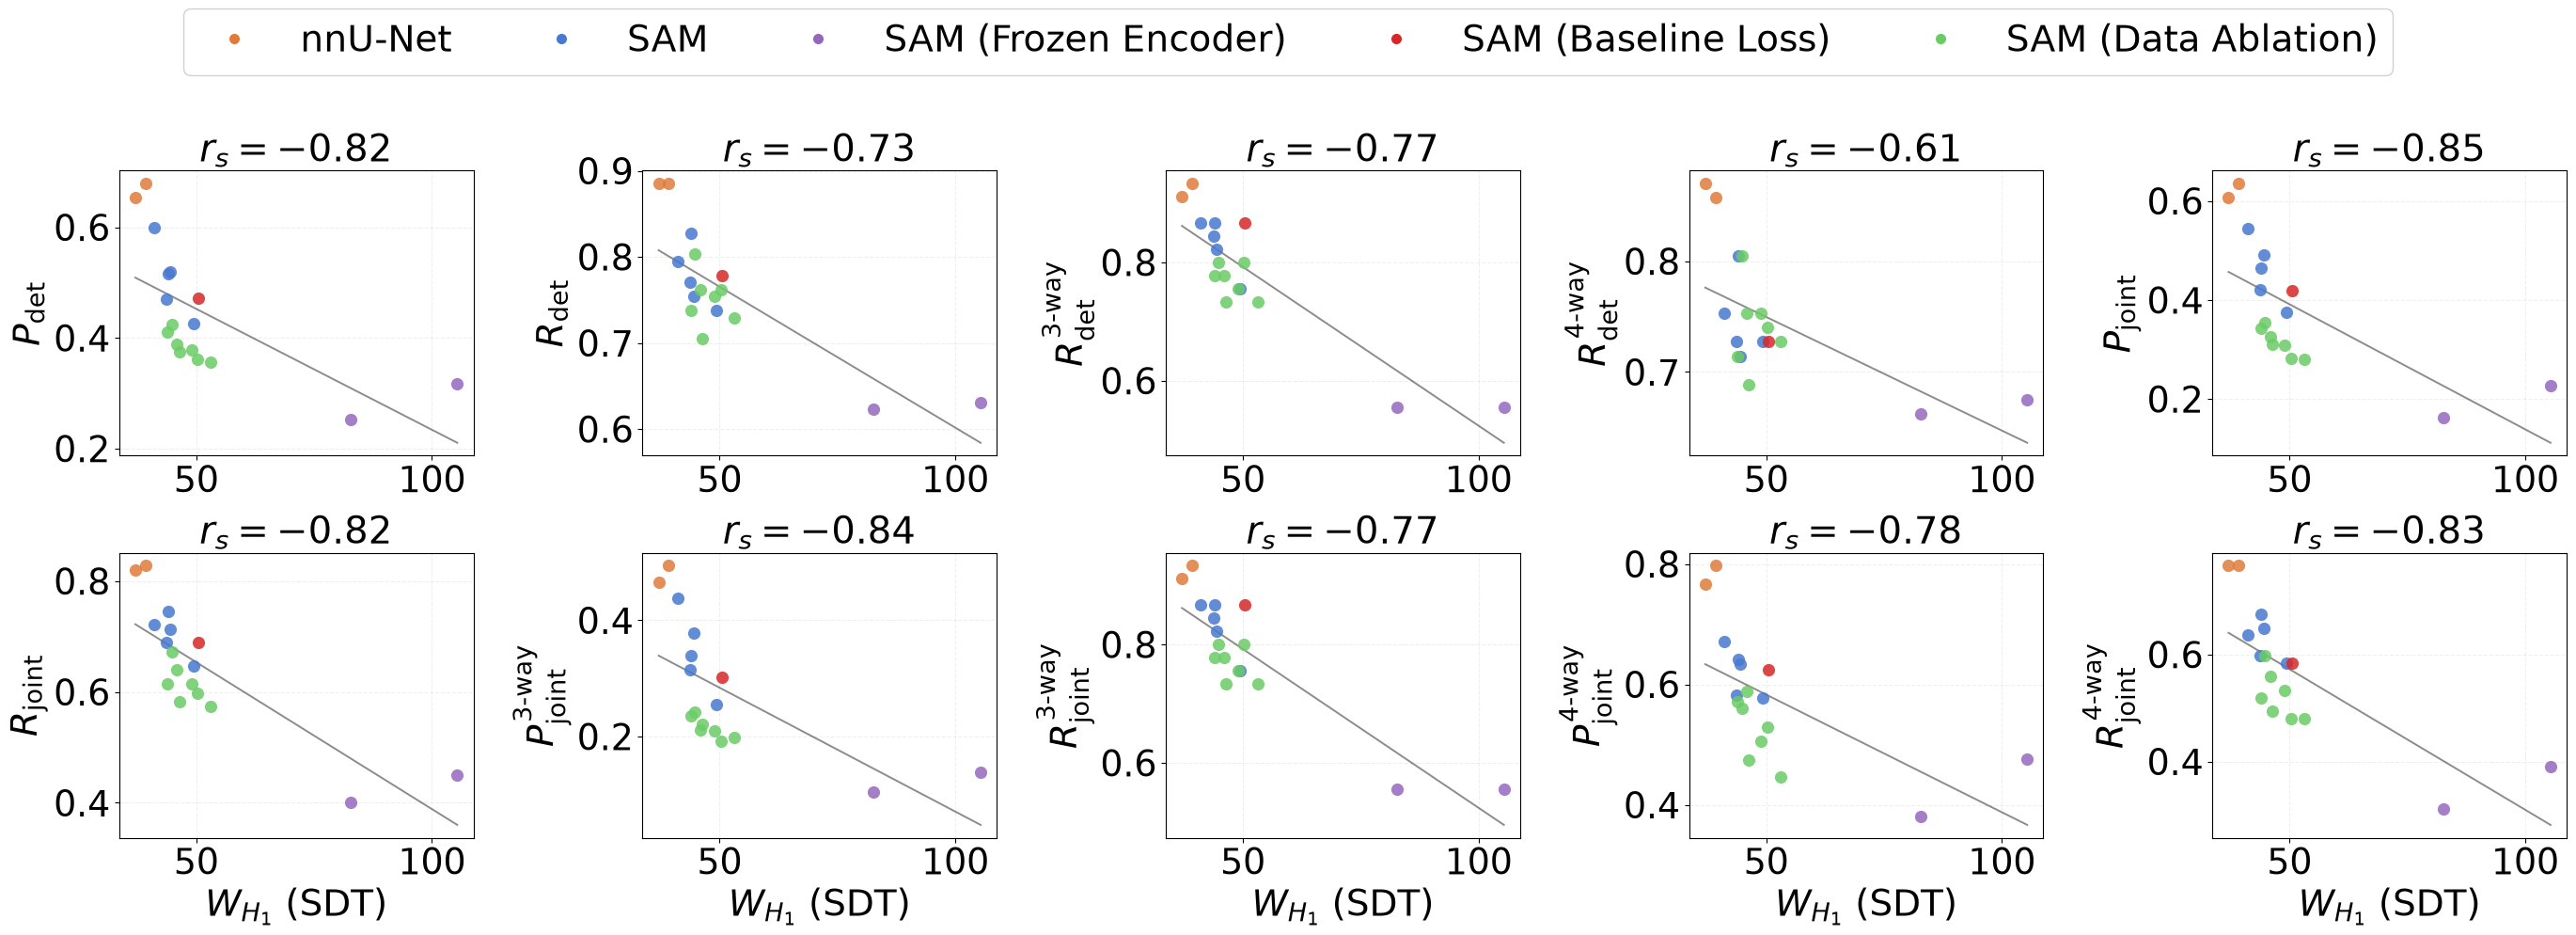

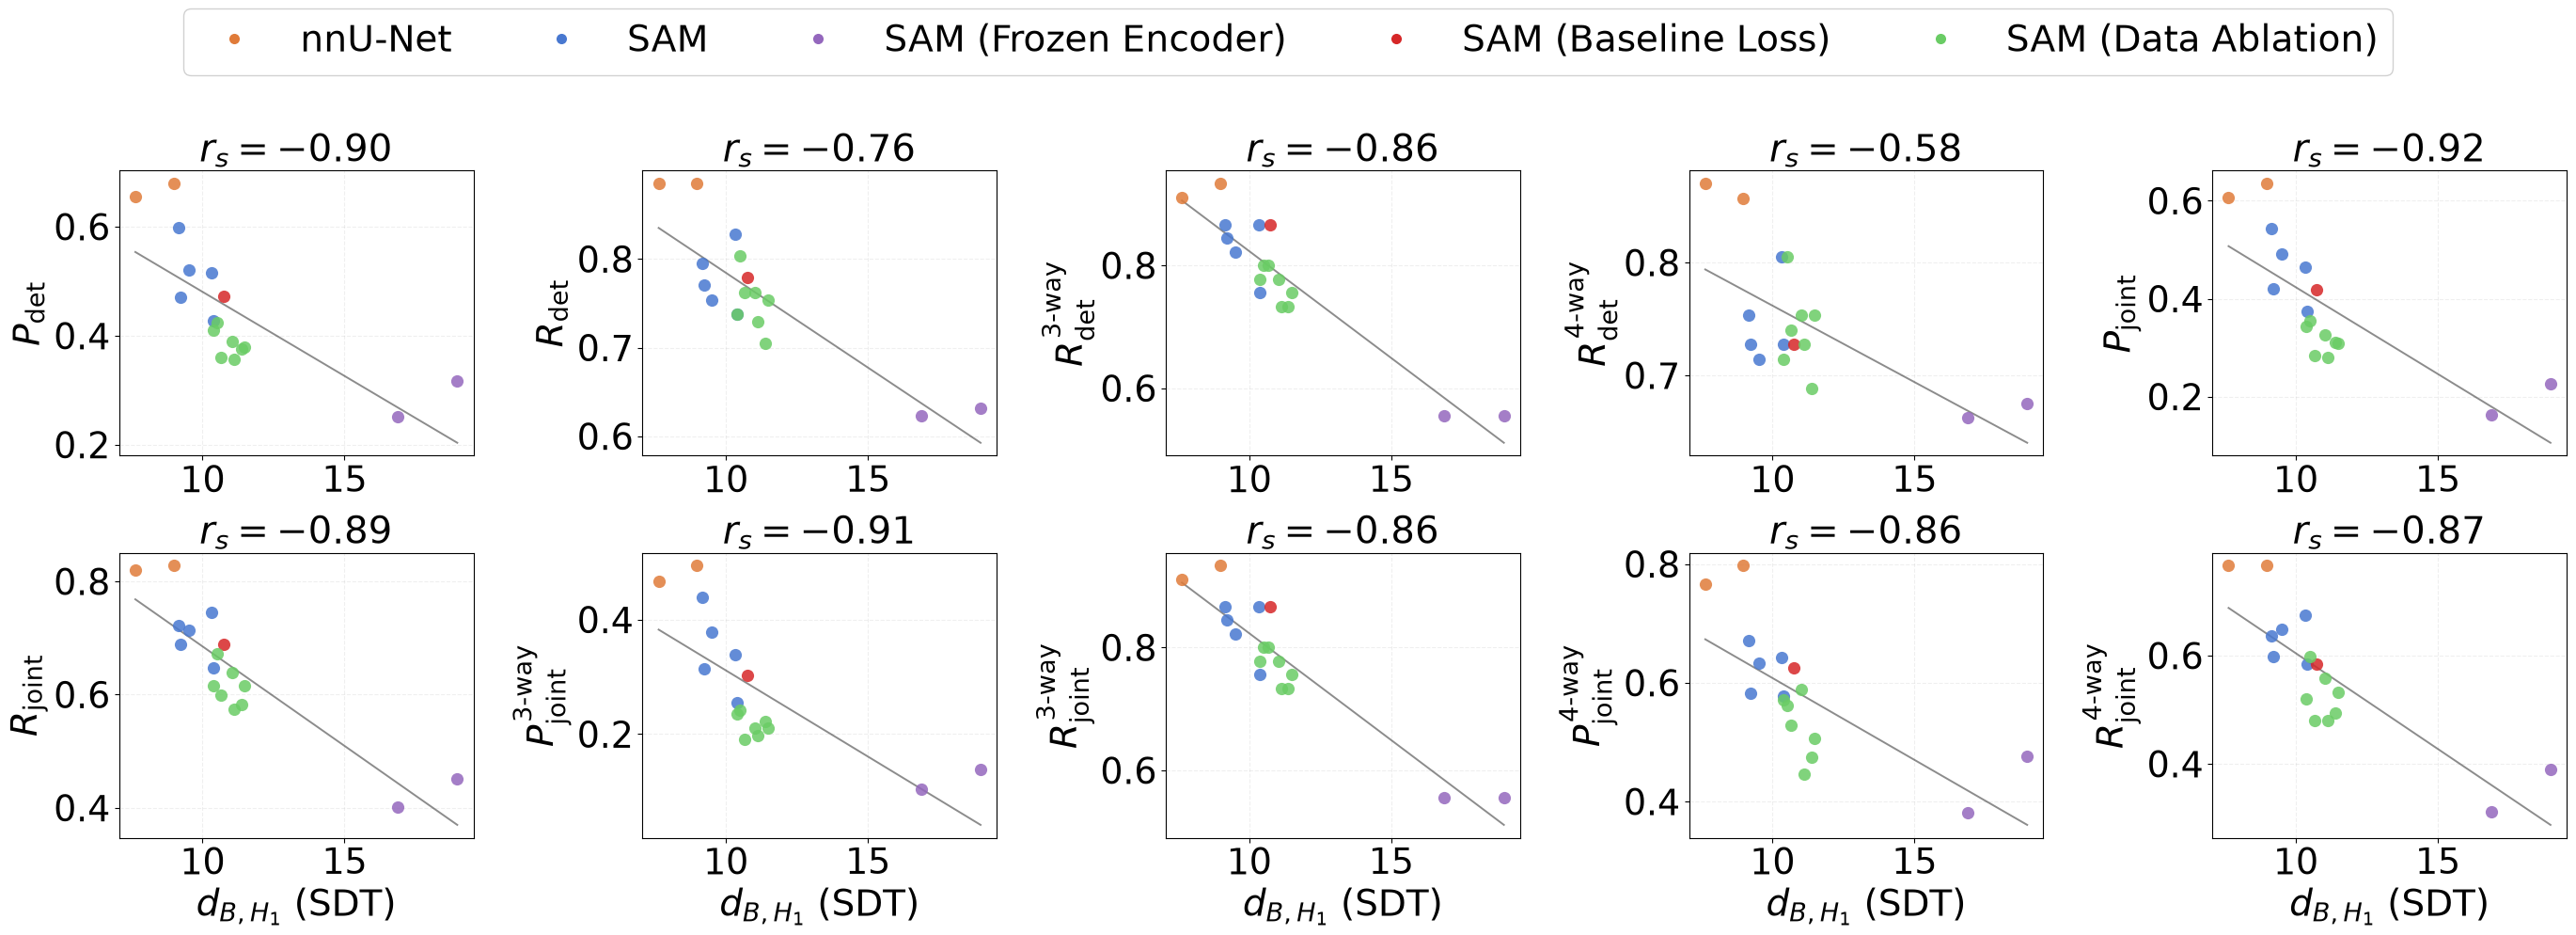

Saved 3 individual figure(s) to figures/correlation/individual


In [26]:
from matplotlib.lines import Line2D as _Line2D

_INDIVIDUAL_PAIRS = [
    [
        ("tsens", "pp_precision_loc"),
        ("tsens", "pp_class_precision_combined"),
        ("tsens", "pp_class_precision_3way"),
    ],
    [
        ("Wasserstein B0 Raw", "pp_recall_loc"),
        ("Bottleneck B0 Raw", "pp_class_precision_combined"),
        ("Wasserstein B1 Raw", "pp_class_precision_combined"),
        ("Bottleneck B1 Raw", "pp_detection_recall_3way"),
        ("clDice", "pp_detection_recall_4way"),
    ],
    [
        ("Bottleneck B1 SDT", "pp_precision_loc"),
        ("Bottleneck B1 SDT", "pp_class_precision_combined"),
        ("Bottleneck B1 SDT", "pp_class_precision_3way"),
    ],   
]

_FONT = 28

_seg_items = list(SEG_CORR_COLS.items())
_jd_items  = list(ALL_JD_CORR_COLS.items())  # 10 JD metrics -> 2 rows x 5 cols

_N_JD_ROWS, _N_JD_COLS = 2, 5

_GROUP_COLORS = {
    "nnU-Net":                "#e07b39",
    "SAM":                    "#4878d0",
    "SAM (Frozen Encoder)":   "#9467bd",
    "SAM (Baseline Loss)":    "#d62728",
    "SAM (Data Ablation)":    "#6acc65",
}

_FROZEN_ENCODER_MODELS = {"sweep-cldice-BEST", "sweep-skeleton-recall-BEST"}

def _model_group(model):
    m = str(model)
    if "nnunet" in m.lower():
        return "nnU-Net"
    if m in _FROZEN_ENCODER_MODELS:
        return "SAM (Frozen Encoder)"
    if m == "SAM_LoRA_BCE_Dice_Only":
        return "SAM (Baseline Loss)"
    if "SAM_LoRA_Ablation" in m:
        return "SAM (Data Ablation)"
    return "SAM"

_legend_handles = [
    _Line2D([0], [0], marker="o", color="w", markerfacecolor=c,
            markersize=9, label=lbl)
    for lbl, c in _GROUP_COLORS.items()
]

_corr_fig_dir = Path("figures/correlation")
_corr_fig_dir.mkdir(parents=True, exist_ok=True)

_corr_individual_dir = Path("figures/correlation/individual")
_corr_individual_dir.mkdir(parents=True, exist_ok=True)

# ── Individual figures: each nested list becomes one figure ──────────────────
# Each entry is a list of (seg_col, jd_col) pairs (DataFrame column names).
# All pairs in a list are placed side-by-side in one figure with a shared legend.

def _plot_scatter(ax, seg_col, jd_col, font):
    """Draw scatter + OLS onto ax."""
    jd_label = ALL_JD_CORR_COLS.get(jd_col, jd_col)
    seg_label = SEG_CORR_COLS.get(seg_col, seg_col)
    seg_label_clean = seg_label.replace("\n(↓)", " (↓)")
    jd_latex_label = _LATEX_COL_HEADERS.get(jd_label, jd_label)

    valid = df_merged[[seg_col, jd_col]].dropna()
    x = valid[seg_col].values.astype(float)
    y = valid[jd_col].values.astype(float)

    for model, xi, yi in zip(valid.index, x, y):
        grp = _model_group(model)
        ax.scatter(xi, yi, s=90, color=_GROUP_COLORS[grp],
                   zorder=3, alpha=0.85, linewidths=0)

    if len(x) >= 3:
        slope, intercept, *_ = _scipy_stats.linregress(x, y)
        x_fit = np.linspace(x.min(), x.max(), 100)
        ax.plot(x_fit, slope * x_fit + intercept,
                color="black", lw=1.4, alpha=0.45, zorder=2)
        rho, _ = _scipy_stats.spearmanr(x, y)
        ax.set_title(f"$r_s = {rho:+.2f}$", fontsize=font + 1, pad=4)
    else:
        ax.set_title("n < 3", fontsize=font + 1, pad=4)

    ax.set_ylabel(jd_latex_label, fontsize=font)
    ax.set_xlabel(seg_label_clean, fontsize=font)
    ax.tick_params(labelsize=font - 1)
    ax.grid(True, alpha=0.2, linestyle="--")

# ── Main grid plots (one figure per seg metric) ───────────────────────────────
for seg_col, seg_label in _seg_items:
    seg_slug = seg_col.replace(" ", "_").replace("/", "_")

    fig, axes = plt.subplots(_N_JD_ROWS, _N_JD_COLS,
                             figsize=(5.5 * _N_JD_COLS, 4.5 * _N_JD_ROWS),
                             squeeze=False)

    for i, (jd_col, jd_label) in enumerate(_jd_items):
        row, col = i // _N_JD_COLS, i % _N_JD_COLS
        ax = axes[row, col]
        _plot_scatter(ax, seg_col, jd_col, _FONT)
        if row != _N_JD_ROWS - 1:
            ax.set_xlabel("")

    fig.legend(handles=_legend_handles, loc="lower center",
               bbox_to_anchor=(0.5, 1.0), ncol=5,
               fontsize=_FONT, framealpha=0.9)
    plt.tight_layout(rect=[0, 0, 1, 0.97], w_pad=3.0)
    fig.savefig(_corr_fig_dir / f"correlation_{seg_slug}.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

# ── Individual figures: one figure per nested list ────────────────────────────
for fig_idx, pairs in enumerate(_INDIVIDUAL_PAIRS):
    valid_pairs = [(s, j) for s, j in pairs
                   if s in df_merged.columns and j in df_merged.columns]
    if not valid_pairs:
        print(f"  Figure {fig_idx}: no valid pairs, skipping.")
        continue

    n = len(valid_pairs)
    fig_ind, axes_ind = plt.subplots(1, n, figsize=(5.5 * n, 4.5), squeeze=False)

    for ax, (seg_col, jd_col) in zip(axes_ind[0], valid_pairs):
        _plot_scatter(ax, seg_col, jd_col, _FONT)

    fig_ind.legend(handles=_legend_handles, loc="lower center",
                   bbox_to_anchor=(0.5, 1.0), ncol=min(n * 2, 5),
                   fontsize=_FONT - 2, framealpha=0.9)
    plt.tight_layout(rect=[0, 0, 1, 0.93], w_pad=3.0)

    # Filename from the pairs in this figure
    slug = "__".join(
        f"{s.replace(' ', '_')}_{j.replace('pp_', '').replace(' ', '_')}"
        for s, j in valid_pairs
    )
    fig_ind.savefig(_corr_individual_dir / f"corr_{fig_idx:02d}.png",
                    dpi=150, bbox_inches="tight")
    plt.close()

print(f"Saved {len(_INDIVIDUAL_PAIRS)} individual figure(s) to {_corr_individual_dir}")
